In [4]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [5]:
#combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_s1_5000_GBIF_wcvp.csv") 
combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10.csv") 

combined_results_gbif

region,biome_number,biome_name,realm_abbrev,realm_name,mean_perc_change_PC1,median_perc_change_PC1,mean_perc_change_PC2,median_perc_change_PC2,significance_PC1,significance_PC2,significance_PC3,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3,average_perc_naturalized
<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>
10_AT,10,Montane Grasslands & Shrublands,AT,Afrotropical,25.1242622,29.9521348,89.409950,103.448767,,*,***,0.086388889,0.26194444,0.43583333,negligible,small,large,28.134167
12_AA,12,"Mediterranean Forests, Woodlands & Scrub",AA,Australasia,-45.1279883,-25.3650246,10.772227,11.459533,,*,,-0.086122449,0.27224490,0.07632653,negligible,small,negligible,7.872721
12_PA,12,"Mediterranean Forests, Woodlands & Scrub",PA,Palearctic,36.5146702,39.6651678,53.877318,66.534510,***,,,0.336445312,0.08339844,0.04769531,medium,negligible,negligible,14.492500
12_NA,12,"Mediterranean Forests, Woodlands & Scrub",NA,Nearctic,-28.2237980,-12.5524006,76.154348,58.574562,,*,,-0.404958678,0.61983471,0.47107438,medium,large,large,21.273259
13_IM,13,Deserts & Xeric Shrublands,IM,Indomalaya,2.9381874,-3.1917696,183.199789,631.866244,,**,,-0.003380206,0.30624662,0.13967009,negligible,medium,small,41.701542
13_NA,13,Deserts & Xeric Shrublands,NA,Nearctic,-14.5476947,-20.4248286,19.944665,18.509465,,*,,-0.066909422,0.15941319,0.13623473,negligible,small,small,9.927191
13_NT,13,Deserts & Xeric Shrublands,NT,Neotropical,5.7347359,10.9591217,309.302035,519.823060,,,*,0.033910035,0.20664360,0.23903114,negligible,small,small,22.448070
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-21.2883720,-24.6663728,17.788739,23.500696,***,**,***,-0.211565494,0.13155977,0.22283684,small,small,small,38.040570
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropic,-2.8778945,-4.1650131,25.992187,32.317979,,**,**,-0.018750113,0.13787574,0.13657687,negligible,small,small,16.589209


In [7]:
dim(combined_results_gbif)

[1] 21 19

# Plot different PCA regions into one plot

In [7]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [8]:
# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")
print(wwf_aggregated)

Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_AN MULTIPOLYGON (((-66.89195 -...
8    11_NA MULTIPOLYGON (((-42.17305 6...
9    11_PA MULTIPOLYGON (((149.4331 68...
10   12_AA MULTIPOLYGON (((122.7533 -3...


In [9]:
get_list_of_regions <- function(data) {
    unique(data$region)
}

regions_gbif <- get_list_of_regions(combined_results_gbif)

#merged_regions <- union(regions_cs, regions_gbif)
merged_regions <- regions_gbif


print(merged_regions)

 [1] "10_AT" "12_AA" "12_PA" "12_NA" "13_IM" "13_NA" "13_NT" "1_IM"  "1_NT" 
[10] "2_IM"  "2_NT"  "4_AA"  "4_NA"  "4_NT"  "5_NA"  "6_NA"  "7_AA"  "7_AT" 
[19] "7_NT"  "8_NA"  "8_NT" 


In [9]:
# Print ippc_srex for merged regions
library(dplyr)

# Check column names of wwf_aggregated
print(colnames(wwf_aggregated))

# Add NEU to merged regions
# merged_regions <- c("ARO", "NSA", "SAM", "NWS", "BOB", "EPO")
merged_regions_sf <- wwf_aggregated %>%
    filter(bim_rlm %in% merged_regions) %>%
    select(bim_rlm)  # Adjust the column selection based on the actual column names

print(merged_regions_sf)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] "bim_rlm"  "geometry"
Simple feature collection with 21 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -176.8495 ymin: -55.97751 xmax: 178.5655 ymax: 69.00631
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AT MULTIPOLYGON (((34.56465 1....
2    12_AA MULTIPOLYGON (((122.7533 -3...
3    12_NA MULTIPOLYGON (((-118.3031 2...
4    12_PA MULTIPOLYGON (((-17.98157 2...
5    13_IM MULTIPOLYGON (((79.71922 9....
6    13_NA MULTIPOLYGON (((-112.2396 2...
7    13_NT MULTIPOLYGON (((-75.58071 1...
8     1_IM MULTIPOLYGON (((72.92915 3....
9     1_NT MULTIPOLYGON (((-44.30449 -...
10    2_IM MULTIPOLYGON (((94.77231 23...


In [10]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean_group.csv")#
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean_group.csv")
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10.csv")


head(combined_data)



Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last




h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,


In [11]:
# combined_data - new row with percent_naturalized based on column count fro group=all and group=native
combined_data <- combined_data %>%
    group_by(h3_res3) %>%
    mutate(
        perc_naturalized = ifelse(
            any(group == "all") & any(group == "native"),
            (count[group == "all"] - count[group == "native"]) / count[group == "all"] * 100,
            NA
        )
        )
head(combined_data)


h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA,29.16261
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA,29.16261
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA,25.50949
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA,25.50949
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,,19.83345
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,,19.83345


In [12]:
mean(combined_data$perc_naturalized, na.rm = TRUE)

[1] 16.12847

In [13]:
#filter combined_data for rows where group == "all"
gdf <- combined_data %>%
    filter(group == "all") 
head(gdf)

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
832830fffffffff,all,-1.8038341,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA,29.16261
832834fffffffff,all,-1.7814382,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA,25.50949
832831fffffffff,all,-1.9763540,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,,19.83345
832655fffffffff,all,-0.2605628,2.5676102,-0.61717831,0.40472226,18573,22.796,23.555,1.182,⋯,3.583,0.056,-0.390,86.499,2.457,3.397,-0.024,0.438,8_NA,21.46665
832a16fffffffff,all,-0.8424427,2.9200629,-0.88607992,0.45917662,62447,24.879,23.960,1.140,⋯,3.595,0.066,-0.450,87.467,2.574,3.385,-0.289,0.423,4_NA,37.67995
8329a5fffffffff,all,-1.7371124,-0.2342676,1.27144386,0.20159946,75384,15.839,23.888,1.784,⋯,3.545,0.043,-0.322,90.354,2.612,3.360,0.390,0.460,12_NA,35.20508


In [14]:
# calculate average perc_naturalized for each region
average_perc_naturalized_region <- gdf %>%
    group_by(region) %>%
    summarise(average_perc_naturalized = mean(perc_naturalized, na.rm = TRUE))

average_perc_naturalized_region

region,average_perc_naturalized
<chr>,<dbl>
,19.456424
10_AA,27.311282
10_AT,28.134167
10_IM,10.994152
10_NT,12.664469
10_PA,7.435264
11_NA,0.939180
11_PA,1.032989
12_AA,7.872721


## Plot Centroid vectors for the regional shifts


Adjust "merged_regions" for either all regions or only the significant regions


polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



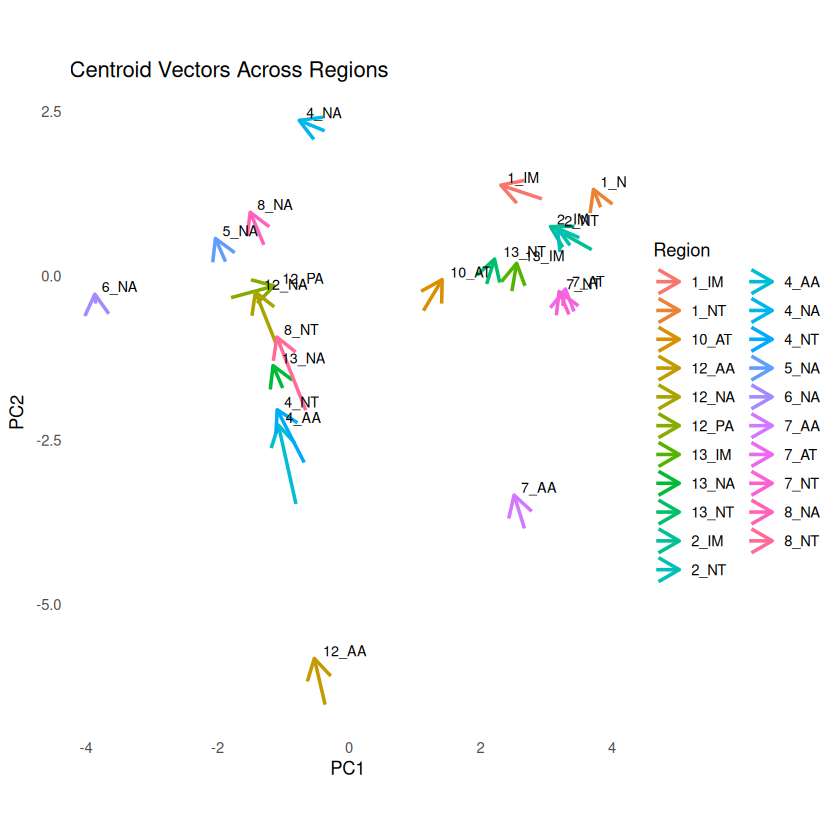

In [15]:
library(dplyr)
library(ggplot2)

# Calculate centroids and plot vectors for all regions
centroid_vectors <- data.frame()
region_cell_counts <- data.frame()
# get all regions from ipcc_srex
merged_regions <- unique(wwf_aggregated$bim_rlm)
#sig_merged_regions <- get_list_of_regions(combined_results_gbif)
#merged_regions <- setdiff(merged_regions, sig_merged_regions)

# significant regions only
merged_regions <- get_list_of_regions(combined_results_gbif)

for (i in merged_regions) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  region_cell_count <- length(region_cells)
  region_cell_counts <- rbind(region_cell_counts, data.frame(region = i, cell_count = region_cell_count))
  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
  
  # Skip regions with no data
  if (nrow(filtered_data) == 0) {
    message("No data for region ", i, ", skipping...")
    next
  }

  # Skip regions with insufficient data
  if (nrow(filtered_data %>% filter(group == "native")) < 10 || nrow(filtered_data %>% filter(group == "all")) < 10) {
    message("Insufficient data for region ", i, ", skipping...")
    next
  } 
  
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")
  
  centroid_native <- centroids %>% filter(group == "native")
  centroid_all <- centroids %>% filter(group == "all")
  
  centroid_vectors <- rbind(centroid_vectors, data.frame(
    region = i,
    PC1_native = centroid_native$PC1,
    PC2_native = centroid_native$PC2,
    PC1_all = centroid_all$PC1,
    PC2_all = centroid_all$PC2
  ))
}

# Plot centroid vectors
p <- ggplot(centroid_vectors) +
  geom_segment(aes(x = PC1_native, y = PC2_native, xend = PC1_all, yend = PC2_all, color = region),
               arrow = arrow(length = unit(0.2, "inches")), linewidth = 1) +
  geom_text(aes(x = PC1_all, y = PC2_all, label = region), hjust = -0.2, vjust = -0.2, size = 3) +
  coord_equal() +
  theme_minimal() +
  theme(panel.grid = element_blank()) +
  labs(title = "Centroid Vectors Across Regions", x = "PC1", y = "PC2", color = "Region")

  #ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_across_regions_GBIF.png", 
  #  plot = p, width = 10, height = 7, dpi = 300)

print(p)


In [16]:
library(dplyr)
library(plotly)

# Calculate centroids and plot vectors for all regions
centroid_vectors <- data.frame()
region_cell_counts <- data.frame()
# get all regions from ipcc_srex
merged_regions <- unique(wwf_aggregated$bim_rlm)

# significant regions only
merged_regions <- get_list_of_regions(combined_results_gbif)

for (i in merged_regions) {
    f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
    region_cells <- h3::polyfill(f, res = 3)
    region_cell_count <- length(region_cells)
    region_cell_counts <- rbind(region_cell_counts, data.frame(region = i, cell_count = region_cell_count))
    filtered_data <- combined_data %>%
        filter(h3_res3 %in% region_cells)
    
    # Skip regions with no data
    if (nrow(filtered_data) == 0) {
        message("No data for region ", i, ", skipping...")
        next
    }

    # Skip regions with insufficient data
    if (nrow(filtered_data %>% filter(group == "native")) < 10 || nrow(filtered_data %>% filter(group == "all")) < 10) {
        message("Insufficient data for region ", i, ", skipping...")
        next
    } 
    
    centroids <- filtered_data %>%
        group_by(group) %>%
        summarise(PC1 = mean(PC1, na.rm = TRUE),
                            PC2 = mean(PC2, na.rm = TRUE),
                            PC3 = mean(PC3, na.rm = TRUE),
                            .groups = "drop")
    
    centroid_native <- centroids %>% filter(group == "native")
    centroid_all <- centroids %>% filter(group == "all")
    
    centroid_vectors <- rbind(centroid_vectors, data.frame(
        region = i,
        PC1_native = centroid_native$PC1,
        PC2_native = centroid_native$PC2,
        PC3_native = centroid_native$PC3,
        PC1_all = centroid_all$PC1,
        PC2_all = centroid_all$PC2,
        PC3_all = centroid_all$PC3
    ))
}




Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



In [17]:
library(plotly)
library(dplyr)

# Make a long table for easier plotting
centroids_long <- centroid_vectors %>%
  mutate(
    dPC1 = PC1_all - PC1_native,
    dPC2 = PC2_all - PC2_native,
    dPC3 = PC3_all - PC3_native
  )

# Create 3D plot
fig <- plot_ly(type = "scatter3d", mode = "markers")

# Add starting points (native centroids)
fig <- fig %>% add_markers(
  x = centroids_long$PC1_native,
  y = centroids_long$PC2_native,
  z = centroids_long$PC3_native,
  marker = list(size = 4, color = "blue"),
  name = "Native centroid"
)

# Add ending points (all centroids)
fig <- fig %>% add_markers(
  x = centroids_long$PC1_all,
  y = centroids_long$PC2_all,
  z = centroids_long$PC3_all,
  marker = list(size = 4, color = "red"),
  name = "All centroid"
)

# Add vectors (arrows) using line segments
for (i in 1:nrow(centroids_long)) {
  fig <- fig %>% add_trace(
    type = "scatter3d",
    mode = "lines",
    x = c(centroids_long$PC1_native[i], centroids_long$PC1_all[i]),
    y = c(centroids_long$PC2_native[i], centroids_long$PC2_all[i]),
    z = c(centroids_long$PC3_native[i], centroids_long$PC3_all[i]),
    line = list(width = 4),
    name = centroids_long$region[i],
    showlegend = FALSE
  )
}

fig <- fig %>%
  layout(
    scene = list(
      xaxis = list(title = "PC1"),
      yaxis = list(title = "PC2"),
      zaxis = list(title = "PC3")
    ),
    title = "3D Vectors from Native → All Centroids"
  )

fig


HTML widgets cannot be represented in plain text (need html)

In [18]:
head(centroid_vectors)

,region,PC1_native,PC2_native,PC3_native,PC1_all,PC2_all,PC3_all
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,10_AT,1.1315694,-0.5290992,-0.3156519,1.4158679,-0.05603187,0.36720761
2,12_AA,-0.3639603,-6.5214216,-1.1723908,-0.5282083,-5.81891928,-0.96263563
3,12_PA,-1.7943747,-0.3303290,0.2178862,-1.1391647,-0.15235657,0.29213068
4,12_NA,-1.1111953,-1.0268690,-0.4380345,-1.4248168,-0.24486360,0.03286221
5,13_IM,2.4774068,-0.2304822,1.3354816,2.5501976,0.19176067,1.52639350
6,13_NA,-1.0089345,-1.7049298,0.6745362,-1.1557112,-1.36488725,0.90586851


In [19]:
centroid_vectors <- centroid_vectors %>%
  left_join(region_cell_counts, by = "region")

head(centroid_vectors)


,region,PC1_native,PC2_native,PC3_native,PC1_all,PC2_all,PC3_all,cell_count
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,10_AT,1.1315694,-0.5290992,-0.3156519,1.4158679,-0.05603187,0.36720761,64
2,12_AA,-0.3639603,-6.5214216,-1.1723908,-0.5282083,-5.81891928,-0.96263563,70
3,12_PA,-1.7943747,-0.3303290,0.2178862,-1.1391647,-0.15235657,0.29213068,161
4,12_NA,-1.1111953,-1.0268690,-0.4380345,-1.4248168,-0.24486360,0.03286221,11
5,13_IM,2.4774068,-0.2304822,1.3354816,2.5501976,0.19176067,1.52639350,88
6,13_NA,-1.0089345,-1.7049298,0.6745362,-1.1557112,-1.36488725,0.90586851,169


In [20]:
# Starting positions (native centroids)
starts <- centroid_vectors %>%
  select(PC1_native, PC2_native, PC3_native) %>%
  as.matrix()

# Shift vectors (all - native)
vectors <- centroid_vectors %>%
  transmute(
    dPC1 = PC1_all - PC1_native,
    dPC2 = PC2_all - PC2_native,
    dPC3 = PC3_all - PC3_native
  ) %>%
  as.matrix()

# Weights (based on cell counts)
weights <- centroid_vectors$cell_count


In [21]:
weights[is.na(weights) | weights == 0] <- 1


In [22]:
ok <- complete.cases(starts, vectors)
starts <- starts[ok, ]
vectors <- vectors[ok, ]


In [23]:
dim(starts)
dim(vectors)
head(starts)
head(vectors)


[1] 21  3

[1] 21  3

PC1_native,PC2_native,PC3_native
1.1315694,-0.5290992,-0.3156519
-0.3639603,-6.5214216,-1.1723908
-1.7943747,-0.3303290,0.2178862
-1.1111953,-1.0268690,-0.4380345
2.4774068,-0.2304822,1.3354816
-1.0089345,-1.7049298,0.6745362


dPC1,dPC2,dPC3
0.28429847,0.4730674,0.68285956
-0.16424796,0.7025023,0.20975520
0.65521001,0.1779724,0.07424446
-0.31362151,0.7820054,0.47089671
0.07279085,0.4222428,0.19091194
-0.14677670,0.3400425,0.23133230


In [24]:
# Get vector lengths per region (3D)
vector_lengths <- sqrt(vectors[,1]^2 + vectors[,2]^2 + vectors[,3]^2)
vector_lengths_df <- data.frame(
  region = centroid_vectors$region[ok],
  vector_length = vector_lengths
)
head(vector_lengths_df)

,region,vector_length
,<chr>,<dbl>
1,10_AT,0.8780180
2,12_AA,0.7513216
3,12_PA,0.6829982
4,12_NA,0.9652122
5,13_IM,0.4690788
6,13_NA,0.4366772


In [25]:
# merge vector_lengths_df with average_perc_naturalized_region
merged_analysis <- vector_lengths_df %>%
  inner_join(average_perc_naturalized_region, by = "region")    

,region,vector_length,average_perc_naturalized
,<chr>,<dbl>,<dbl>
1,10_AT,0.8780180,28.134167
2,12_AA,0.7513216,7.872721
3,12_PA,0.6829982,14.492500
4,12_NA,0.9652122,21.273259
5,13_IM,0.4690788,41.701542
6,13_NA,0.4366772,9.927191



	Pearson's product-moment correlation

data:  vector_lengths_df$vector_length and vector_lengths_df$average_perc_naturalized
t = 0.81845, df = 19, p-value = 0.4232
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.2685394  0.5707583
sample estimates:
      cor 
0.1845402 


	Pearson's product-moment correlation

data:  vector_lengths_df$average_perc_naturalized and vector_lengths_df$vector_length
t = 0.81845, df = 19, p-value = 0.4232
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.2685394  0.5707583
sample estimates:
      cor 
0.1845402 



`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


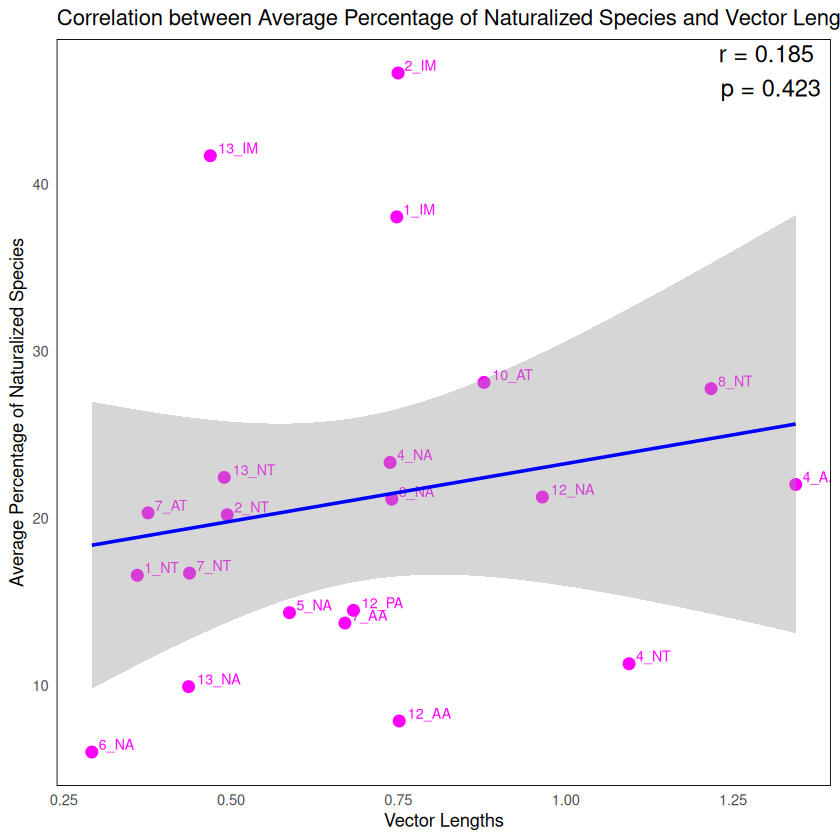

In [26]:
# correlate vector lengths with average perc_naturalized per region
vector_lengths_df <- vector_lengths_df %>%
  left_join(average_perc_naturalized_region, by = "region")
head(vector_lengths_df)

cor_test <- cor.test(vector_lengths_df$vector_length, vector_lengths_df$average_perc_naturalized, method = "pearson")
print(cor_test)

# plot correlation
highlight_regions <- get_list_of_regions(combined_results_gbif)

# Ensure the columns are numeric
vector_lengths_df <- vector_lengths_df %>%
  mutate(
    vector_length = as.numeric(vector_length),
    average_perc_naturalized = as.numeric(average_perc_naturalized)
  )
  # Perform the correlation test
  cor_test <- cor.test(vector_lengths_df$average_perc_naturalized, vector_lengths_df$vector_length, method = "pearson")
  print(cor_test)

  # Plot correlation
  p_cor <- ggplot(vector_lengths_df, aes(x = vector_length, y = average_perc_naturalized)) +
    geom_point(aes(color = region %in% highlight_regions), size = 3) +
    geom_text(data = vector_lengths_df %>% filter(region %in% highlight_regions),
              aes(label = region), hjust = -0.2, vjust = -0.2, size = 3, color = "magenta") +
    geom_smooth(method = "lm", se = TRUE, color = "blue") +
    scale_color_manual(values = c("TRUE" = "magenta", "FALSE" = "black"), guide = "none") +
    theme_minimal() +
    theme(panel.grid = element_blank(), panel.border = element_rect(color = "black", fill = NA)) +
    labs(title = "Correlation between Average Percentage of Naturalized Species and Vector Lengths",
       x = "Vector Lengths",     
       y = "Average Percentage of Naturalized Species") +
    annotate("text", x = Inf, y = Inf, label = paste("r =", round(cor_test$estimate, 3), "\np =", signif(cor_test$p.value, 3)),
         hjust = 1.1, vjust = 1.1, size = 5)

    ggsave(filename = "../Results/Figures/correlation_vector_lengths_perc_naturalized_GBIF.png",
    plot = p_cor, width = 8, height = 8, dpi = 300)
    print(p_cor)


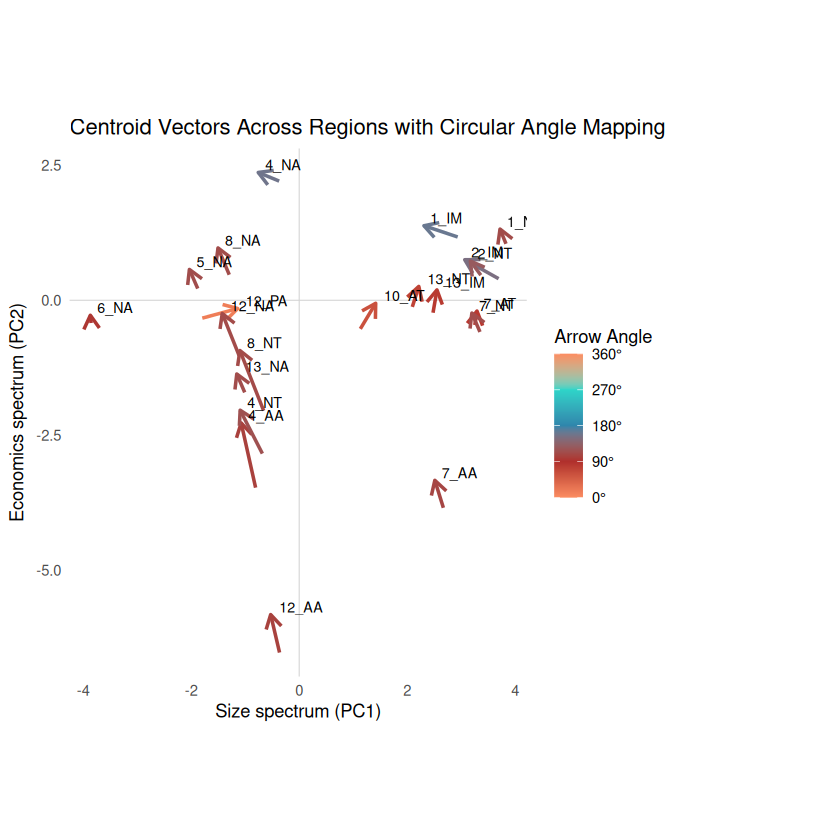

In [27]:
library(ggplot2)
library(dplyr)
library(tibble)
library(cowplot)

# Calculate angles for arrows
centroid_vectors <- centroid_vectors %>%
  mutate(
    angle = atan2(PC2_all - PC2_native, PC1_all - PC1_native),  # Angle in radians
    angle_deg = (angle * 180 / pi) %% 360  # Convert to degrees and wrap around
  )

colors = c("#fc8d62", "#b02f2c", "#2F86AC",  "#2ed5c9", "#fc8d62")
# Create the main plot
p <- ggplot(centroid_vectors) +
  geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
  geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
  geom_segment(aes(x = PC1_native, y = PC2_native, xend = PC1_all, yend = PC2_all, color = angle_deg),
               arrow = arrow(length = unit(0.13, "inches")), linewidth = 1) +
  geom_text(aes(x = PC1_all, y = PC2_all, label = region), hjust = -0.2, vjust = -0.2, size = 3) +
  scale_color_gradientn(
    colors = colors,  # Circular palette
    limits = c(0, 360),
    breaks = c(0, 90, 180, 270, 360),
    labels = c("0°", "90°", "180°", "270°", "360°"),
    name = "Arrow Angle"
  ) +
  coord_equal() +
  theme_minimal() +
  theme(panel.grid = element_blank()) +
  labs(title = "Centroid Vectors Across Regions with Circular Angle Mapping",
       x = "Size spectrum (PC1)", y = "Economics spectrum (PC2)", color = "Angle (Degrees)")

# Create circular legend
circle_data <- tibble(
  angle = seq(0, 2 * pi, length.out = 100),
  x = cos(angle),
  y = sin(angle),
  color = angle * 180 / pi  # Convert radians to degrees
)

circular_legend <- ggplot(circle_data, aes(x = x, y = y, fill = color)) +
  geom_tile() +
  coord_fixed() +
  scale_fill_gradientn(
    colors = colors,
    limits = c(0, 360),
    breaks = c(0, 90, 180, 270, 360),
    labels = c("0°", "90°", "180°", "270°", "360°"),
    name = "Angle"
  ) +
  theme_void() +
  theme(legend.position = "none")

# Combine the main plot and circular legend
final_plot <- ggdraw() +
  draw_plot(p, 0, 0, 0.8, 1) +  # Main plot takes 80% width
  draw_plot(circular_legend, 0.8, 0.3, 0.2, 0.4)  # Circular legend on the right

# Save and display the combined plot
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen.png", plot = final_plot, width = 10, height = 7, dpi = 300)
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen.png", plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10.png", plot = final_plot, width = 10, height = 7, dpi = 300)
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS.png", plot = final_plot, width = 10, height = 5, dpi = 300)

print(final_plot)

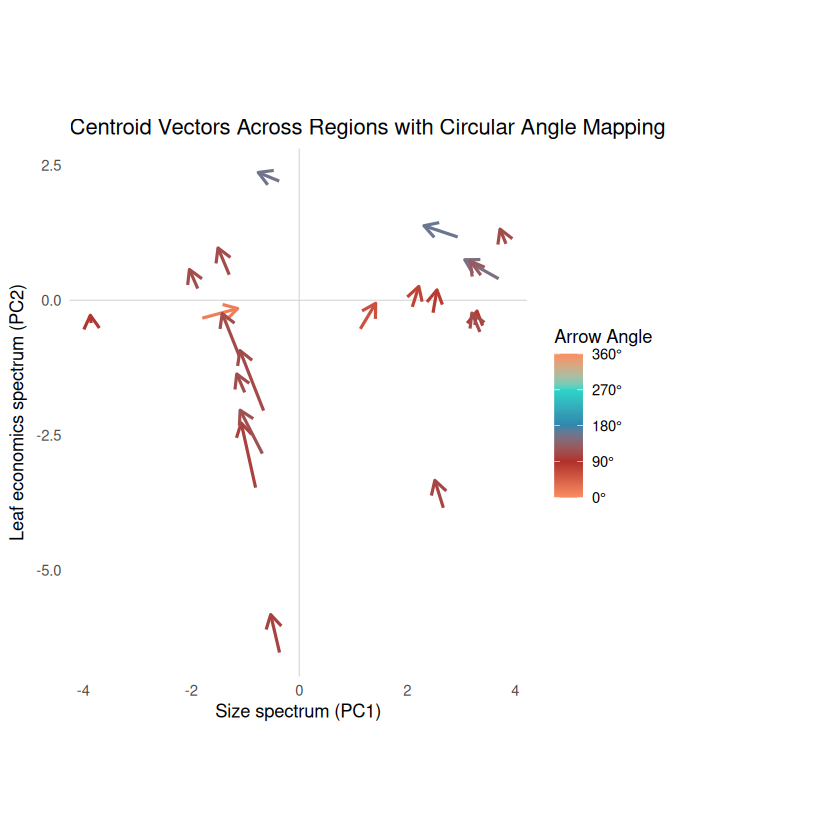

In [28]:
library(ggplot2)
library(dplyr)
library(tibble)
library(cowplot)

# Calculate angles for arrows
centroid_vectors <- centroid_vectors %>%
  mutate(
    angle = atan2(PC2_all - PC2_native, PC1_all - PC1_native),  # Angle in radians
    angle_deg = (angle * 180 / pi) %% 360  # Convert to degrees and wrap around
  )

colors = c("#fc8d62", "#b02f2c", "#2F86AC",  "#2ed5c9", "#fc8d62")
# Create the main plot
p <- ggplot(centroid_vectors) +
  
  geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
  geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
  ##### optional:
  #geom_point(data = as.data.frame(null_focals), aes(x = V1, y = V2), color = rgb(0.6, 0.6, 0.6, 0.5), size = 0.6) +
  geom_segment(aes(x = PC1_native, y = PC2_native, xend = PC1_all, yend = PC2_all, color = angle_deg),
               arrow = arrow(length = unit(0.13, "inches")), linewidth = 0.9) +
  ##### optional:
  #geom_text(aes(x = PC1_all, y = PC2_all, label = region), hjust = -0.2, vjust = -0.2, size = 3) +
  scale_color_gradientn(
    colors = colors,  # Circular palette
    limits = c(0, 360),
    breaks = c(0, 90, 180, 270, 360),
    labels = c("0°", "90°", "180°", "270°", "360°"),
    name = "Arrow Angle"
  ) +
  
  ##### optional:
  #annotate("point", x = res$x_obs[1], y = res$x_obs[2], color = "magenta", size = 3, shape = 8) +  # focal point
  ##### optional:
  #annotate("point", x = res$centroid[1], y = res$centroid[2], color = "black", size = 3, shape = 4) +  # centroid

  coord_equal() +
  theme_minimal() +
  theme(panel.grid = element_blank()) +
  labs(title = "Centroid Vectors Across Regions with Circular Angle Mapping",
       x = "Size spectrum (PC1)", y = "Leaf economics spectrum (PC2)", color = "Angle (Degrees)") #+
  ##### optional:
  #annotate("text", x = res$x_obs[1] - 0.2, y = res$x_obs[2] - 0.1, label = "Focal", color = "magenta", size = 3, hjust = -0.1, vjust = 1.6) +
  ##### optional:
  #annotate("text", x = res$centroid[1] - 0.2, y = res$centroid[2] - 0.1, label = "Centroid", color = "black", size = 3, hjust = -0.2, vjust = 1.4) 

# Create circular legend
circle_data <- tibble(
  angle = seq(0, 2 * pi, length.out = 100),
  x = cos(angle),
  y = sin(angle),
  color = angle * 180 / pi  # Convert radians to degrees
)

circular_legend <- ggplot(circle_data, aes(x = x, y = y, fill = color)) +
  geom_tile() +
  coord_fixed() +
  scale_fill_gradientn(
    colors = colors,
    limits = c(0, 360),
    breaks = c(0, 90, 180, 270, 360),
    labels = c("0°", "90°", "180°", "270°", "360°"),
    name = "Angle"
  ) +
  theme_void() +
  theme(legend.position = "none")

# Combine the main plot and circular legend
final_plot <- ggdraw() +
  draw_plot(p, 0, 0, 0.8, 1) +  # Main plot takes 80% width
  draw_plot(circular_legend, 0.8, 0.3, 0.2, 0.4) # Circular legend on the right 


# Save and display the combined plot
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_nolabels_Olsen.png",  plot = final_plot, width = 10, height = 7, dpi = 300)
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_nolabels_Olsen.png",  plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_nolabels_Olsen_CS_log10.png",  plot = final_plot, width = 10, height = 7, dpi = 300)
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_nolabels_Olsen_CS.png",  plot = final_plot, width = 10, height = 5, dpi = 300)

print(final_plot)

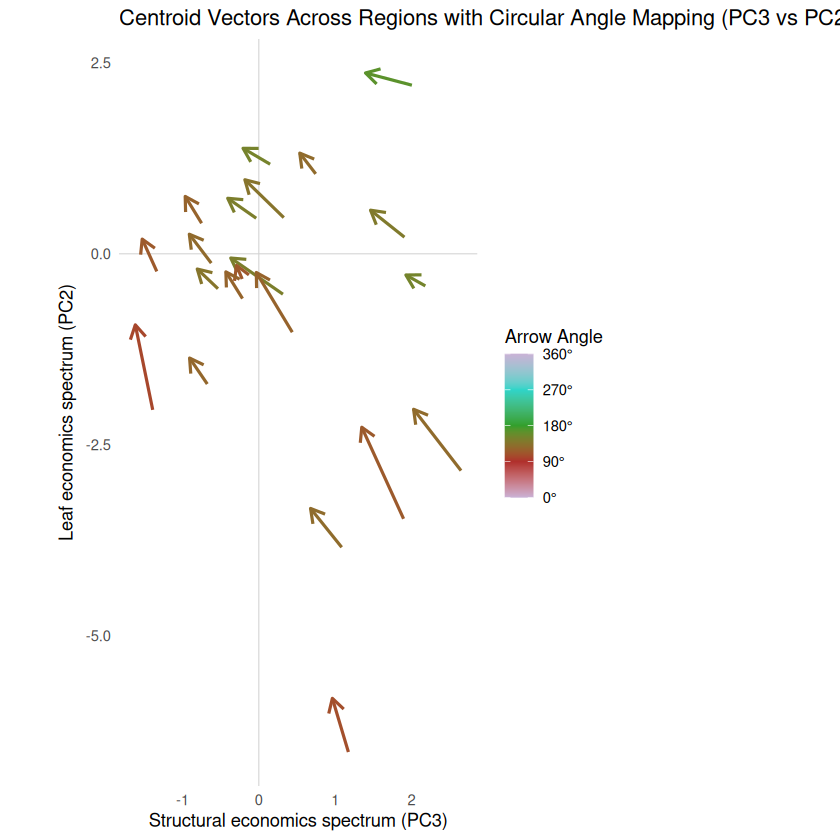

In [29]:
library(ggplot2)
library(dplyr)
library(tibble)
library(cowplot)

# Mirror PC3 axis
centroid_vectors <- centroid_vectors %>%
    mutate(
        PC3_native = -PC3_native,
        PC3_all = -PC3_all
    )

# Calculate angles for arrows
centroid_vectors <- centroid_vectors %>%
    mutate(
        angle = atan2(PC2_all - PC2_native, PC3_all - PC3_native),  # Angle in radians
        angle_deg = (angle * 180 / pi) %% 360  # Convert to degrees and wrap around
    )

colors = c(  "#cab2d6", "#b02f2c",  "#33a02c",  "#2ed5c9",  "#cab2d6")
# Create the main plot
p <- ggplot(centroid_vectors) +
    geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_segment(aes(x = PC3_native, y = PC2_native, xend = PC3_all, yend = PC2_all, color = angle_deg),
                 arrow = arrow(length = unit(0.13, "inches")), linewidth = 0.9) +
    scale_color_gradientn(
        colors = colors,  # Circular palette
        limits = c(0, 360),
        breaks = c(0, 90, 180, 270, 360),
        labels = c("0°", "90°", "180°", "270°", "360°"),
        name = "Arrow Angle"
    ) +
    coord_equal() +
    theme_minimal() +
    theme(panel.grid = element_blank()) +
    labs(title = "Centroid Vectors Across Regions with Circular Angle Mapping (PC3 vs PC2)",
         x = "Structural economics spectrum (PC3)", y = "Leaf economics spectrum (PC2)", color = "Angle (Degrees)")

# Create circular legend
circle_data <- tibble(
    angle = seq(0, 2 * pi, length.out = 100),
    x = cos(angle),
    y = sin(angle),
    color = angle * 180 / pi  # Convert radians to degrees
)

circular_legend <- ggplot(circle_data, aes(x = x, y = y, fill = color)) +
    geom_tile() +
    coord_fixed() +
    scale_fill_gradientn(
        colors = colors,
        limits = c(0, 360),
        breaks = c(0, 90, 180, 270, 360),
        labels = c("0°", "90°", "180°", "270°", "360°"),
        name = "Angle"
    ) +
    theme_void() +
    theme(legend.position = "none")

# Combine the main plot and circular legend
final_plot <- ggdraw() +
    draw_plot(p, 0, 0, 0.8, 1) +  # Main plot takes 80% width
    draw_plot(circular_legend, 0.8, 0.3, 0.2, 0.4) # Circular legend on the right 

# Save and display the combined plot
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_nolabels_Olsen_CS_PC3_PC2.png",  plot = final_plot, width = 10, height = 5, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_significant_nolabels_Olsen_CS_PC3_PC2_log10.png",  plot = final_plot, width = 10, height = 7, dpi = 300)

print(final_plot)


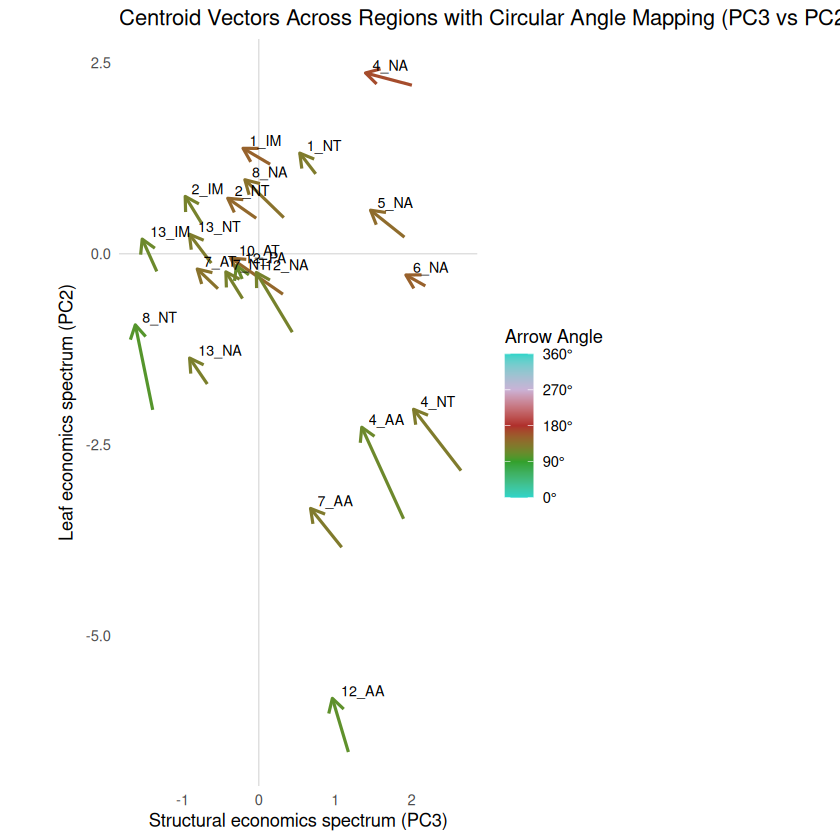

In [30]:
library(ggplot2)
library(dplyr)
library(tibble)
library(cowplot)

# Calculate angles for arrows
centroid_vectors <- centroid_vectors %>%
    mutate(
        angle = atan2(PC2_all - PC2_native, PC3_all - PC3_native),  # Angle in radians
        angle_deg = (angle * 180 / pi) %% 360  # Convert to degrees and wrap around
    )

colors = c( "#2ed5c9" , "#33a02c", "#b02f2c", "#cab2d6",  "#2ed5c9" )
# Create the main plot
p <- ggplot(centroid_vectors) +
    geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_segment(aes(x = PC3_native, y = PC2_native, xend = PC3_all, yend = PC2_all, color = angle_deg),
                 arrow = arrow(length = unit(0.13, "inches")), linewidth = 0.9) +
    geom_text(aes(x = PC3_all, y = PC2_all, label = region), hjust = -0.2, vjust = -0.2, size = 3) +  # Add region labels
    scale_color_gradientn(
        colors = colors,  # Circular palette
        limits = c(0, 360),
        breaks = c(0, 90, 180, 270, 360),
        labels = c("0°", "90°", "180°", "270°", "360°"),
        name = "Arrow Angle"
    ) +
    coord_equal() +
    theme_minimal() +
    theme(panel.grid = element_blank()) +
    labs(title = "Centroid Vectors Across Regions with Circular Angle Mapping (PC3 vs PC2)",
         x = "Structural economics spectrum (PC3)", y = "Leaf economics spectrum (PC2)", color = "Angle (Degrees)")

# Create circular legend
circle_data <- tibble(
    angle = seq(0, 2 * pi, length.out = 100),
    x = cos(angle),
    y = sin(angle),
    color = angle * 180 / pi  # Convert radians to degrees
)

circular_legend <- ggplot(circle_data, aes(x = x, y = y, fill = color)) +
    geom_tile() +
    coord_fixed() +
    scale_fill_gradientn(
        colors = colors,
        limits = c(0, 360),
        breaks = c(0, 90, 180, 270, 360),
        labels = c("0°", "90°", "180°", "270°", "360°"),
        name = "Angle"
    ) +
    theme_void() +
    theme(legend.position = "none")

# Combine the main plot and circular legend
final_plot <- ggdraw() +
    draw_plot(p, 0, 0, 0.8, 1) +  # Main plot takes 80% width
    draw_plot(circular_legend, 0.8, 0.3, 0.2, 0.4) # Circular legend on the right 

# Save and display the combined plot
#ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_nolabels_Olsen_CS_PC3_PC2.png",  plot = final_plot, width = 10, height = 5, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_significant_labels_Olsen_CS_PC3_PC2_log10.png",  plot = final_plot, width = 10, height = 5, dpi = 300)

print(final_plot)


In [31]:
# Filter and print regions where significance_PC1, significance_PC2, or significance_PC3 is not empty
print(combined_results_gbif$region[combined_results_gbif$significance_PC1 != ""])

print(combined_results_gbif$region[combined_results_gbif$significance_PC2 != ""])

print(combined_results_gbif$region[combined_results_gbif$significance_PC3 != ""])


[1] "12_PA" "1_IM"  "2_IM"  "4_NA" 
 [1] "10_AT" "12_AA" "12_NA" "13_IM" "13_NA" "1_IM"  "1_NT"  "2_IM"  "4_AA" 
[10] "4_NT"  "5_NA"  "7_AA"  "7_AT"  "7_NT"  "8_NA"  "8_NT" 
 [1] "10_AT" "13_NT" "1_IM"  "1_NT"  "2_IM"  "2_NT"  "4_AA"  "4_NA"  "5_NA" 
[10] "6_NA"  "7_AT"  "8_NA" 


In [32]:
sdfdgdf

ERROR: Error: object 'sdfdgdf' not found


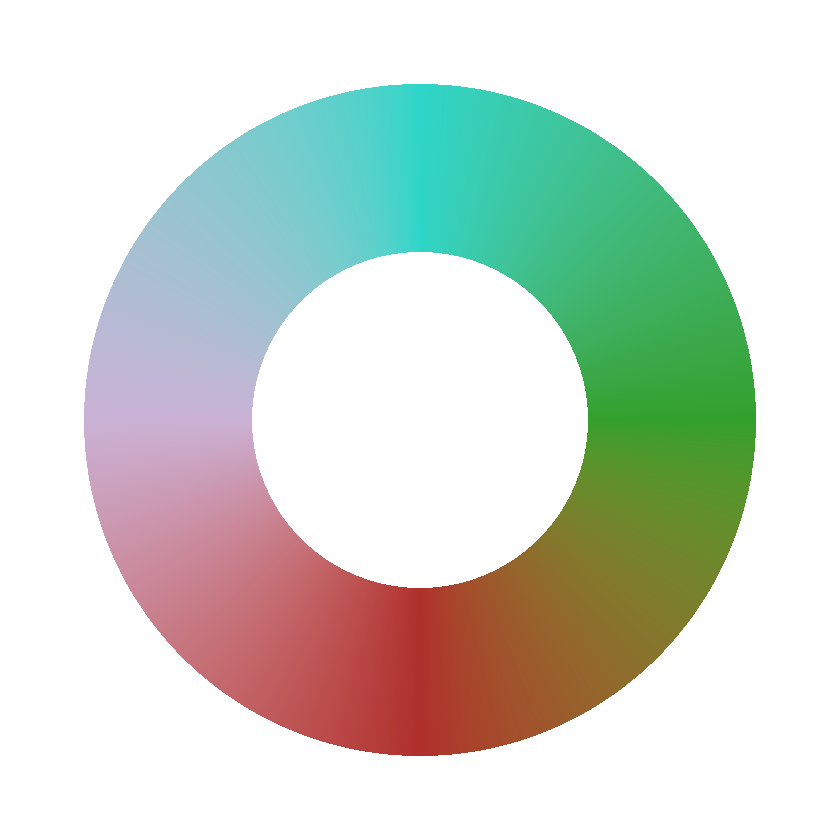

In [ ]:
library(ggplot2)

# Create test data
data <- data.frame(
    category = paste0("Category_", 1:1000),
    count = 1:1000  # Counts from 1 to 500
)

# Compute percentages
data$fraction <- data$count / sum(data$count)

# Compute the cumulative percentages (top of each rectangle)
data$ymax <- cumsum(data$fraction)

# Compute the bottom of each rectangle
data$ymin <- c(0, head(data$ymax, n = -1))

# Compute label position
data$labelPosition <- (data$ymax + data$ymin) / 2

# Compute a good label
data$label <- paste0(data$category, "\n value: ", data$count)

# Add a continuous variable for color mapping
data$color_value <- (data$ymax + data$ymin) / 2 * 360  # Map to degrees (0-360)

# Custom color palette
colors = c( "#2ed5c9" , "#33a02c", "#b02f2c", "#cab2d6",  "#2ed5c9" )

ggplot(data, aes(ymax = ymax, ymin = ymin, xmax = 4, xmin = 3, fill = color_value)) +
  geom_rect() +
  scale_fill_gradientn(colors = colors, limits = c(0, 360)) +
  coord_polar(theta = "y") +
  xlim(c(2, 4)) +
  theme_void() +
  theme(legend.position = "none")

#save as printable png
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/circular_barplot.png", width = 10, height = 7, dpi = 300)  

In [ ]:
# Filter vector_lengths_df for regions in highlight_regions
filtered_vector_lengths_df <- vector_lengths_df %>%
    filter(region %in% highlight_regions)

# Perform the correlation test
cor_test <- cor.test(filtered_vector_lengths_df$average_perc_naturalized, filtered_vector_lengths_df$vector_length, method = "pearson")
print(cor_test)



	Pearson's product-moment correlation

data:  filtered_vector_lengths_df$average_perc_naturalized and filtered_vector_lengths_df$vector_length
t = 0.34737, df = 17, p-value = 0.7326
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.3849349  0.5183946
sample estimates:
      cor 
0.0839528 



In [ ]:
# ---------- helper: fit focal point ----------
fit_focal_point <- function(starts, vectors, weights = NULL) {
  n <- nrow(starts)
  if (is.null(weights)) weights <- rep(1, n)
  
  # Direction vectors normalized
  dirs <- vectors / sqrt(rowSums(vectors^2))
  
  # Each line: x = start + t * dir
  # Focal point = least squares intersection of lines
  A <- matrix(0, 2, 2)
  b <- rep(0, 2)
  for (i in 1:n) {
    ui <- dirs[i, , drop = FALSE]
    Pi <- matrix(starts[i, ], ncol = 2)
    Ai <- diag(2) - t(ui) %*% ui
    A <- A + weights[i] * Ai
    b <- b + weights[i] * Ai %*% t(Pi)
  }
  x_est <- solve(A, b)
  return(drop(x_est))
}

# ---------- helper: permutation test ----------
perm_test_focal <- function(starts, vectors, weights = NULL, nperm = 5000, seed = NULL) {
  if (!is.null(seed)) set.seed(seed)
  x_obs <- fit_focal_point(starts, vectors, weights)
  # choose statistic: distance from global start centroid to focal point
  centroid <- colMeans(starts)

  #centroid <- c(0, 0)
  stat_obs <- sqrt(sum((x_obs - centroid)^2))

  norms <- sqrt(rowSums(vectors^2))
  n <- nrow(vectors)
  stats <- numeric(nperm)
  for (i in seq_len(nperm)) {
    angles <- runif(n, 0, 2*pi)
    perm_v <- cbind(norms * cos(angles), norms * sin(angles))
    x_perm <- tryCatch(fit_focal_point(starts, perm_v, weights), error = function(e) NA)
    if (any(is.na(x_perm))) {
      stats[i] <- NA
    } else {
      stats[i] <- sqrt(sum((x_perm - centroid)^2))
    }
  }
  stats <- stats[!is.na(stats)]
  pval <- (sum(stats >= stat_obs) + 1) / (length(stats) + 1)
  list(
    x_obs = x_obs,
    centroid = centroid,
    stat_obs = stat_obs,
    stats = stats,
    pval = pval
  )
}

# ---------- helper: mean cosine between vector and vector-to-target ----------
mean_cosine_to_target <- function(starts, vectors, target) {
  vec_to_target <- matrix(rep(target, nrow(starts)), ncol = 2, byrow = TRUE) - starts
  norms_v <- sqrt(rowSums(vectors^2))
  norms_t <- sqrt(rowSums(vec_to_target^2))
  ok <- which(norms_v > 1e-12 & norms_t > 1e-12)
  cosines <- numeric(nrow(starts))
  cosines[ok] <- rowSums(vectors[ok,,drop=FALSE] * vec_to_target[ok,,drop=FALSE]) / (norms_v[ok] * norms_t[ok])
  return(mean(cosines[ok], na.rm = TRUE))
}

# ---------- Example usage ----------
# Suppose you have:
# starts: n x 2 matrix (PC1_native, PC2_native)
# vectors: n x 2 matrix (deltaPC1, deltaPC2) = PC_all - PC_native



# ---------- compute focal point and test ----------
#res <- perm_test_focal(starts, vectors, weights = weights, nperm = 2000, seed = 123)
res <- perm_test_focal(starts, vectors, nperm = 2000, seed = 123)
res$x_obs         # estimated focal point
res$centroid      # centroid of start points
res$pval          # permutation p-value

# ---------- diagnostics ----------
mean_cos <- mean_cosine_to_target(starts, vectors, res$x_obs)
mean_cos_centroid <- mean_cosine_to_target(starts, vectors, res$centroid)

cat("Focal:", round(res$x_obs,3), "\nCentroid:", round(res$centroid,3),
    "\nmean cosine -> focal:", round(mean_cos,3),
    "\nmean cosine -> centroid:", round(mean_cos_centroid,3),
    "\np-val:", round(res$pval,4), "\n")

# ---------- plotting: overlay focal point, centroid, & arrows ----------
plot(starts[,1], starts[,2], pch=16, col="grey40", xlab="PC1", ylab="PC2", asp=1)
arrows(starts[,1], starts[,2], starts[,1] + vectors[,1], starts[,2] + vectors[,2],
       length = 0.08, col = "steelblue")

legend("topright", legend = c("focal", "centroid"), pch = c(8,4), col = c("red", "black"), bty="n")

# ---------- visualize null cloud of focal points (optional) ----------
# If you want to show distribution of focal points under null:
compute_perm_focals <- function(starts, vectors, nperm = 1000) {
  norms <- sqrt(rowSums(vectors^2))
  n <- nrow(vectors)
  focals <- matrix(NA, nrow = nperm, ncol = 2)
  for (i in seq_len(nperm)) {
    angles <- runif(n, 0, 2*pi)
    perm_v <- cbind(norms * cos(angles), norms * sin(angles))
    focals[i,] <- tryCatch(fit_focal_point(starts, perm_v), error = function(e) c(NA,NA))
  }
  focals[complete.cases(focals), , drop = FALSE]
}
null_focals <- compute_perm_focals(starts, vectors, nperm = 500)
points(null_focals[,1], null_focals[,2], pch=20, cex=0.6, col=rgb(0.6,0.6,0.6,0.5))
points(res$x_obs[1], res$x_obs[2], pch=8, col="red", cex=1.6, lwd=2)   # focal point
points(res$centroid[1], res$centroid[2], pch=4, col="blue", cex=1.6, lwd=2) # centroid


Warning message in matrix(starts[i, ], ncol = 2):
“data length [3] is not a sub-multiple or multiple of the number of rows [2]”


ERROR: Error in diag(2) - t(ui) %*% ui: non-conformable arrays


## 3D focal point

In [ ]:
fit_focal_point_3D <- function(starts, vectors, weights = NULL) {
  n <- nrow(starts)
  if (is.null(weights)) weights <- rep(1, n)

  # normalize direction vectors
  dirs <- vectors / sqrt(rowSums(vectors^2))  # n x 3

  # Accumulate matrices for least-squares intersection
  A <- matrix(0, 3, 3)
  b <- rep(0, 3)
  for (i in 1:n) {
    ui <- matrix(dirs[i, ], ncol=1)      # column vector
    Pi <- matrix(starts[i, ], ncol=1)
    Ai <- diag(3) - ui %*% t(ui)
    A <- A + weights[i] * Ai
    b <- b + weights[i] * Ai %*% Pi
  }

  x_est <- solve(A, b)
  drop(x_est)
}


In [ ]:
perm_test_focal_3D <- function(starts, vectors, weights = NULL, nperm = 2000, seed = NULL) {
  if (!is.null(seed)) set.seed(seed)
  x_obs <- fit_focal_point_3D(starts, vectors, weights)
  centroid <- colMeans(starts)
  stat_obs <- sqrt(sum((x_obs - centroid)^2))

  norms <- sqrt(rowSums(vectors^2))
  n <- nrow(vectors)
  stats <- numeric(nperm)
  
  for (i in seq_len(nperm)) {
    # random 3D directions: sample from uniform sphere
    phi <- runif(n, 0, 2*pi)
    cos_theta <- runif(n, -1, 1)
    sin_theta <- sqrt(1 - cos_theta^2)
    perm_v <- cbind(
      norms * sin_theta * cos(phi),
      norms * sin_theta * sin(phi),
      norms * cos_theta
    )
    x_perm <- tryCatch(fit_focal_point_3D(starts, perm_v, weights), error=function(e) NA)
    stats[i] <- ifelse(any(is.na(x_perm)), NA, sqrt(sum((x_perm - centroid)^2)))
  }

  stats <- stats[!is.na(stats)]
  pval <- (sum(stats >= stat_obs) + 1) / (length(stats) + 1)
  list(
    x_obs = x_obs,
    centroid = centroid,
    stat_obs = stat_obs,
    stats = stats,
    pval = pval
  )
}


In [ ]:
mean_cosine_to_target_3D <- function(starts, vectors, target) {
  vec_to_target <- matrix(rep(target, nrow(starts)), ncol=3, byrow=TRUE) - starts
  norms_v <- sqrt(rowSums(vectors^2))
  norms_t <- sqrt(rowSums(vec_to_target^2))
  ok <- which(norms_v > 1e-12 & norms_t > 1e-12)
  cosines <- numeric(nrow(starts))
  cosines[ok] <- rowSums(vectors[ok,,drop=FALSE] * vec_to_target[ok,,drop=FALSE]) / (norms_v[ok] * norms_t[ok])
  mean(cosines[ok], na.rm=TRUE)
}


In [ ]:
starts <- as.matrix(centroid_vectors[,c("PC1_native","PC2_native","PC3_native")])
vectors <- as.matrix(centroid_vectors[,c("PC1_all","PC2_all","PC3_all")]) - starts


In [ ]:
res <- perm_test_focal_3D(starts, vectors, nperm = 2000, seed = 123)
res$x_obs         # estimated focal point in 3D
res$centroid      # centroid of start points
res$pval          # permutation p-value

mean_cos <- mean_cosine_to_target_3D(starts, vectors, res$x_obs)
mean_cos_centroid <- mean_cosine_to_target_3D(starts, vectors, res$centroid)

cat("Focal:", round(res$x_obs,3), "\nCentroid:", round(res$centroid,3),
    "\nmean cosine -> focal:", round(mean_cos,3),
    "\nmean cosine -> centroid:", round(mean_cos_centroid,3),
    "\np-val:", round(res$pval,4), "\n")


[1] -0.3428481  0.4738538  0.6375872

PC1_native  PC2_native  PC3_native 
 0.29567181 -0.64755652 -0.09681483

[1] 0.0004997501

Focal: -0.343 0.474 0.638 
Centroid: 0.296 -0.648 -0.097 
mean cosine -> focal: 0.562 
mean cosine -> centroid: 0.163 
p-val: 5e-04 


In [ ]:
library(plotly)

fig <- plot_ly()
# arrows
fig <- fig %>% add_trace(
  type = "cone",
  x = starts[,1], y = starts[,2], z = starts[,3],
  u = vectors[,1], v = vectors[,2], w = vectors[,3],
  colorscale = "Viridis",
  showscale = TRUE,
  color = sqrt(rowSums(vectors^2)),
  sizemode = "absolute",
  sizeref = 0.5
)
# focal point
fig <- fig %>% add_markers(
  x = res$x_obs[1], y = res$x_obs[2], z = res$x_obs[3],
  marker = list(color="red", size=15),
  name="Focal Point"
)
# centroid
fig <- fig %>% add_markers(
  x = res$centroid[1], y = res$centroid[2], z = res$centroid[3],
  marker = list(color="blue", size=15),
  name="Centroid"
)
fig <- fig %>% layout(scene=list(
  xaxis=list(title="PC1"),
  yaxis=list(title="PC2"),
  zaxis=list(title="PC3")
))
fig


Warning message:
“'cone' objects don't have these attributes: 'marker'
Valid attributes include:
'anchor', 'autocolorscale', 'cauto', 'cmax', 'cmid', 'cmin', 'coloraxis', 'colorbar', 'colorscale', 'customdata', 'customdatasrc', 'hoverinfo', 'hoverinfosrc', 'hoverlabel', 'hovertemplate', 'hovertemplatesrc', 'hovertext', 'hovertextsrc', 'ids', 'idssrc', 'legendgroup', 'legendgrouptitle', 'legendrank', 'lighting', 'lightposition', 'meta', 'metasrc', 'name', 'opacity', 'reversescale', 'scene', 'showlegend', 'showscale', 'sizemode', 'sizeref', 'stream', 'text', 'textsrc', 'type', 'u', 'uhoverformat', 'uid', 'uirevision', 'usrc', 'v', 'vhoverformat', 'visible', 'vsrc', 'w', 'whoverformat', 'wsrc', 'x', 'xhoverformat', 'xsrc', 'y', 'yhoverformat', 'ysrc', 'z', 'zhoverformat', 'zsrc', 'key', 'set', 'frame', 'transforms', '_isNestedKey', '_isSimpleKey', '_isGraticule', '_bbox'
”
Warning message:
“'cone' objects don't have these attributes: 'marker'
Valid attributes include:
'anchor', 'autocolor

HTML widgets cannot be represented in plain text (need html)

In [ ]:
res_unw <- perm_test_focal(starts, vectors, nperm = 1000, seed = 1)
rbind(
  unweighted = round(res_unw$x_obs, 3),
  weighted   = round(res$x_obs, 3)
)


,dPC1,dPC2
unweighted,-1.024,1.137
weighted,-1.024,1.137


Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
polygon has holes

polygon has holes



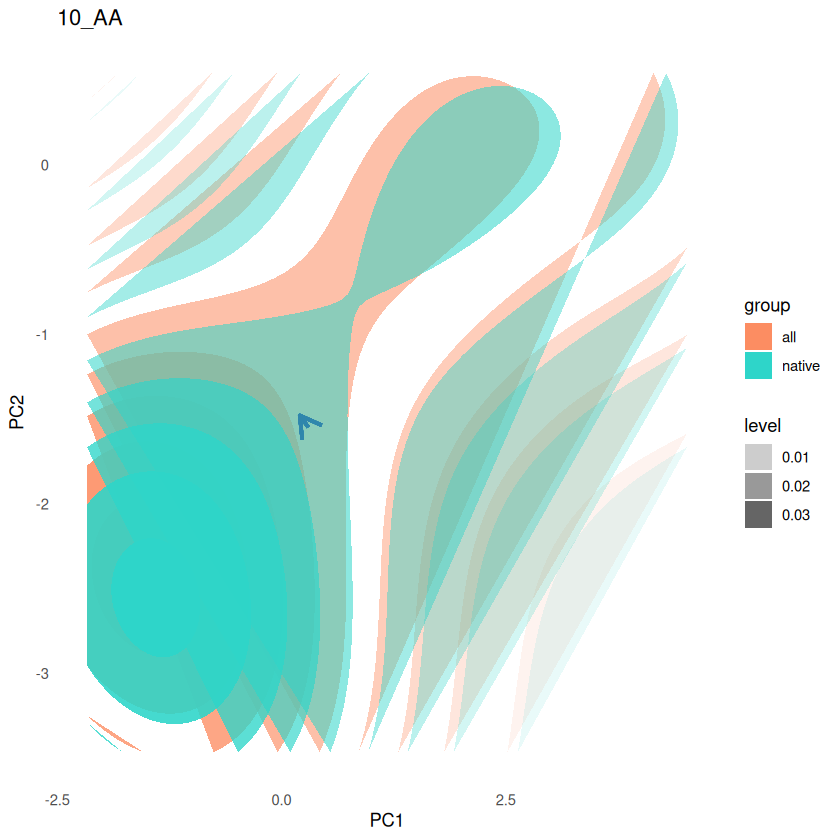

Warning message:
“Computation failed in `stat_density2d()`.
Caused by error in `if (any(h <= 0)) ...`:
! missing value where TRUE/FALSE needed”
Warning message in min(x, na.rm = na.rm):
“no non-missing arguments to min; returning Inf”
Warning message in max(x, na.rm = na.rm):
“no non-missing arguments to max; returning -Inf”
Warning message in max(f):
“no non-missing arguments to max; returning -Inf”


ERROR: [1m[33mError[39m in `stat_density_2d()`:[22m
[1m[22m[33m![39m Problem while computing stat.
[36mℹ[39m Error occurred in the 1st layer.
[1mCaused by error in `seq_len()`:[22m
[33m![39m argument must be coercible to non-negative integer


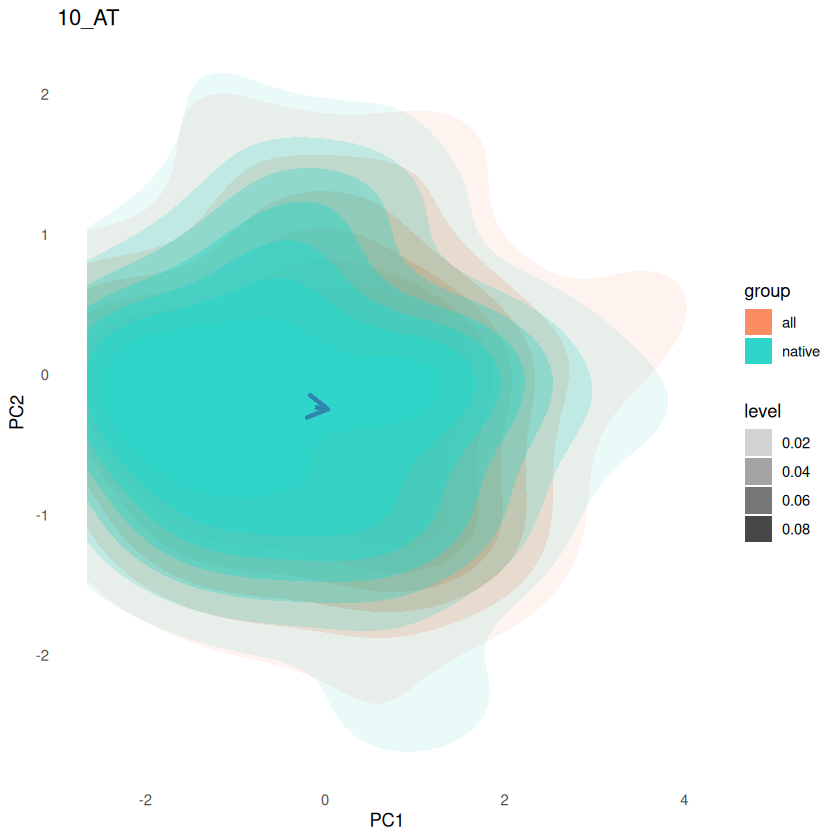

In [ ]:
library(dplyr)
library(ggplot2)
library(cowplot)
library(h3)
library(sf)

# Function to perform analysis and visualization
perform_analysis <- function(filtered_data, polygon, h3_res = 3) {
    # Calculate centroids for "native" and "all" groups
    centroids <- filtered_data %>%
        group_by(group) %>%
        summarise(PC1 = mean(PC1, na.rm = TRUE),
                            PC2 = mean(PC2, na.rm = TRUE),
                            .groups = "drop")

    centroid_native <- centroids %>% filter(group == "native")
    centroid_all <- centroids %>% filter(group == "all")

    p <- ggplot(filtered_data, aes(x = PC1, y = PC2, group = group)) +
        stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
        theme_minimal() +
        theme(panel.grid = element_blank(), legend.position = "right") +
        ggtitle(i) +
        # Add vector from "native" centroid to "all" centroid
        geom_segment(
            aes(x = centroid_native$PC1, y = centroid_native$PC2,
                    xend = centroid_all$PC1, yend = centroid_all$PC2),
            color = "#2F86AC", linewidth = 1, arrow = arrow(length = unit(0.2, "inches"))
        )

  return(p)
}

# Example usage
# Assuming combined_data is your dataset and polygon is an sf object
# Replace with your actual data

regions <- merged_regions

for (i in regions) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  filtered_data <- combined_data %>%
  filter(h3_res3 %in% region_cells)
  sub_plot <- perform_analysis(filtered_data, f)
  
  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_GBIF_wcvp_CS.pdf"),
  #pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_CS.pdf"), width = 10, height = 7)
  #dev.off()
  
  print(sub_plot)
  
}

# Plot 2D representation of trait space shift


## Biplots in different regions

In [2]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [3]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean_group.csv")
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_log10.csv")

head(combined_data)


h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,27.280,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,27.200,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,27.261,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,27.287,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,27.500,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,27.537,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460



Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE

Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Removed 499 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 642 rows containing non-finite outside the scale range
(`stat_density()`).”


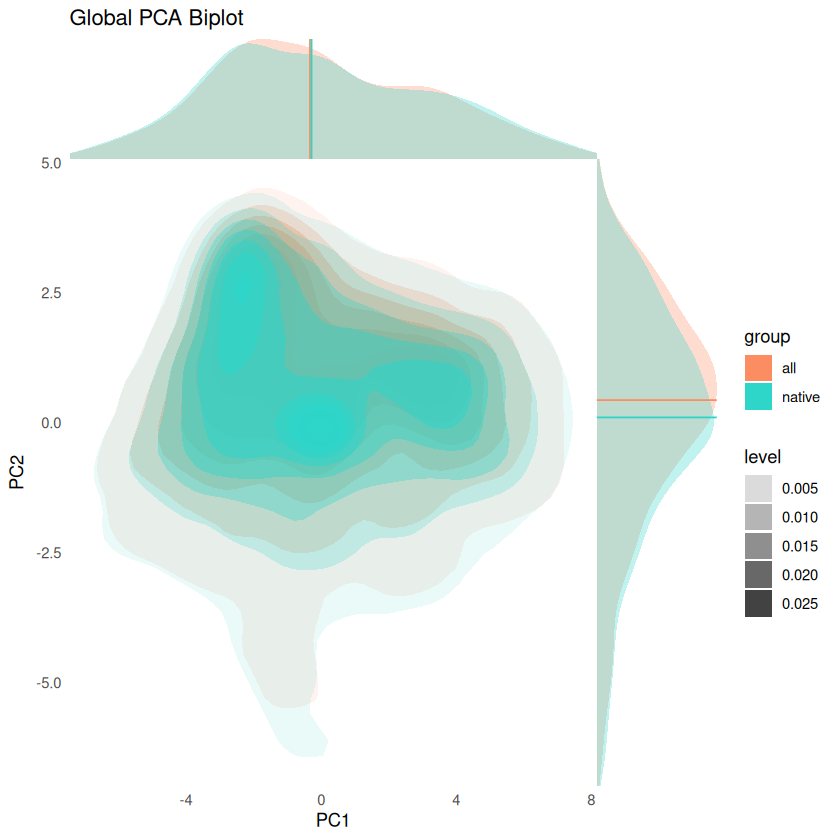

In [3]:
## Global biplot for all regions
library(dplyr)
library(ggplot2)    
library(dplyr)
library(ggplot2)
library(cowplot)
library(h3)
library(sf)

# Function to perform analysis and visualization
perform_analysis <- function(combined_data) {

  p <- ggplot(combined_data, aes(x = PC1, y = PC2, group = group)) +
    stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right") +
    ggtitle("Global PCA Biplot") 
  
  # Add density curves to the sides (x and y axes)
  xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = combined_data, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = combined_data %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
               aes(xintercept = median_PC1, color = group),
               linetype = "solid", size = 0.5) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = combined_data, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = combined_data %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 0.5) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()
  
  # Combine the density plot with the density curves
  final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()
  
  # Show the final combined plot
  return(final_plot)
}

# Example usage
sub_plot <- perform_analysis(combined_data)


print(sub_plot)


### Level plot with no loadings


polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


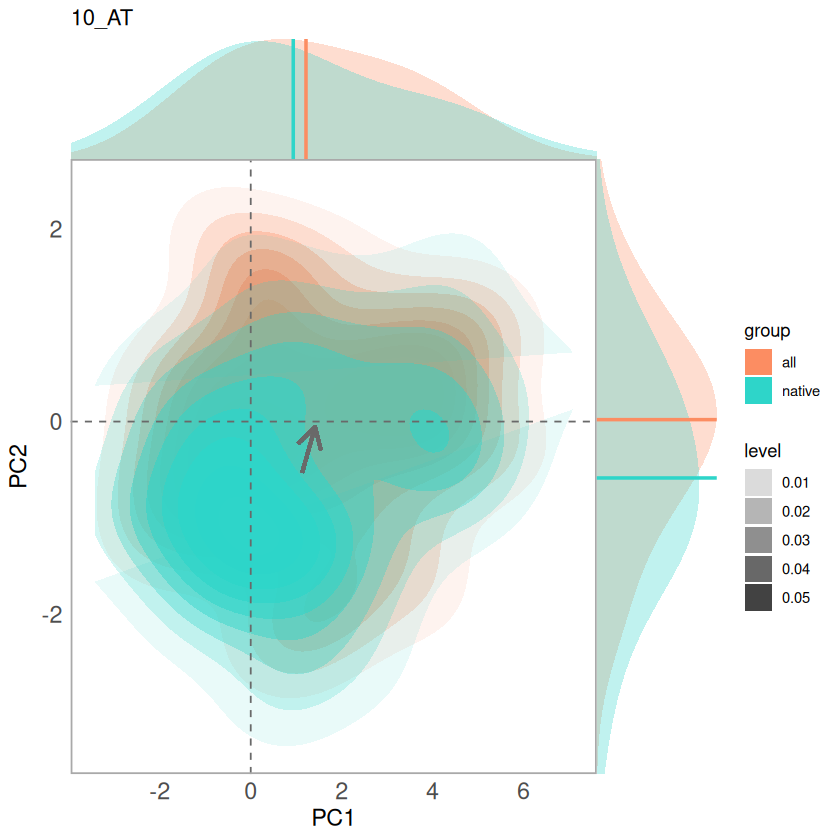

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


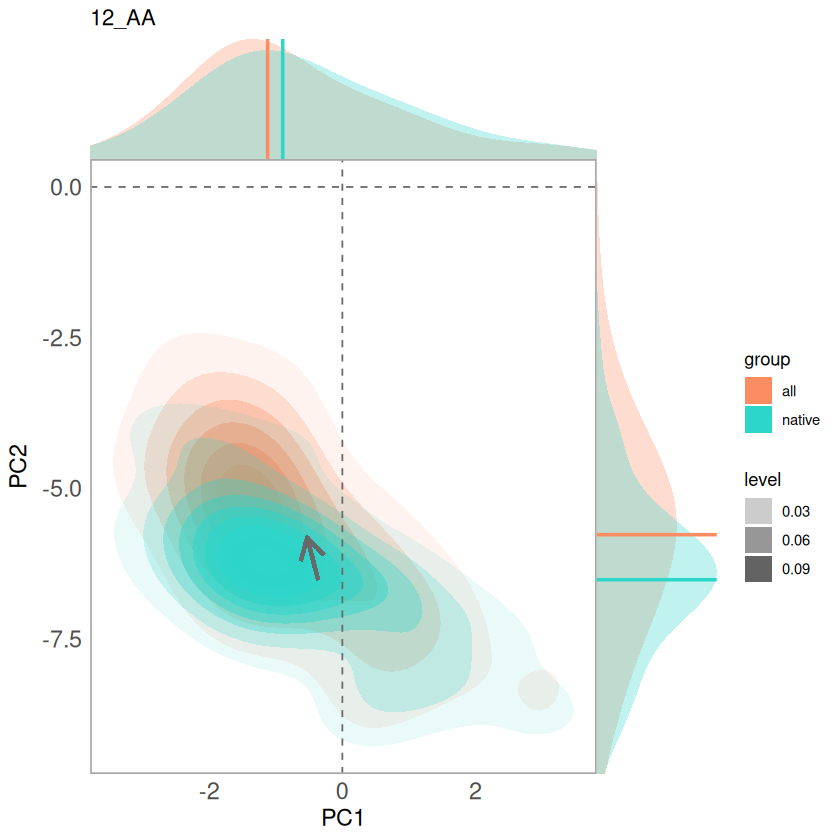

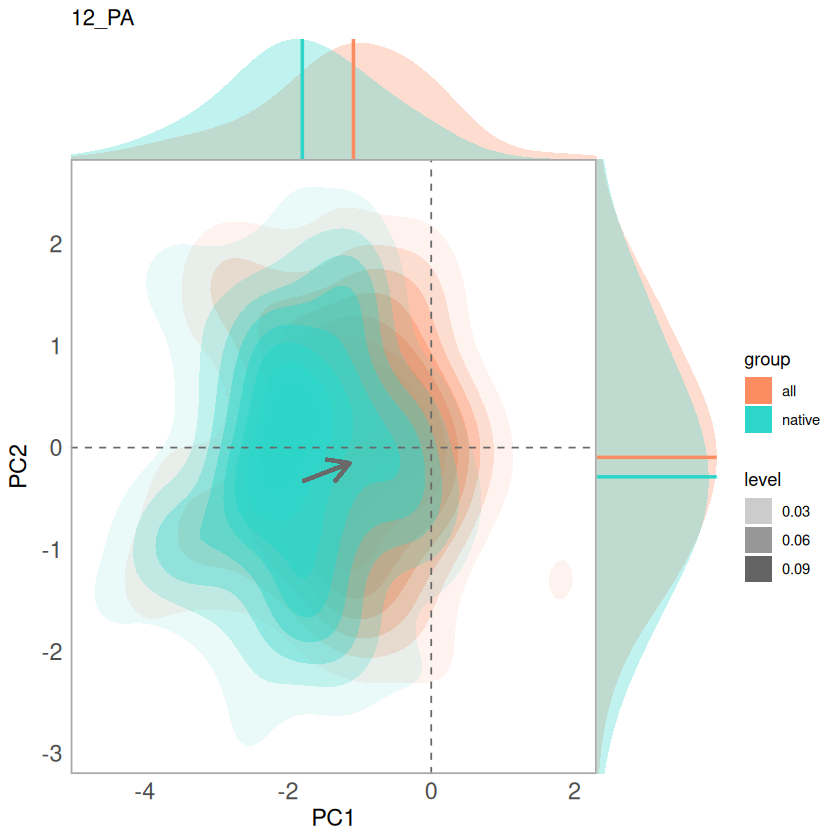

polygon has holes

Warning message:
“Removed 11 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”


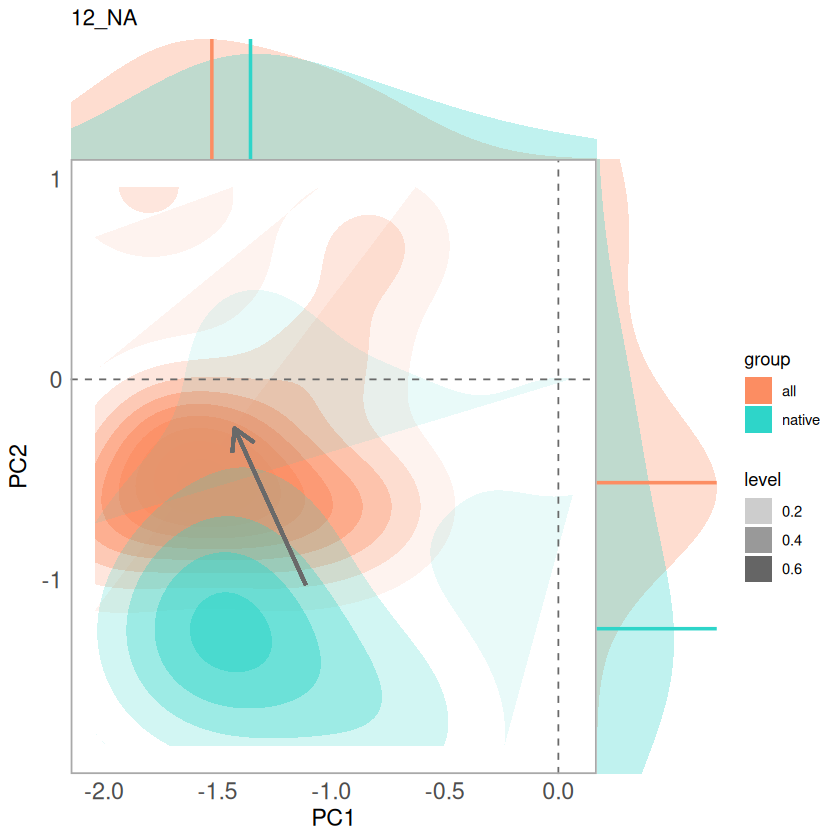

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”


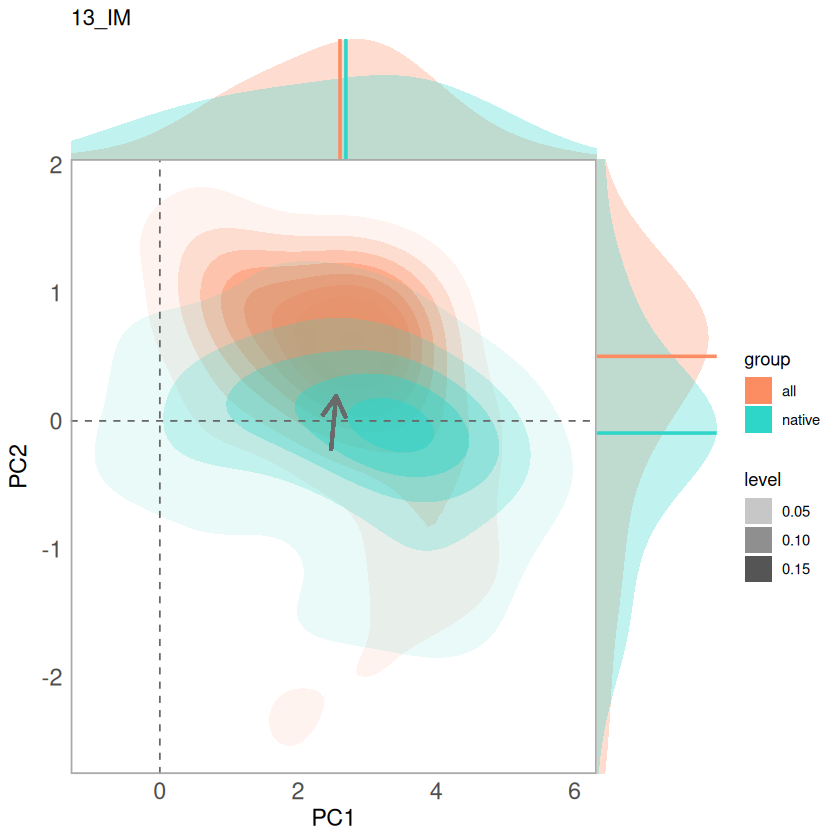

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_density()`).”


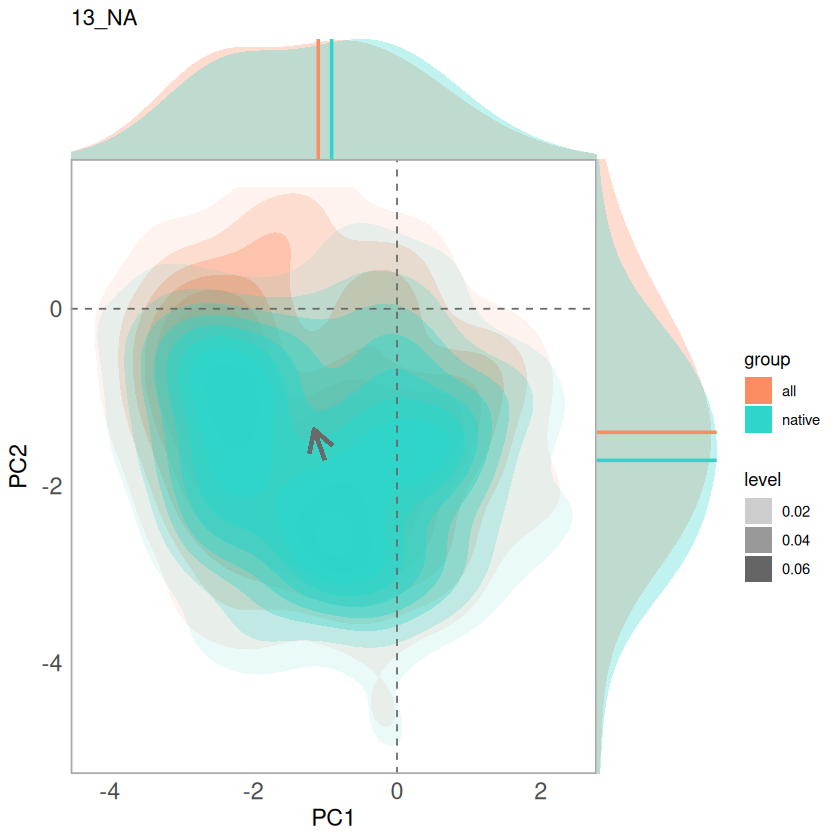

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 46 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 34 rows containing non-finite outside the scale range
(`stat_density()`).”


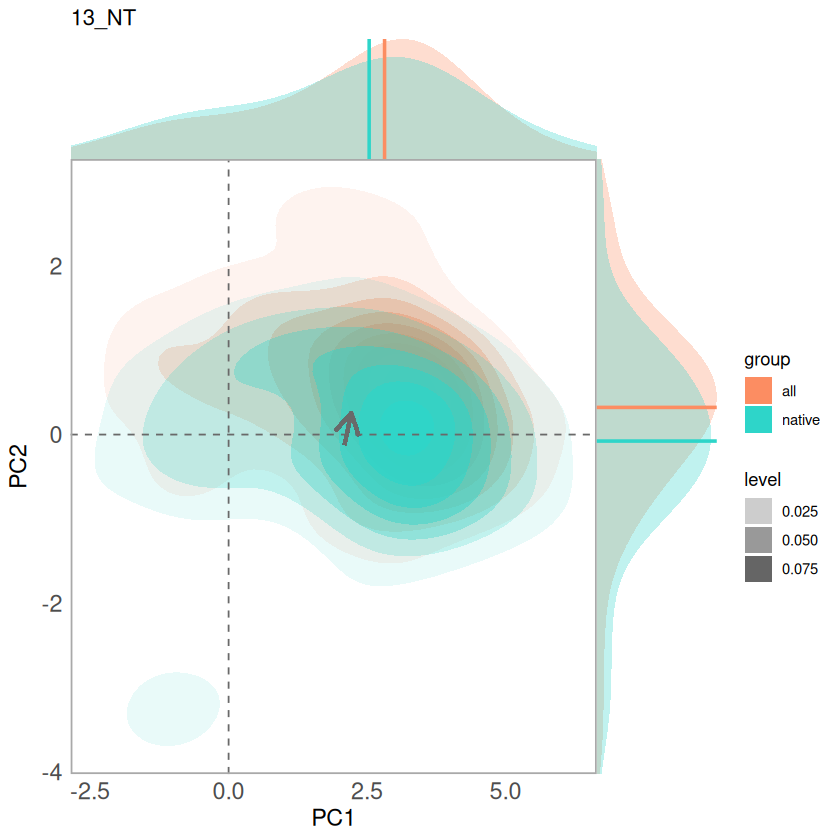

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 88 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 49 rows containing non-finite outside the scale range
(`stat_density()`).”


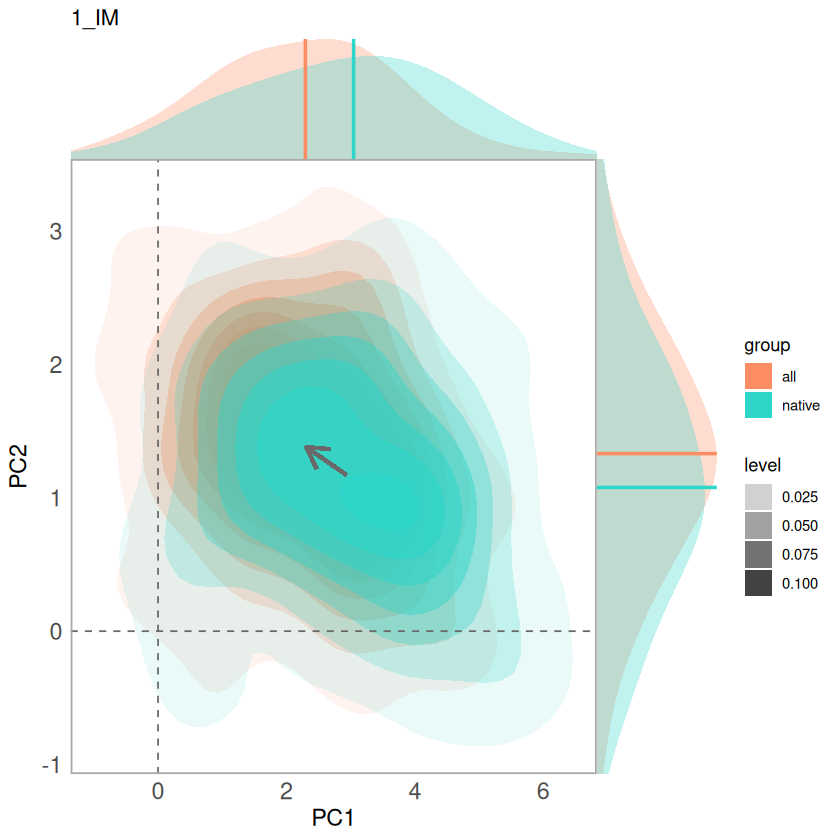

polygon has holes

Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”


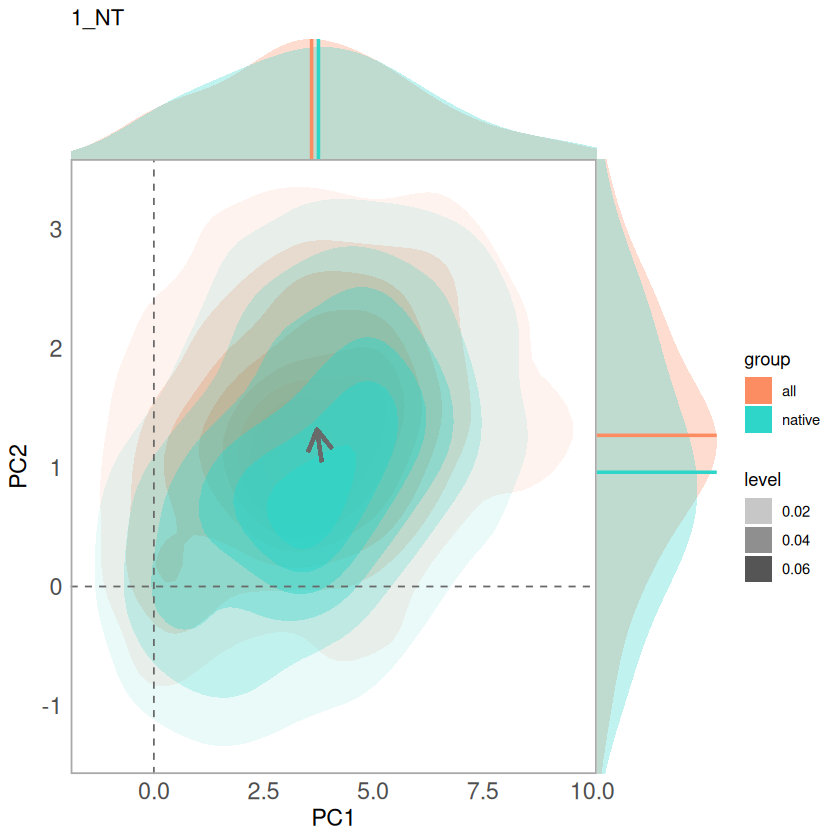

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


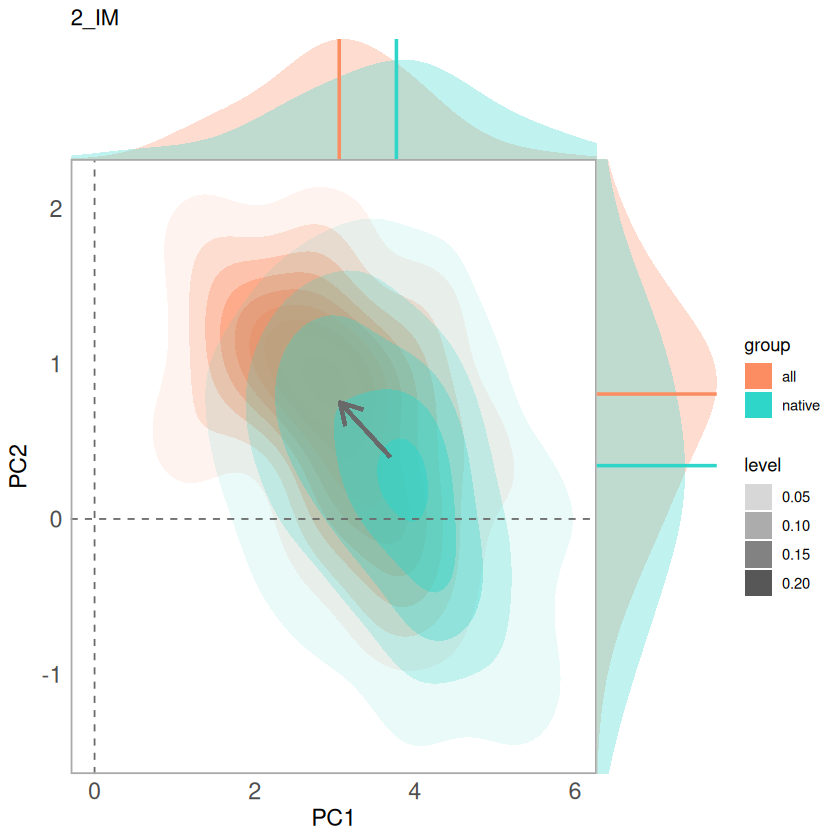

polygon has holes



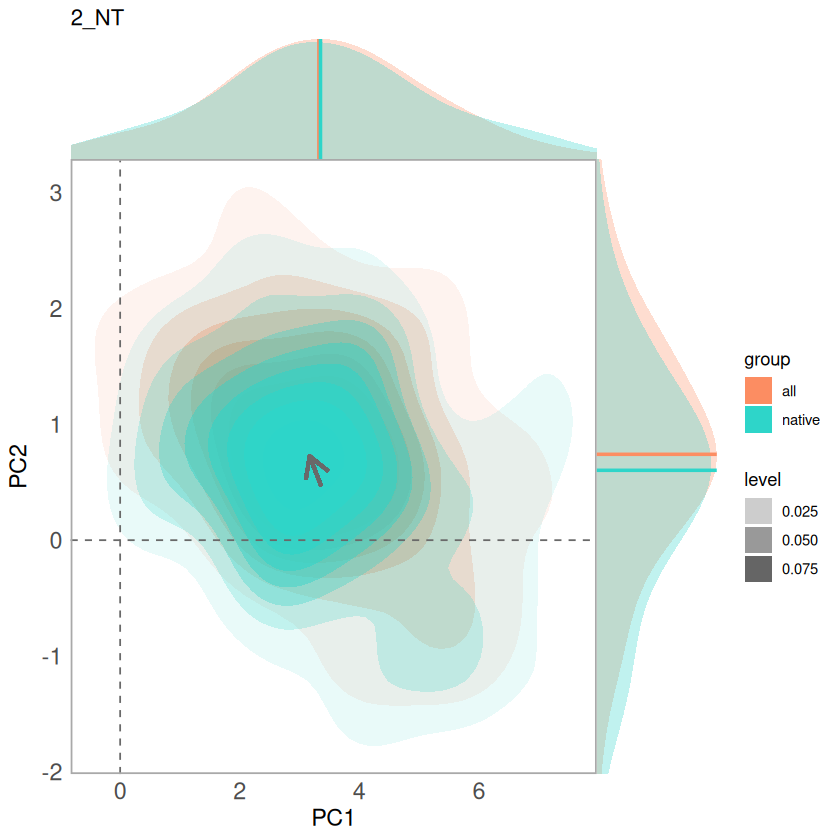

polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”


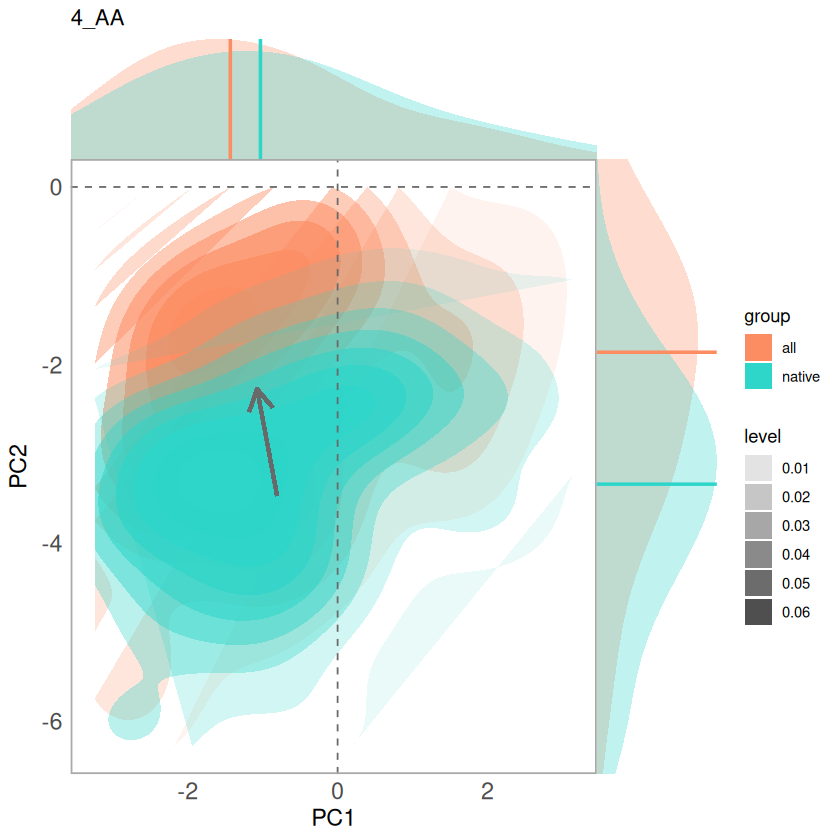

polygon has holes



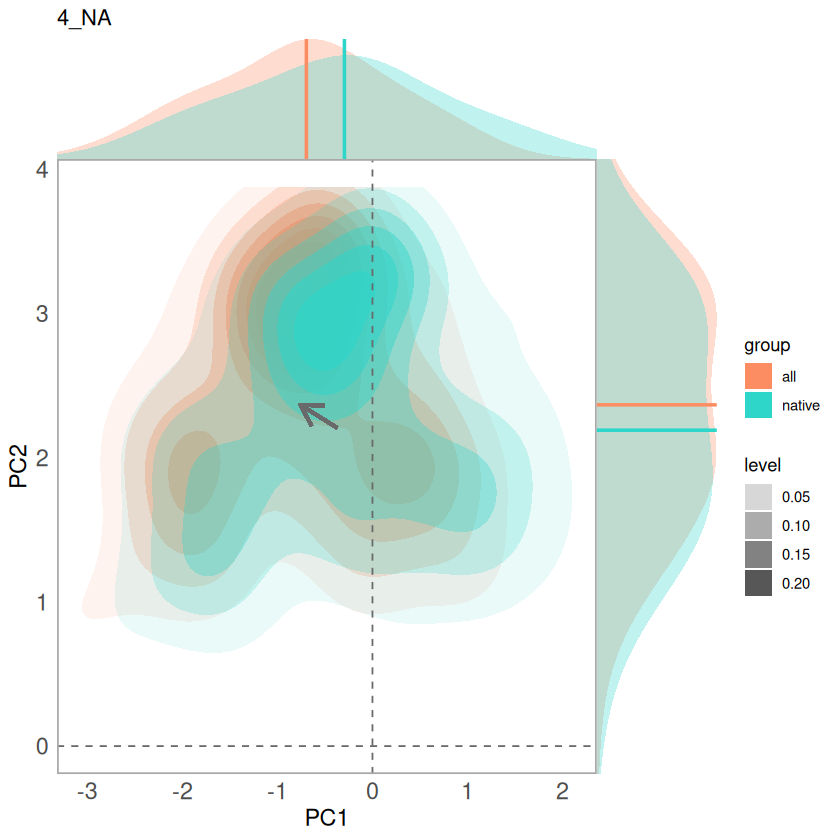

polygon has holes

polygon has holes

Warning message:
“Removed 11 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


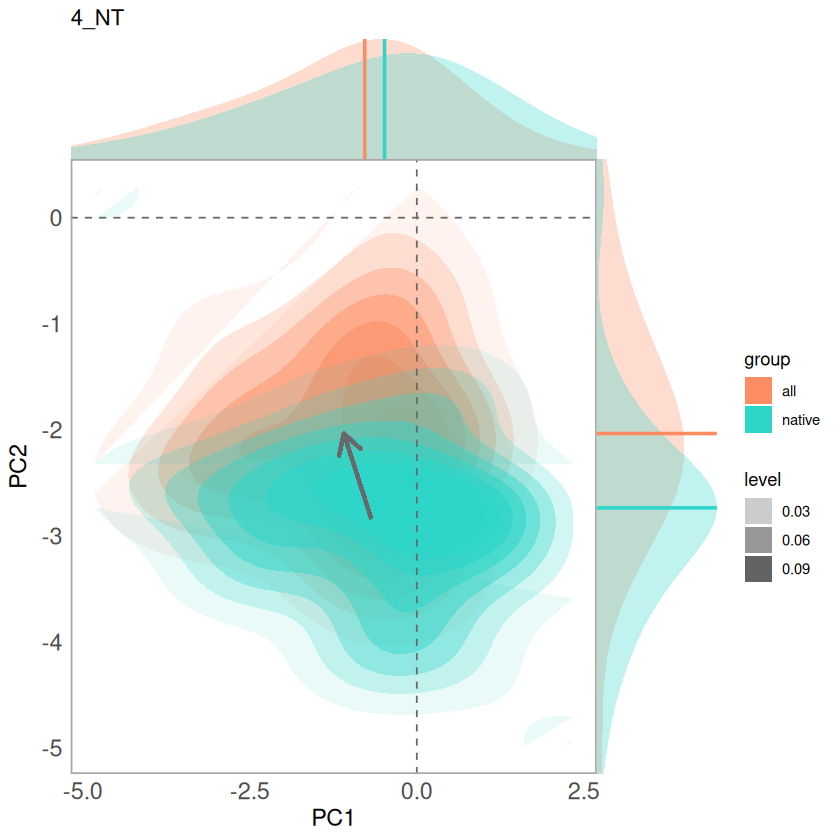

polygon has holes

Warning message:
“Removed 34 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 27 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


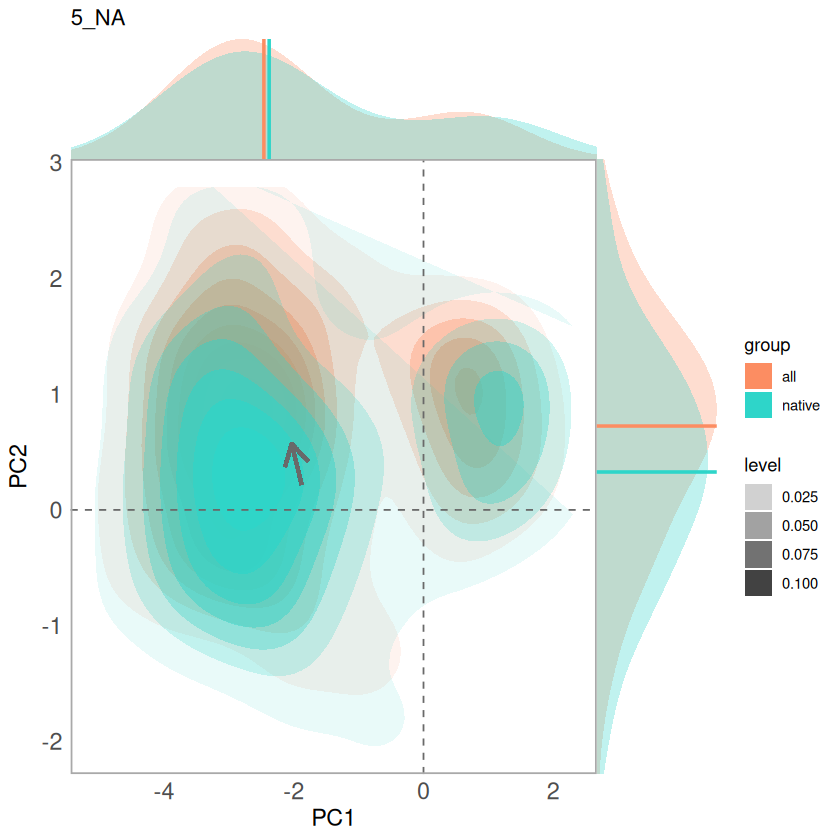

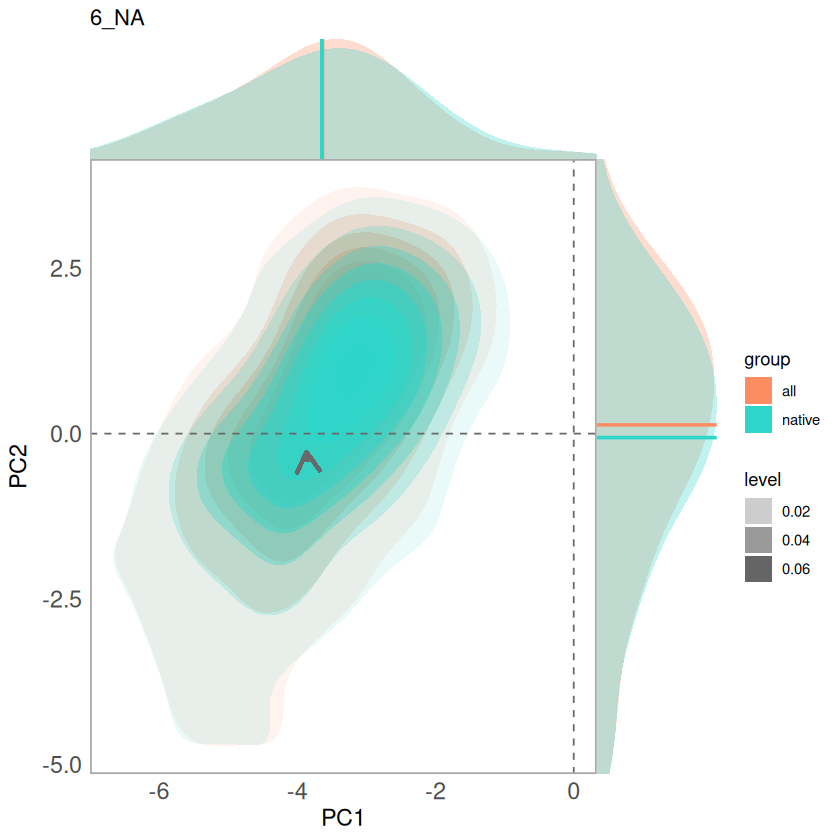

polygon has holes

polygon has holes

Warning message:
“Removed 30 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 28 rows containing non-finite outside the scale range
(`stat_density()`).”


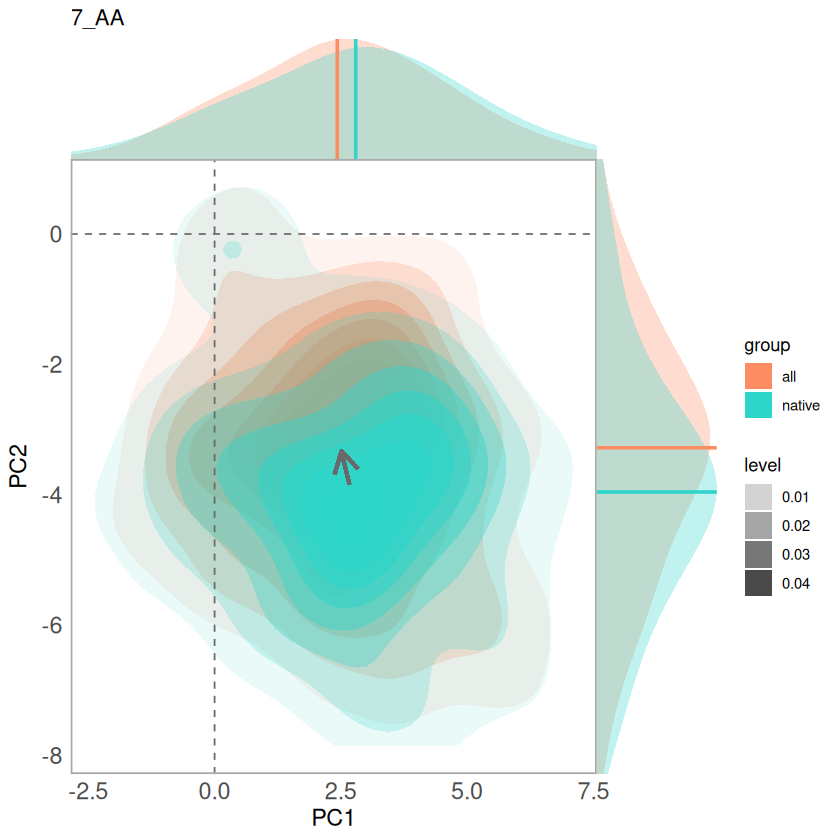

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 20 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”


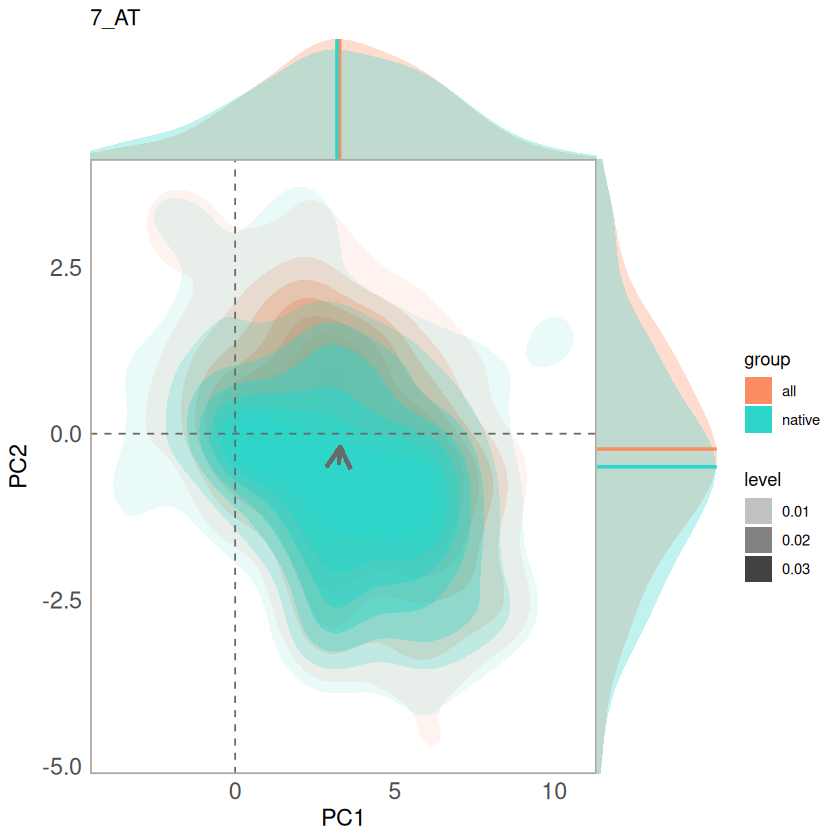

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


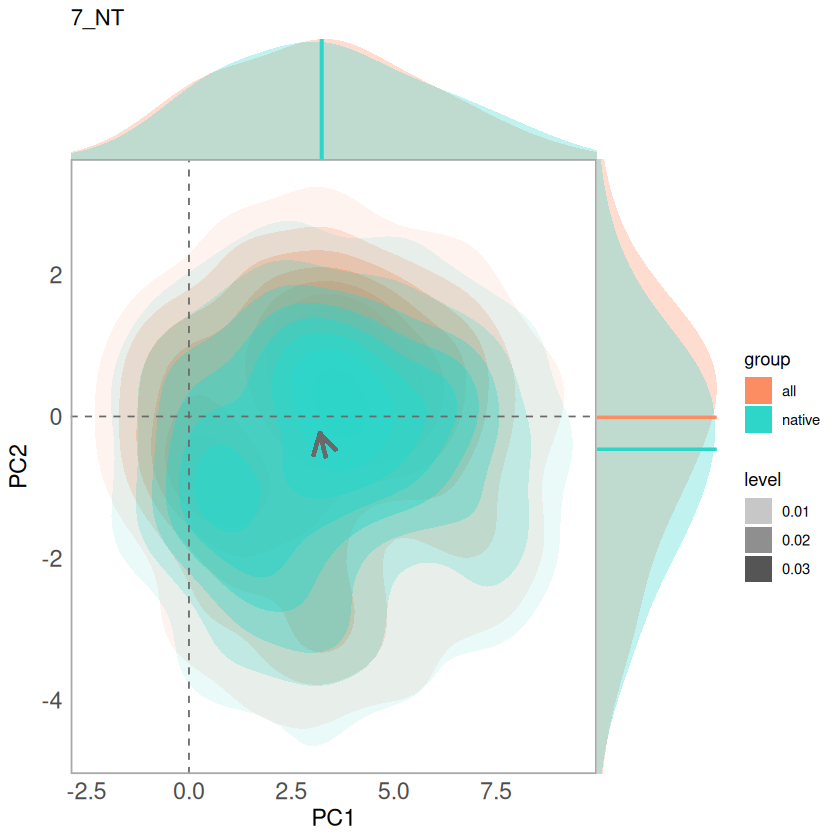

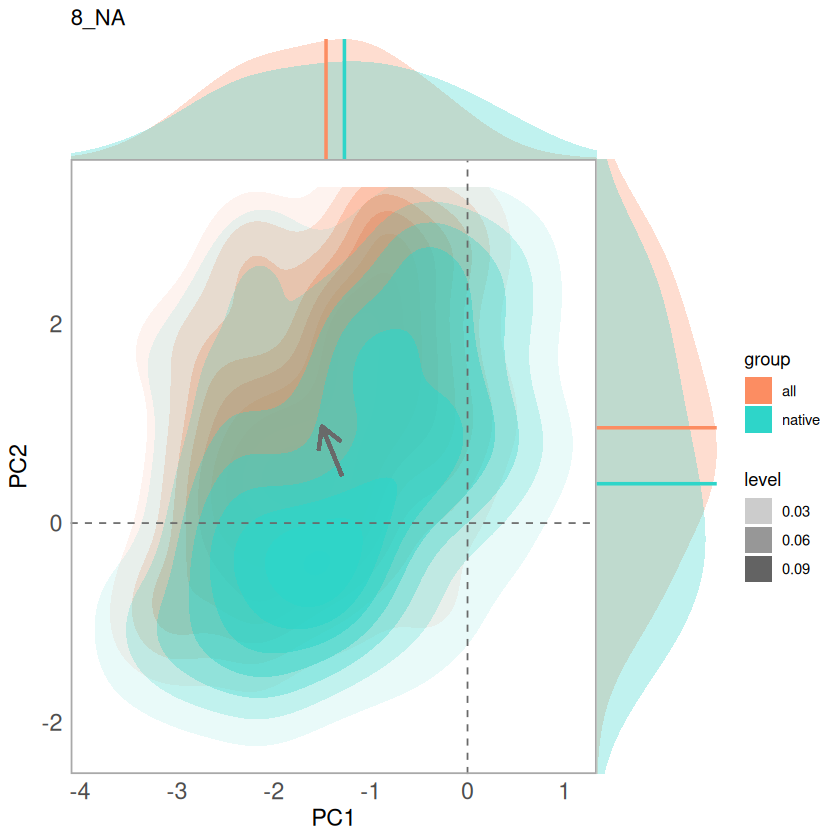

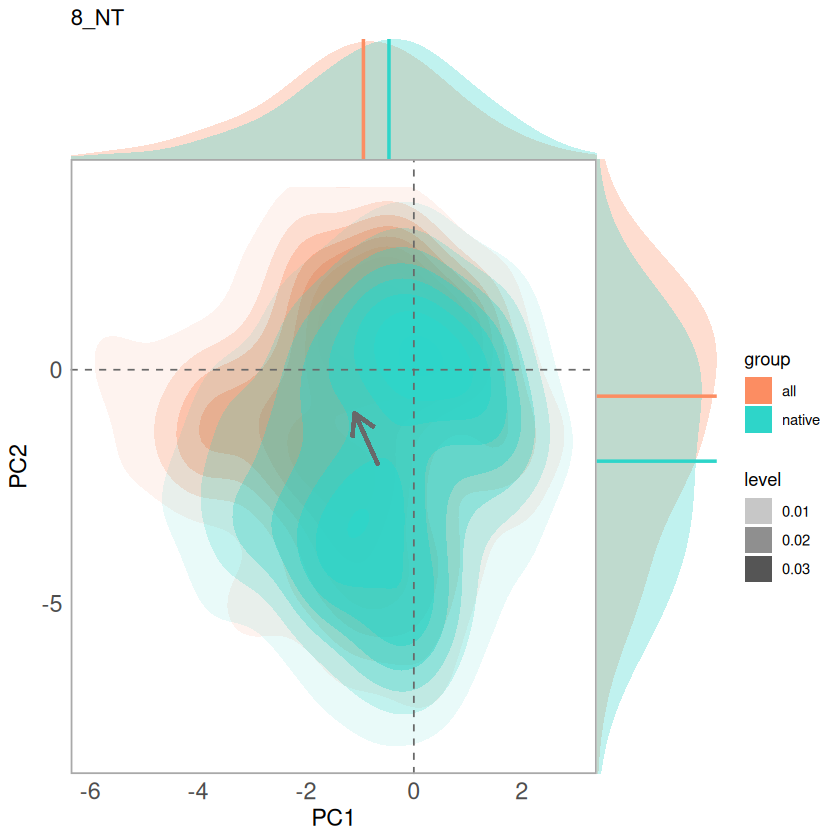

In [11]:
library(dplyr)
library(ggplot2)
library(cowplot)
library(h3)
library(sf)

# Function to perform analysis and visualization
perform_analysis <- function(filtered_data, polygon, h3_res = 3) {

#   # Calculate padded ranges with 0.5 extension on each side
# x_range <- range(filtered_data$PC1, na.rm = TRUE)
# y_range <- range(filtered_data$PC2, na.rm = TRUE)
# 
# xlim_padded <- c(x_range[1] - 0.5, x_range[2] + 0.5)
# ylim_padded <- c(y_range[1] - 0.5, y_range[2] + 0.5)


  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, group = group)) +
    stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
    #coord_cartesian(xlim = xlim_padded, ylim = ylim_padded) +  # add padded limits here
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
      axis.title = element_text(size = 14),  # Increase font size for axis labels
      axis.text = element_text(size = 14),  # Increase font size for axis numbers
      panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    theme(panel.grid = element_blank(), legend.position = "right") +
    ggtitle(i)
  
  # Add vector from "native" centroid to "all" centroid
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")

  centroid_native <- centroids %>% filter(group == "native")
  centroid_all <- centroids %>% filter(group == "all")

  p <- p +
    geom_segment(
      aes(x = centroid_native$PC1, y = centroid_native$PC2,
          xend = centroid_all$PC1, yend = centroid_all$PC2),
      color = "dimgrey", linewidth = 1, arrow = arrow(length = unit(0.2, "inches"))
    )
  # Add grey line at 0,0
  p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
  # Add density curves to the sides (x and y axes)
  xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = filtered_data, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
           aes(xintercept = median_PC1, color = group),
           linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = filtered_data, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()
  
  # Combine the density plot with the density curves
  final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()
  
  # Show the final combined plot

  return(final_plot)
}

# Example usage
# Assuming combined_data is your dataset and polygon is an sf object
# Replace with your actual data

regions <- merged_regions

for (i in regions) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  filtered_data <- combined_data %>%
  filter(h3_res3 %in% region_cells)
  sub_plot <- perform_analysis(filtered_data, f)
  
  #pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_wcvp_Olsen.pdf"),
  png(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_CS_log10.png"),
      width = 10, height = 7, units = "in", res = 300)
  print(sub_plot)
  dev.off()
  
  print(sub_plot)
  
}

polygon has holes

polygon has holes

Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”


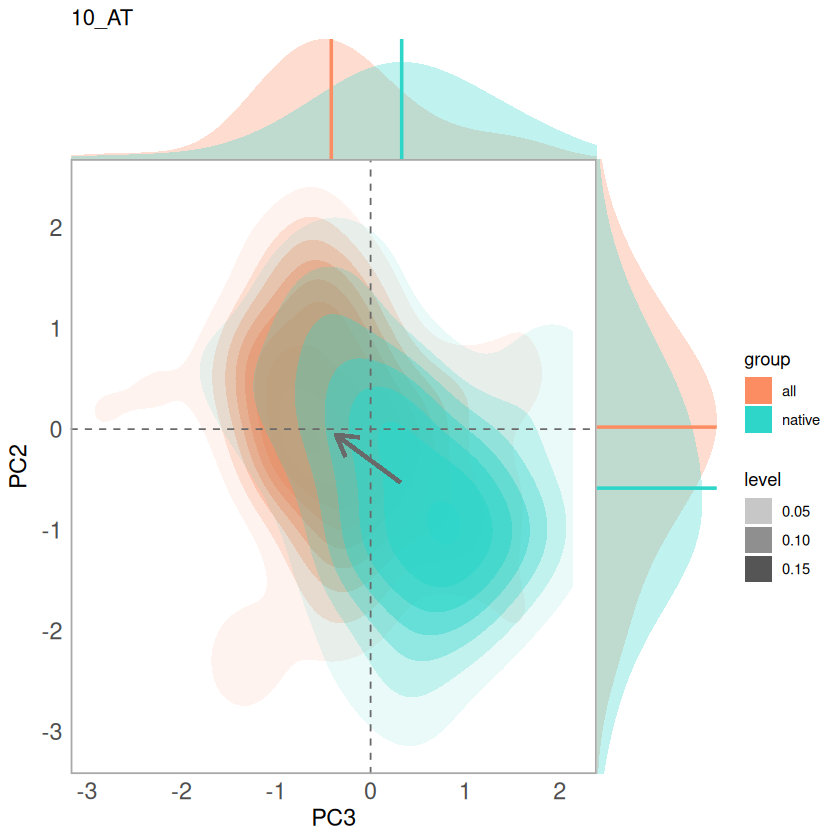

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


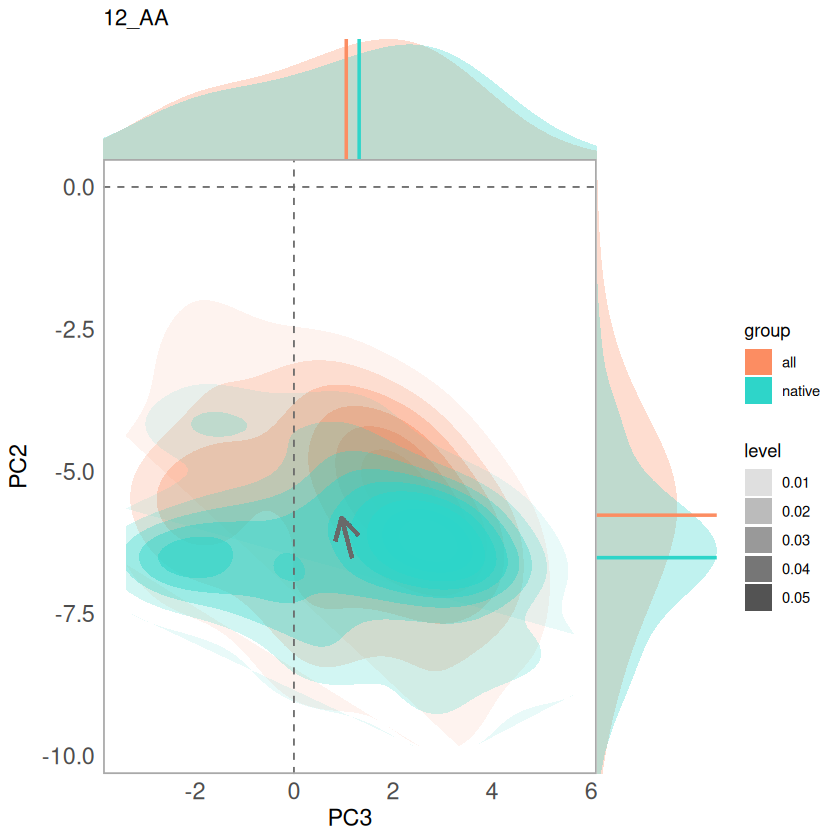

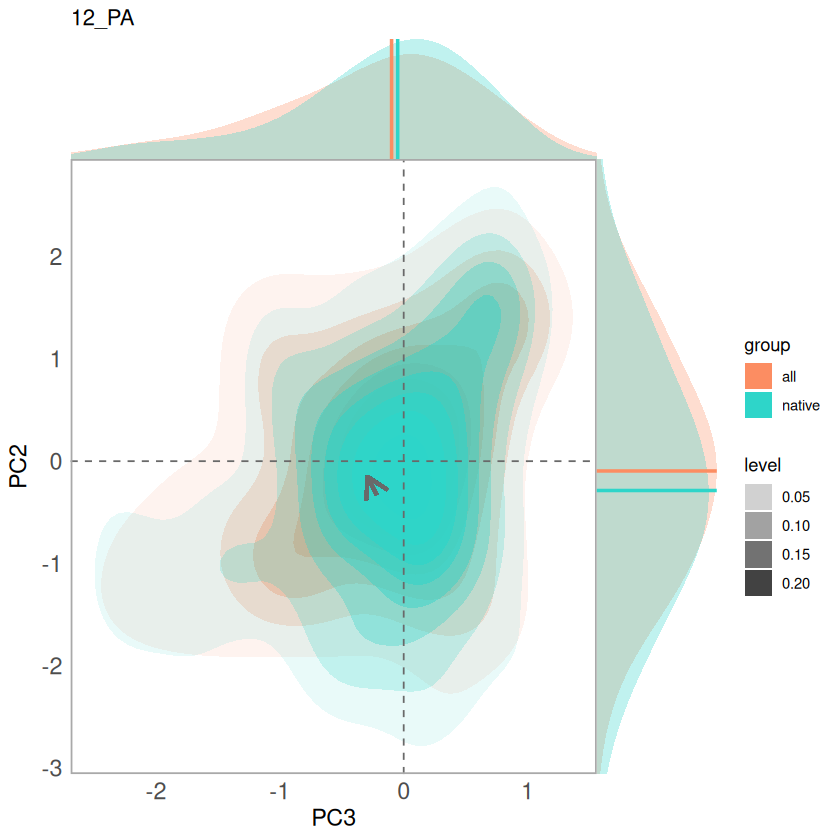

polygon has holes

Warning message:
“Removed 17 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”


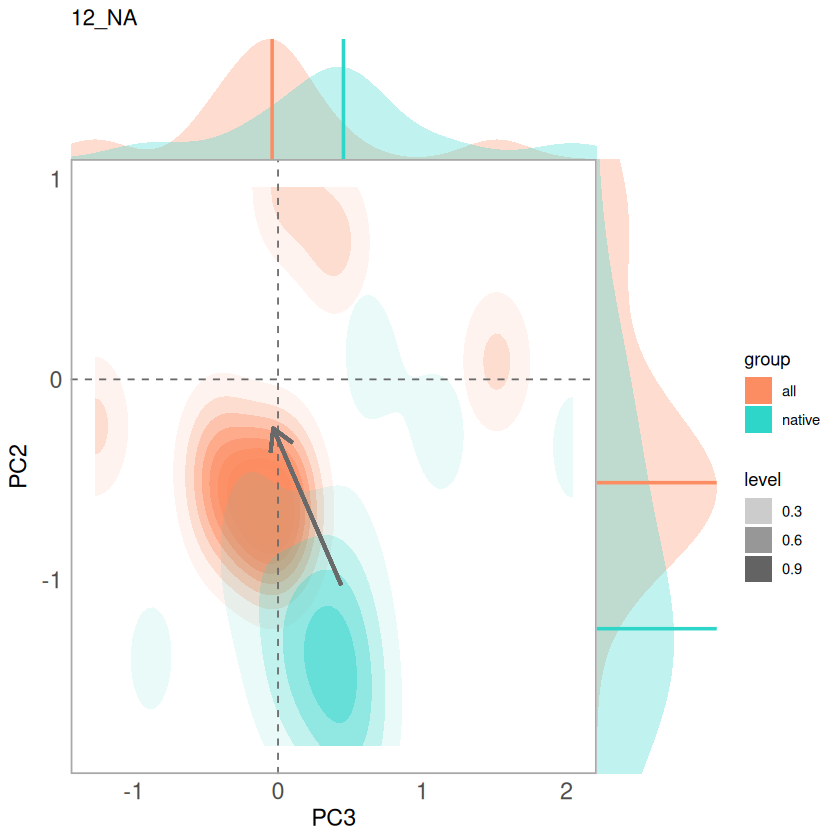

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


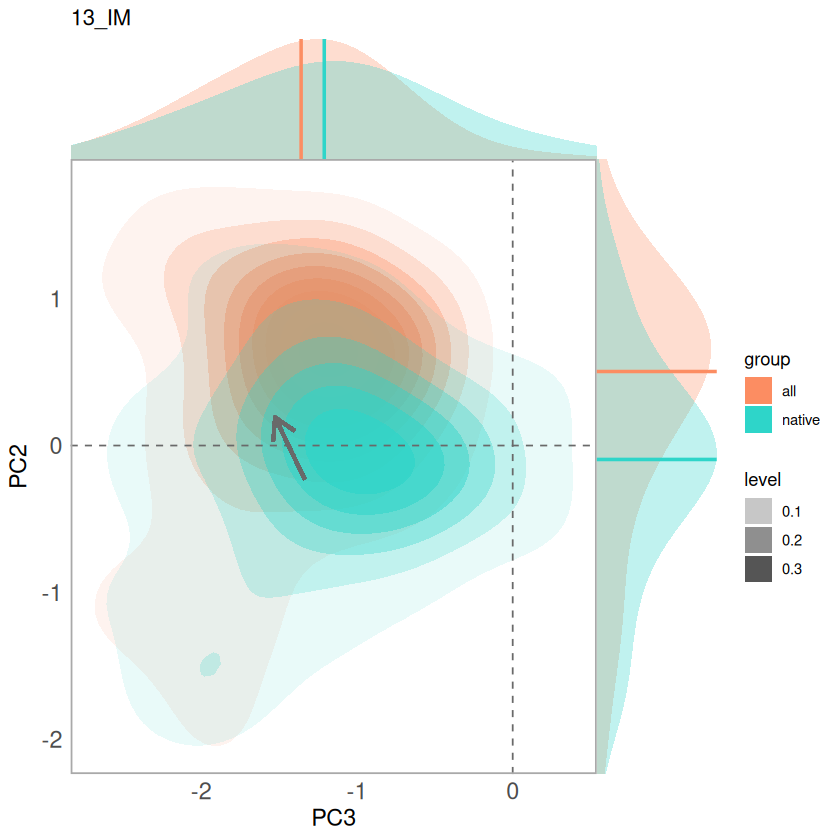

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


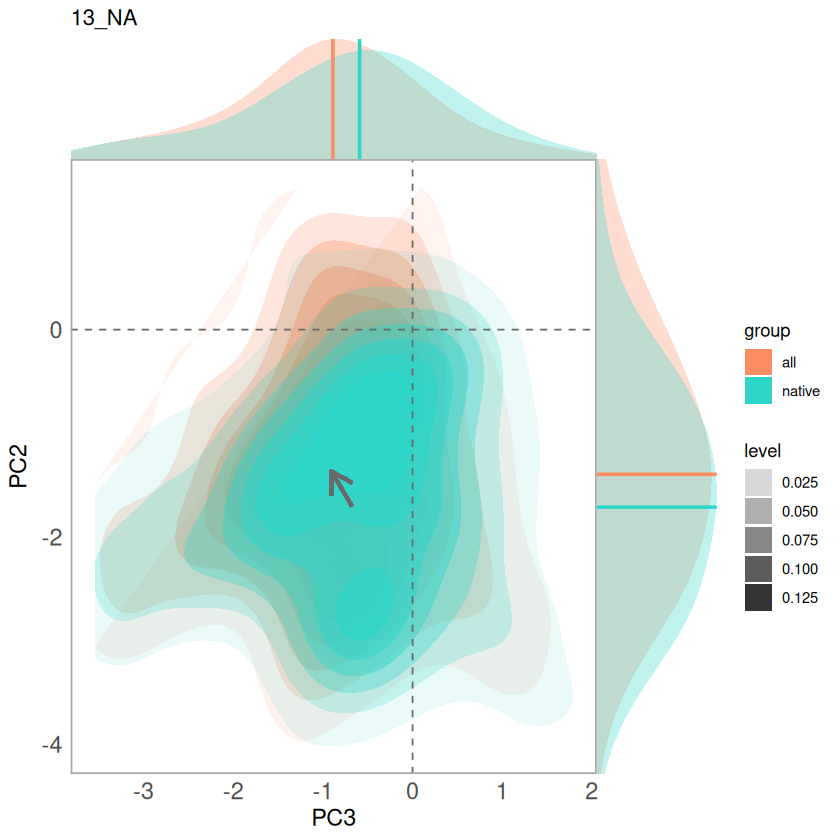

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 52 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 36 rows containing non-finite outside the scale range
(`stat_density()`).”


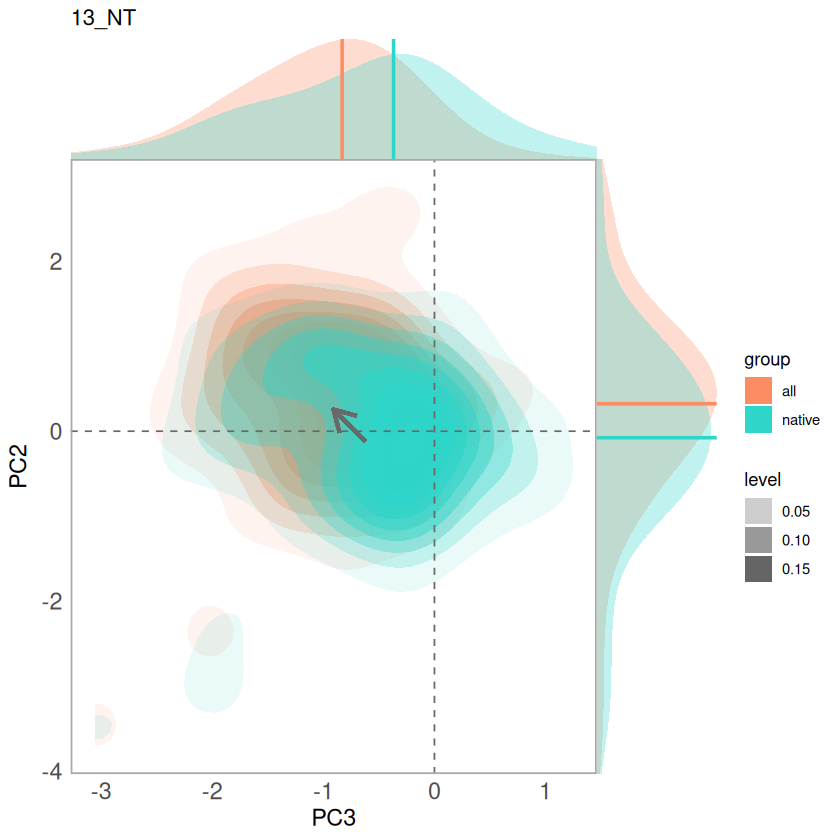

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 67 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 79 rows containing non-finite outside the scale range
(`stat_density()`).”


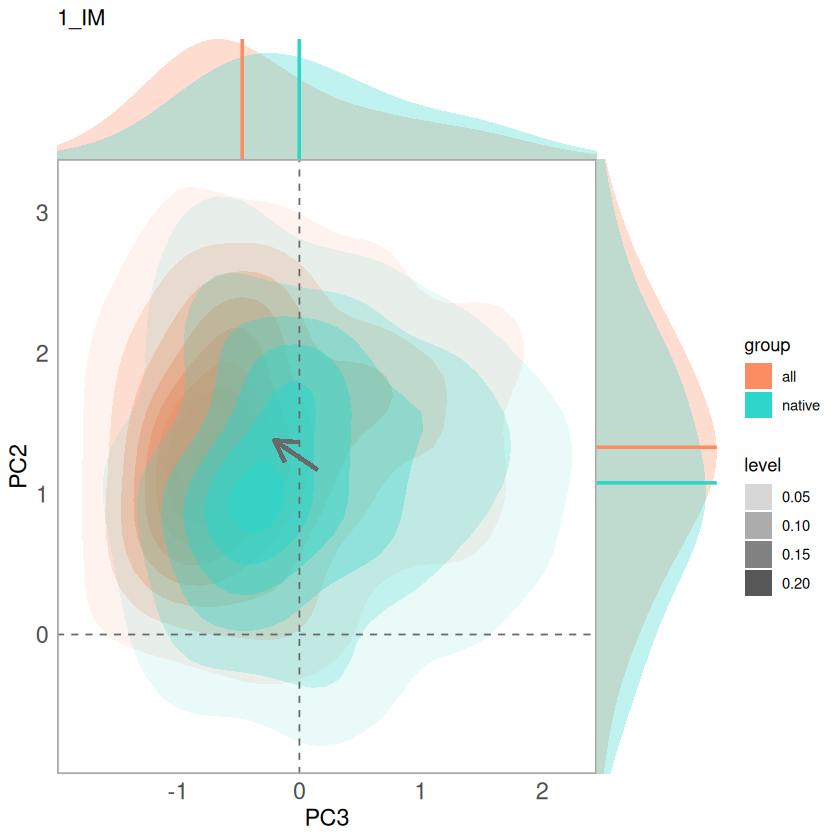

polygon has holes

Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_density()`).”


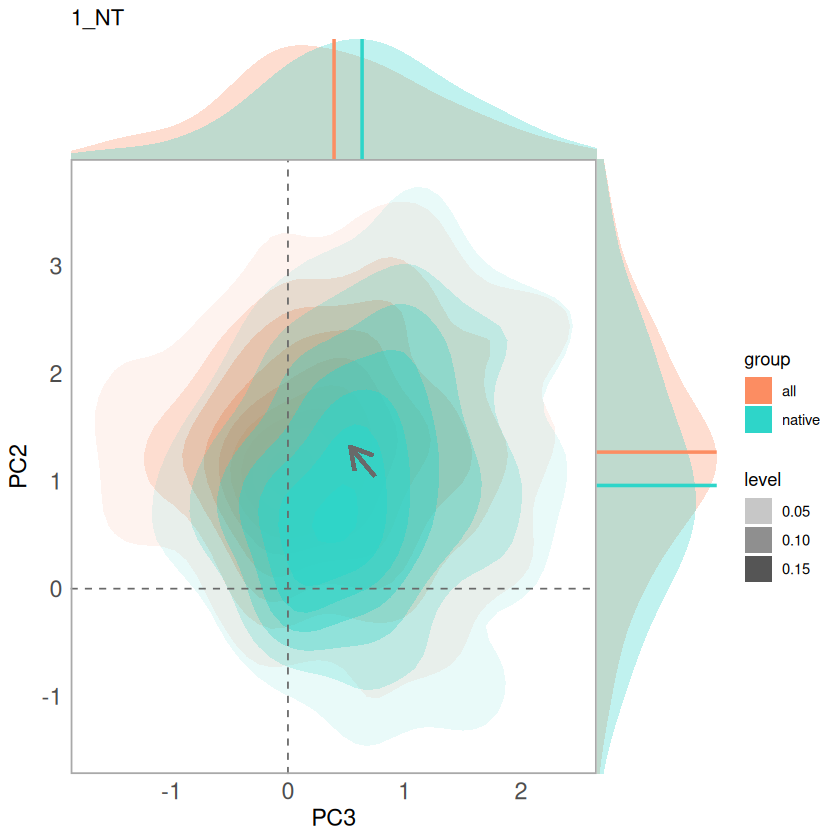

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


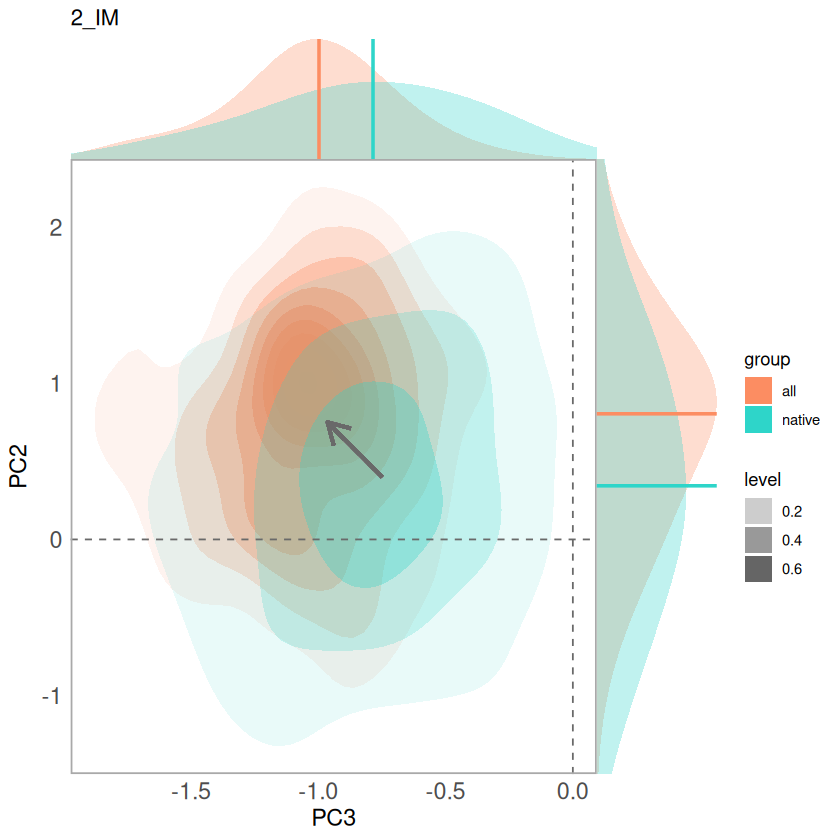

polygon has holes



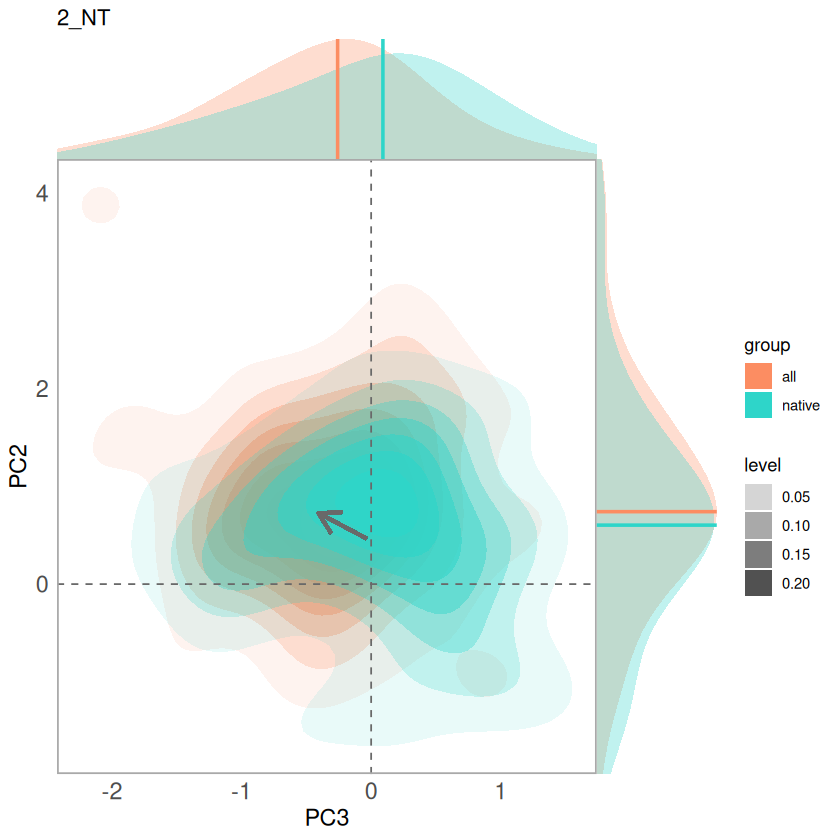

polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_density()`).”


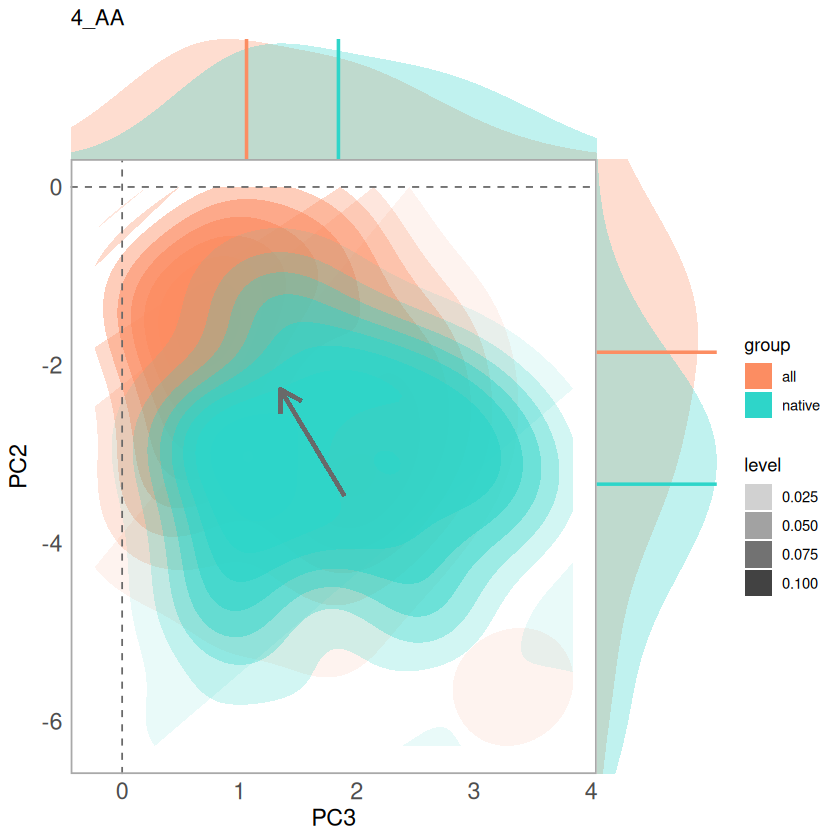

polygon has holes



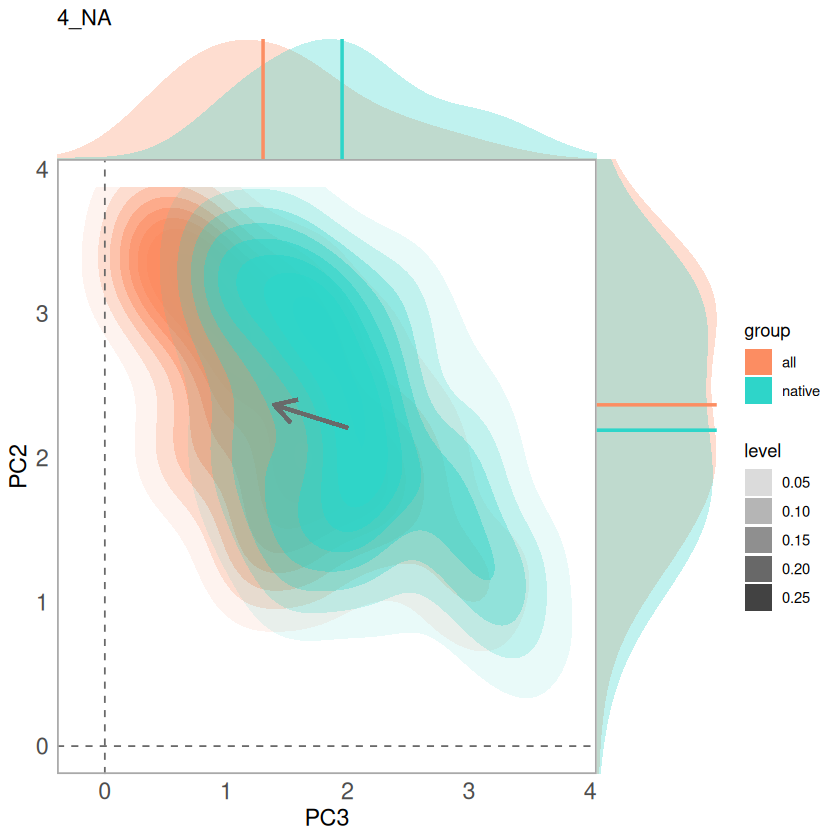

polygon has holes

polygon has holes

Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”


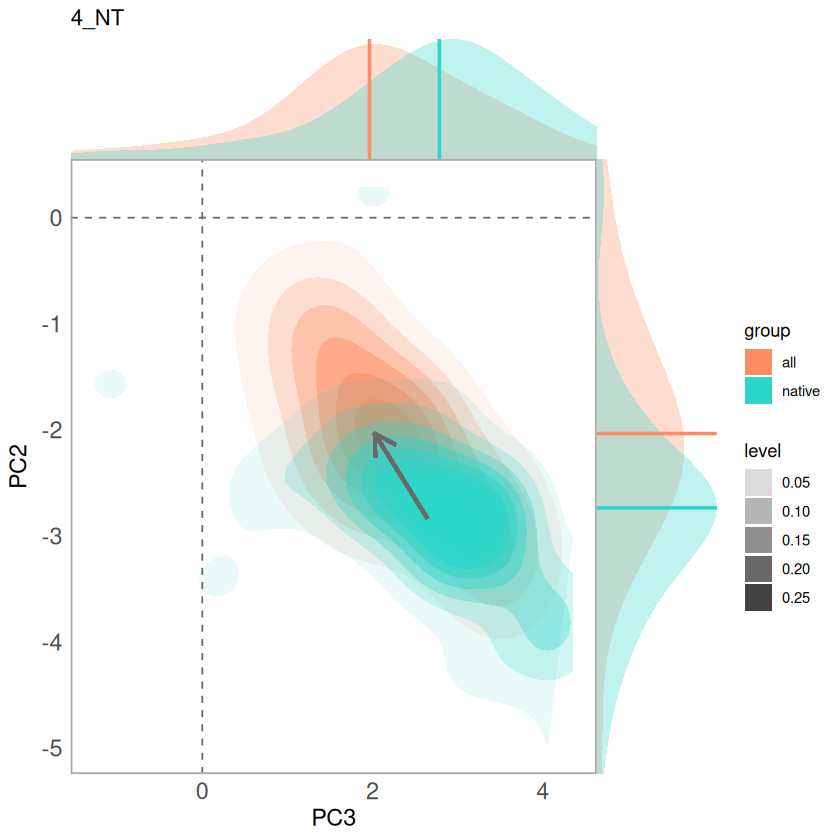

polygon has holes

Warning message:
“Removed 24 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 23 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


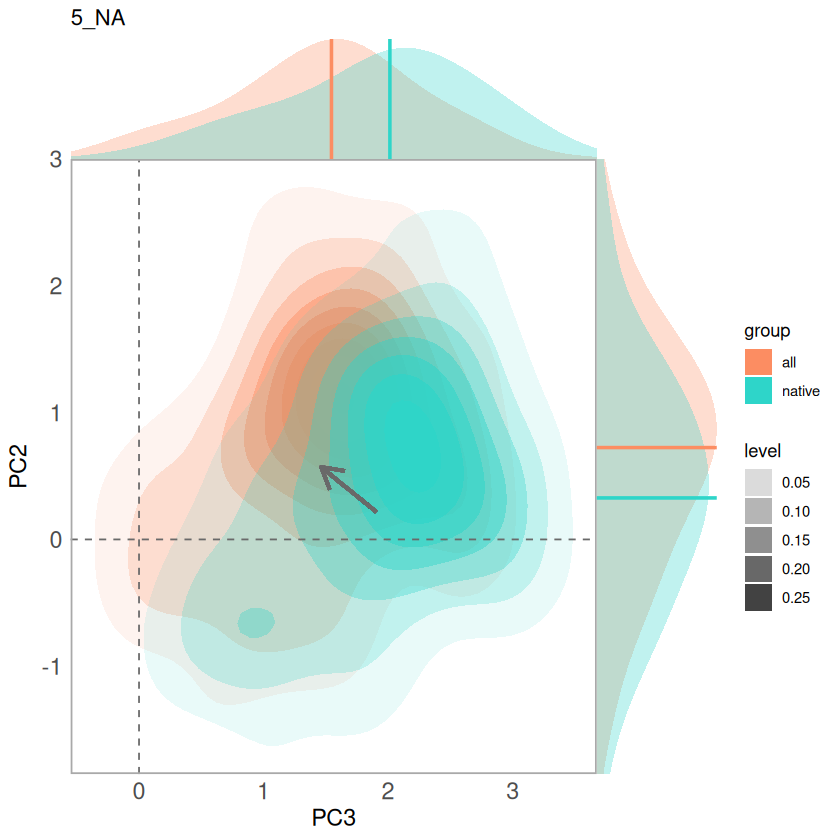

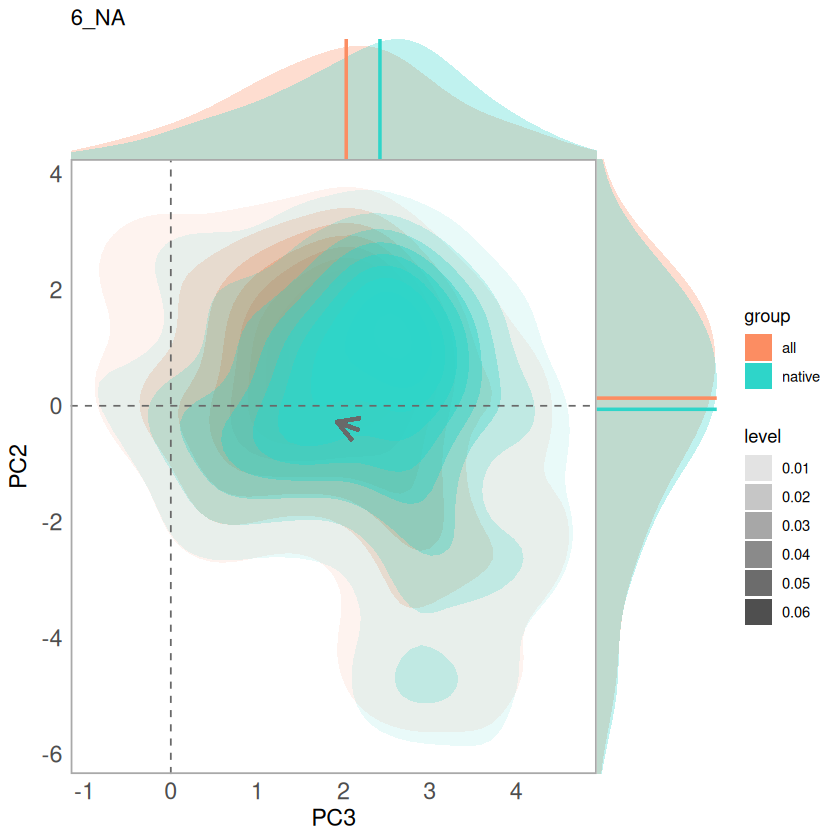

polygon has holes

polygon has holes

Warning message:
“Removed 50 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 70 rows containing non-finite outside the scale range
(`stat_density()`).”


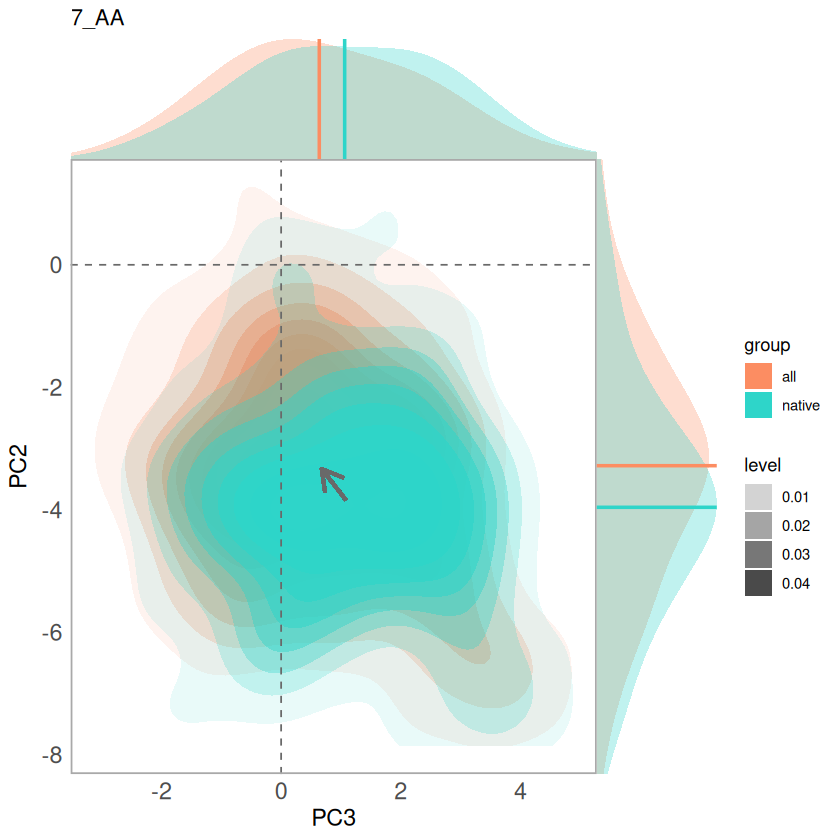

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 24 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 11 rows containing non-finite outside the scale range
(`stat_density()`).”


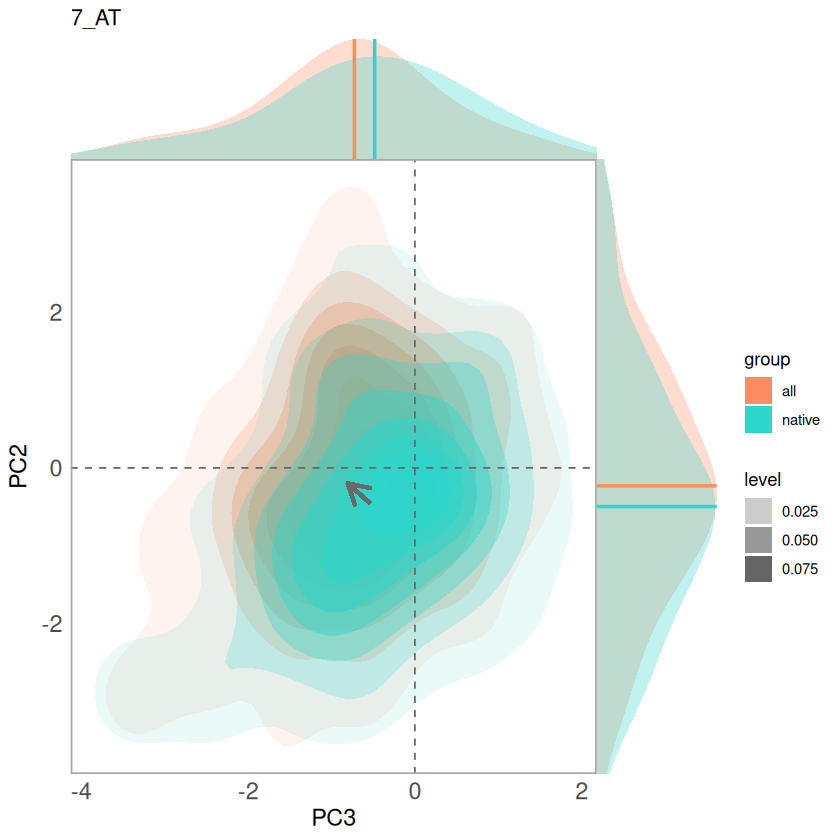

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


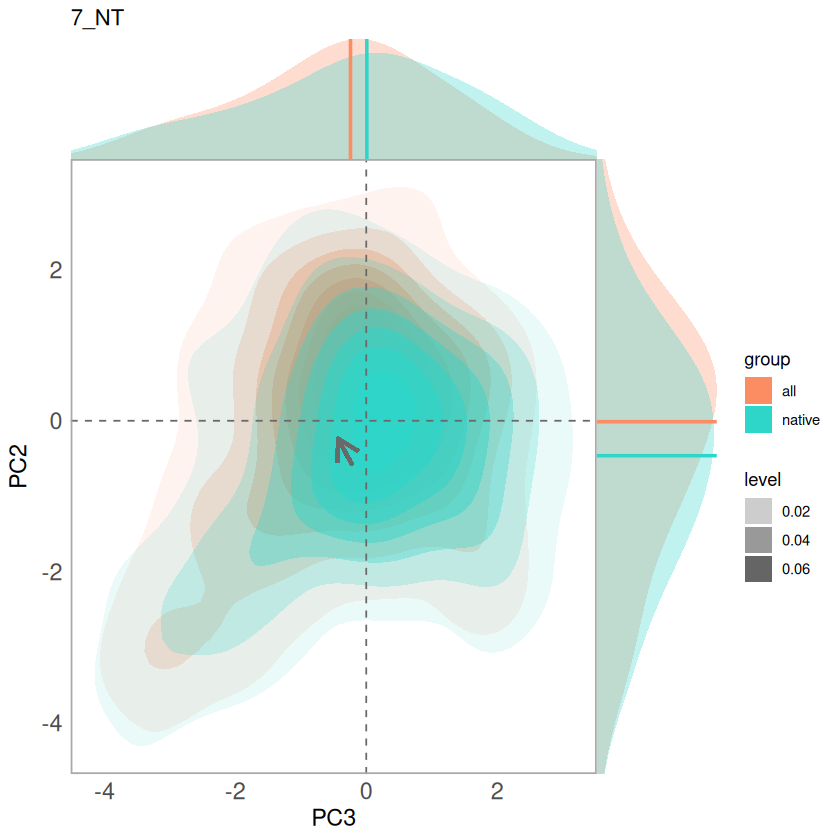

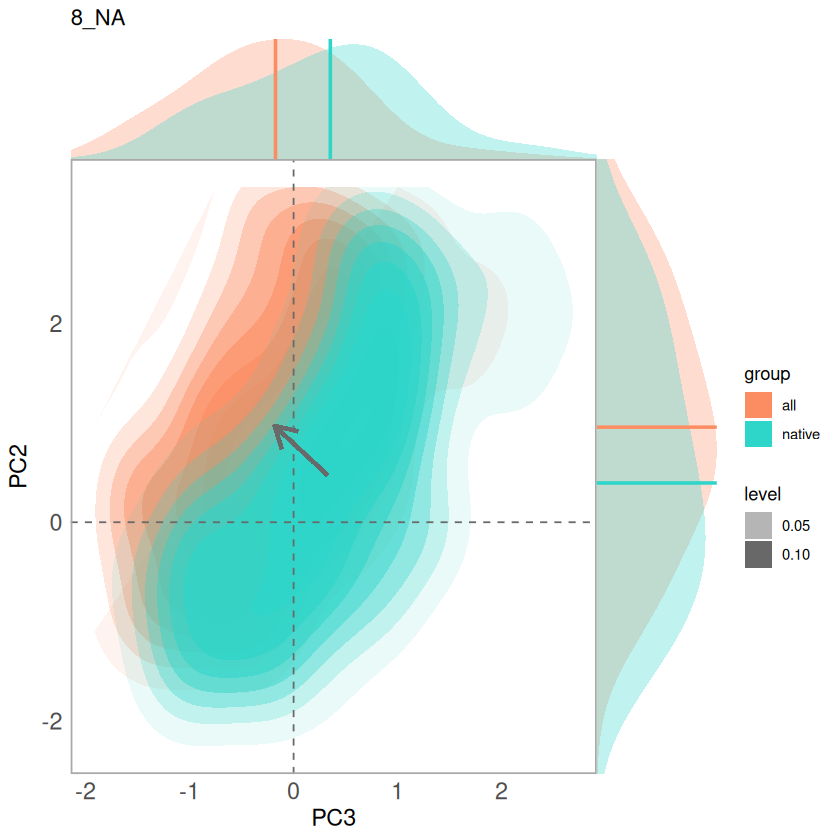

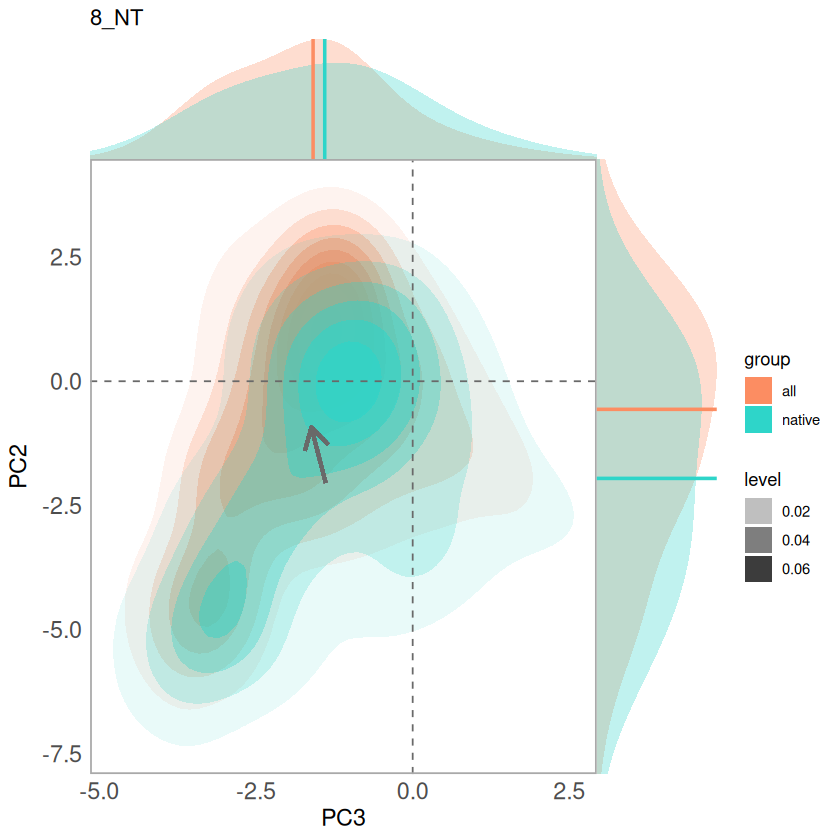

In [15]:
# Function to perform analysis and visualization
perform_analysis <- function(filtered_data, polygon, h3_res = 3) {

    p <- ggplot(filtered_data, aes(x = PC3, y = PC2, group = group)) +
        stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
        theme_minimal() +
        theme(panel.grid = element_blank(), legend.position = "right",
            axis.title = element_text(size = 14),  # Increase font size for axis labels
            axis.text = element_text(size = 14),  # Increase font size for axis numbers
            panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
        theme(panel.grid = element_blank(), legend.position = "right") +
        ggtitle(i)
    
    # Add vector from "native" centroid to "all" centroid
    centroids <- filtered_data %>%
        group_by(group) %>%
        summarise(PC3 = mean(PC3, na.rm = TRUE),
                            PC2 = mean(PC2, na.rm = TRUE),
                            .groups = "drop")

    centroid_native <- centroids %>% filter(group == "native")
    centroid_all <- centroids %>% filter(group == "all")

    p <- p +
        geom_segment(
            aes(x = centroid_native$PC3, y = centroid_native$PC2,
                    xend = centroid_all$PC3, yend = centroid_all$PC2),
            color = "dimgrey", linewidth = 1, arrow = arrow(length = unit(0.2, "inches"))
        )
    # Add grey line at 0,0
    p <- p +
        geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
        geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
    # Add density curves to the sides (x and y axes)
    xdens <- axis_canvas(p, axis = "x") + 
        geom_density(data = filtered_data, aes(x = PC3, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
                     aes(xintercept = median_PC3, color = group),
                     linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

    ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
        geom_density(data = filtered_data, aes(x = PC2, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
                             aes(xintercept = median_PC2, color = group),
                             linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        coord_flip()
    
    # Combine the density plot with the density curves
    final_plot <- p %>%
        insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
        insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
        ggdraw()
    
    # Show the final combined plot

    return(final_plot)
}

# Example usage
# Assuming combined_data is your dataset and polygon is an sf object
# Replace with your actual data

regions <- merged_regions

for (i in regions) {
    f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
    region_cells <- h3::polyfill(f, res = 3)
    filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
    filtered_data <- filtered_data %>%
        mutate(PC3 = -PC3)
    sub_plot <- perform_analysis(filtered_data, f)

    
    png(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot__PC2_3_CS_log10.png"),
            width = 10, height = 7, units = "in", res = 300)
    print(sub_plot)
    dev.off()
    
    print(sub_plot)
    
}


### Scatter plot with contour

In [14]:
library(dplyr)
library(ggplot2)
library(MASS)    # for kde2d
library(ggExtra) # for marginal densities
library(h3)

plot_pca_points <- function(filtered_data, region_code) {
  # Compute centroids (optional if you want to use later)
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")

  # Function to get KDE and contour cutoff for any percentile
  get_kde_cutoff <- function(df_group, percentile = 0.75) {
    kde <- with(df_group, MASS::kde2d(PC1, PC2, n = 100))
    dx <- diff(kde$x[1:2])
    dy <- diff(kde$y[1:2])
    dz <- sort(as.vector(kde$z), decreasing = TRUE)
    cumsum_dz <- cumsum(dz) * dx * dy
    cutoff <- dz[which.min(abs(cumsum_dz - percentile))]
    list(kde = kde, cutoff = cutoff)
  }

  # Compute KDEs for 50%, 75%, 90%
  kdes <- list(
    all = lapply(c(0.5, 0.75, 0.9), function(p) get_kde_cutoff(filtered_data %>% filter(group == "all"), p)),
    native = lapply(c(0.5, 0.75, 0.9), function(p) get_kde_cutoff(filtered_data %>% filter(group == "native"), p))
  )

  # Convert KDEs to data frames for ggplot
  kde_to_df <- function(kde_obj) {
    df <- expand.grid(PC1 = kde_obj$kde$x, PC2 = kde_obj$kde$y)
    df$z <- as.vector(kde_obj$kde$z)
    df
  }

  df_kdes_all <- lapply(kdes$all, kde_to_df)
  df_kdes_native <- lapply(kdes$native, kde_to_df)

  # Line widths: thickest for 50%, normal for 75%, thin for 90%
  line_widths <- c(1.5, 1, 0.5)

  # Base PCA plot
  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, color = group)) +
    geom_point(alpha = 0.5, size = 1.5, shape = 16) +
    geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_equal() +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right") +
    labs(x = "PC1", y = "PC2", color = "Group", fill = "Group") +
    ggtitle(paste("Communities in PCA space —", region_code))

  # Add contours for "all"
  for (i in seq_along(df_kdes_all)) {
    p <- p + geom_contour(
      data = df_kdes_all[[i]],
      aes(x = PC1, y = PC2, z = z),
      breaks = kdes$all[[i]]$cutoff,
      color = "#fc8d62",
      linewidth = line_widths[i]
    )
  }

  # Add contours for "native"
  for (i in seq_along(df_kdes_native)) {
    p <- p + geom_contour(
      data = df_kdes_native[[i]],
      aes(x = PC1, y = PC2, z = z),
      breaks = kdes$native[[i]]$cutoff,
      color = "#2ed5c9",
      linewidth = line_widths[i]
    )
  }

  # Add simple marginal densities
  p_marginal <- ggMarginal(
    p,
    type = "density",
    groupColour = TRUE,
    groupFill = TRUE,
    alpha = 0.3,
    size = 2,
    margins = "both",
    xparams = list(adjust = 1.5),
    yparams = list(adjust = 1.5)
  )

  return(p_marginal)
}

regions <- merged_regions  # should be a vector of region codes

for (i in regions) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  f_union <- sf::st_union(f$geometry)
  region_cells <- h3::polyfill(f_union, res = 3)

  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells) %>%
    mutate(PC3 = -PC3)

  if (nrow(filtered_data) == 0) next

  # Open new PNG device
  png(
    filename = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_contour_biplot__PC2_3_CS_log10.png"),
    width = 10, height = 7, units = "in", res = 300
  )

  # Generate and print the plot directly to device
  sub_plot <- plot_pca_points(filtered_data, i)
  print(sub_plot)

  # Close device before next iteration
  dev.off()
}


polygon has holes

polygon has holes

Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“No shared levels found between `names(values)` of the manua

Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“`stat_contour()`: Zero contours were generated”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning me

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”


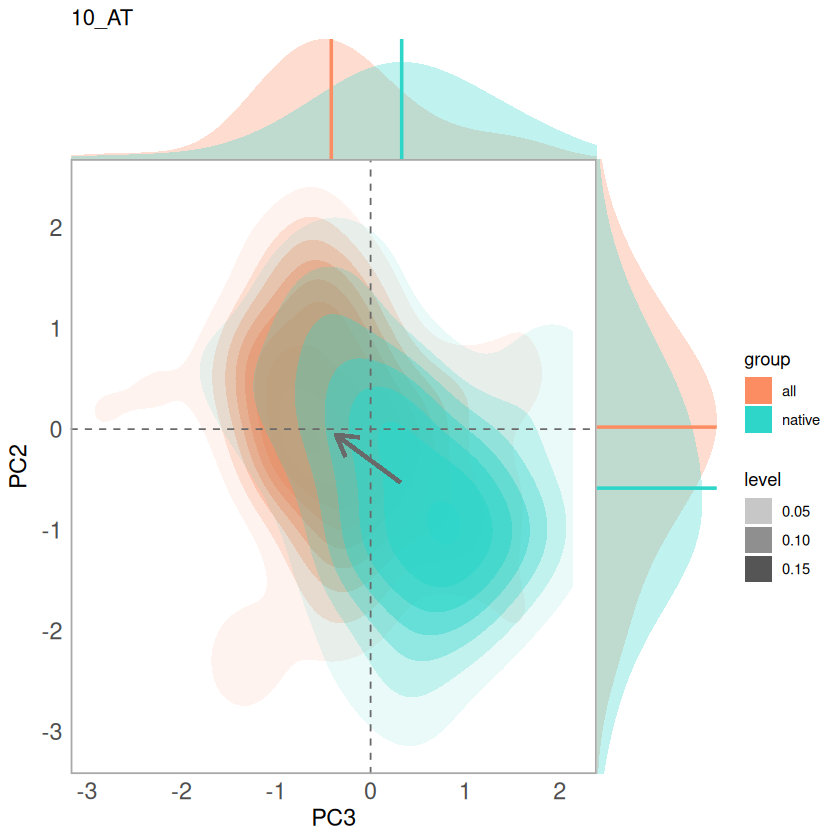

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


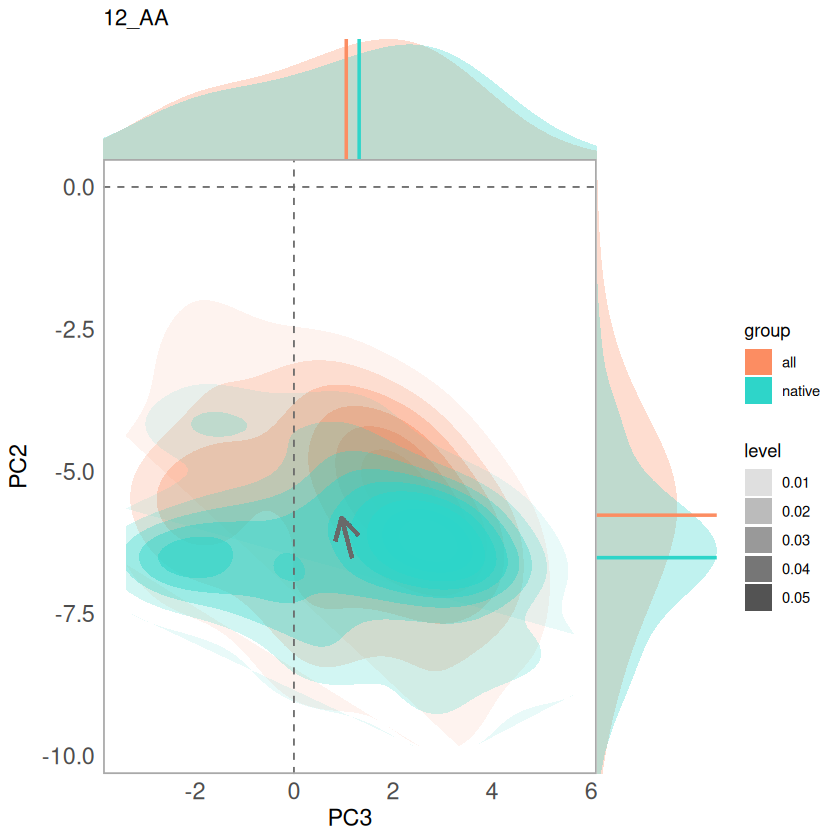

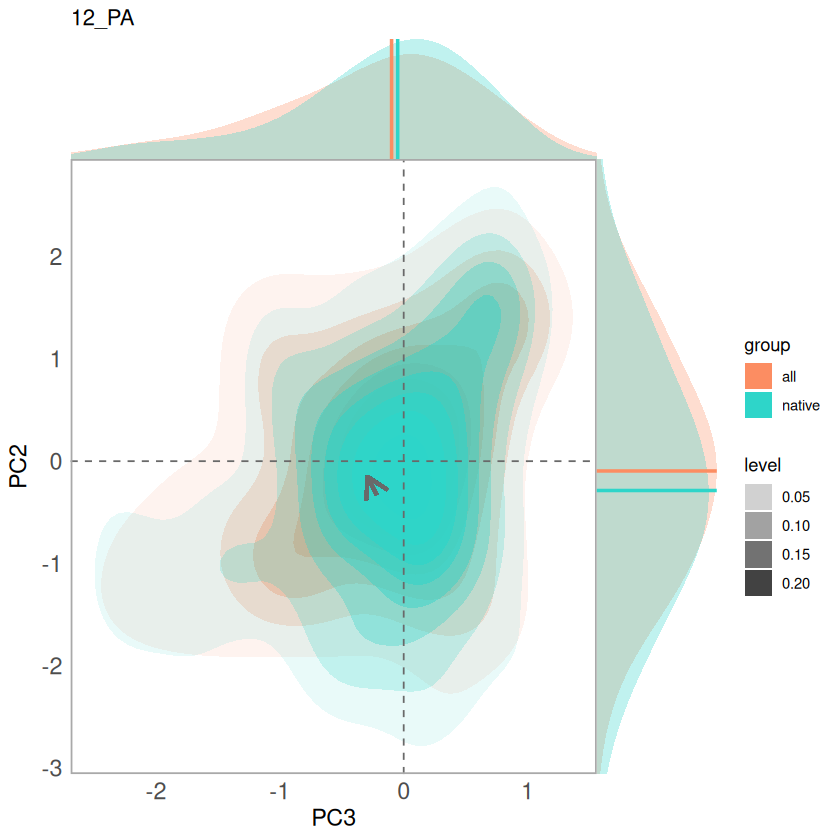

polygon has holes

Warning message:
“Removed 17 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”


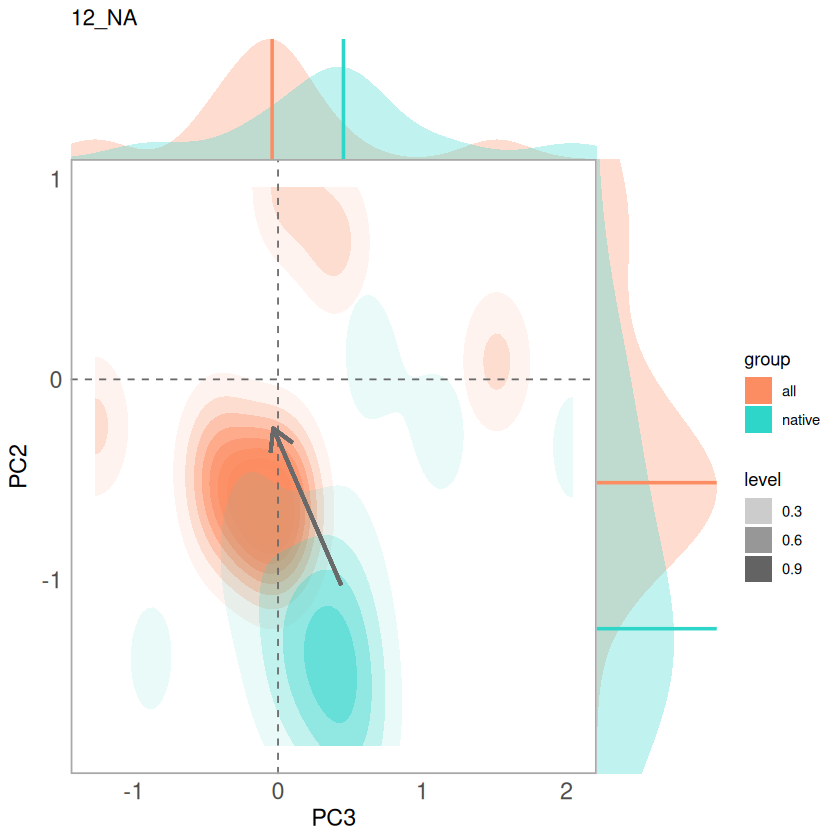

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


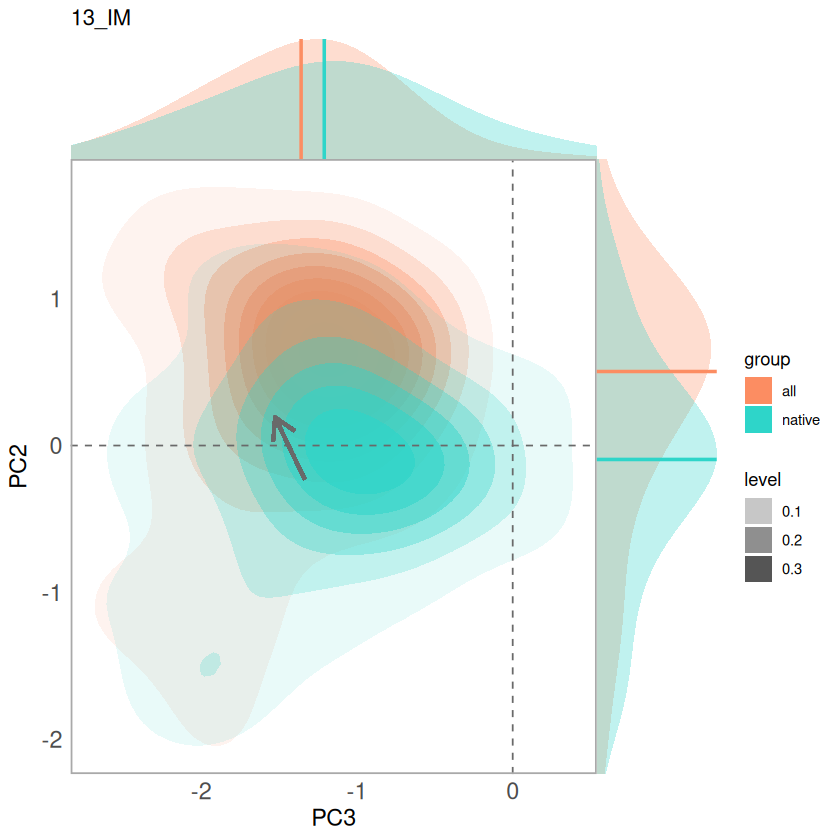

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


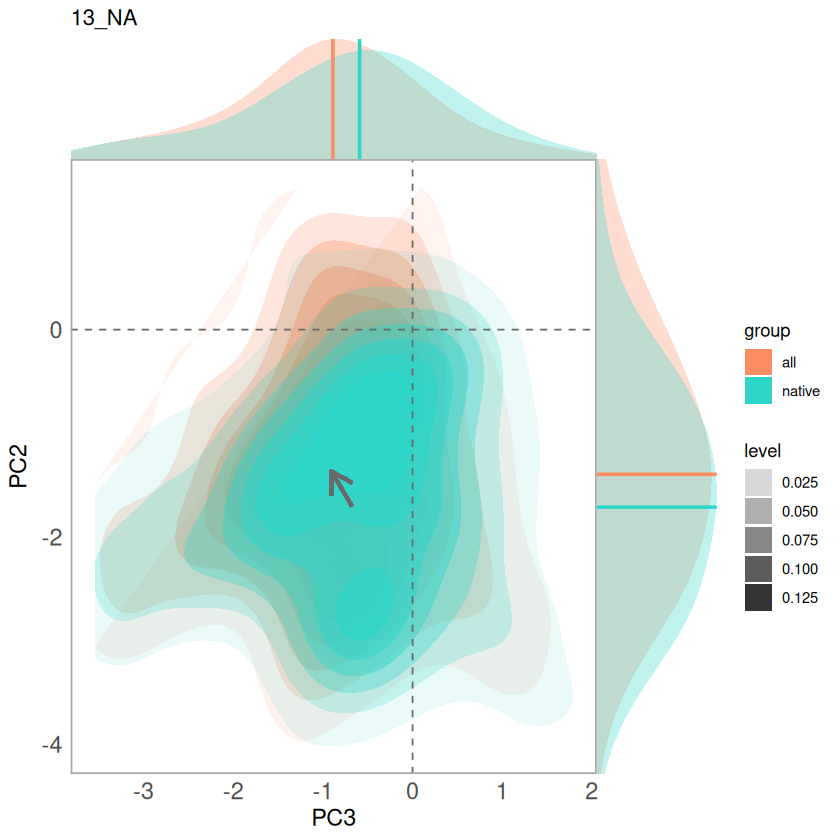

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 52 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 36 rows containing non-finite outside the scale range
(`stat_density()`).”


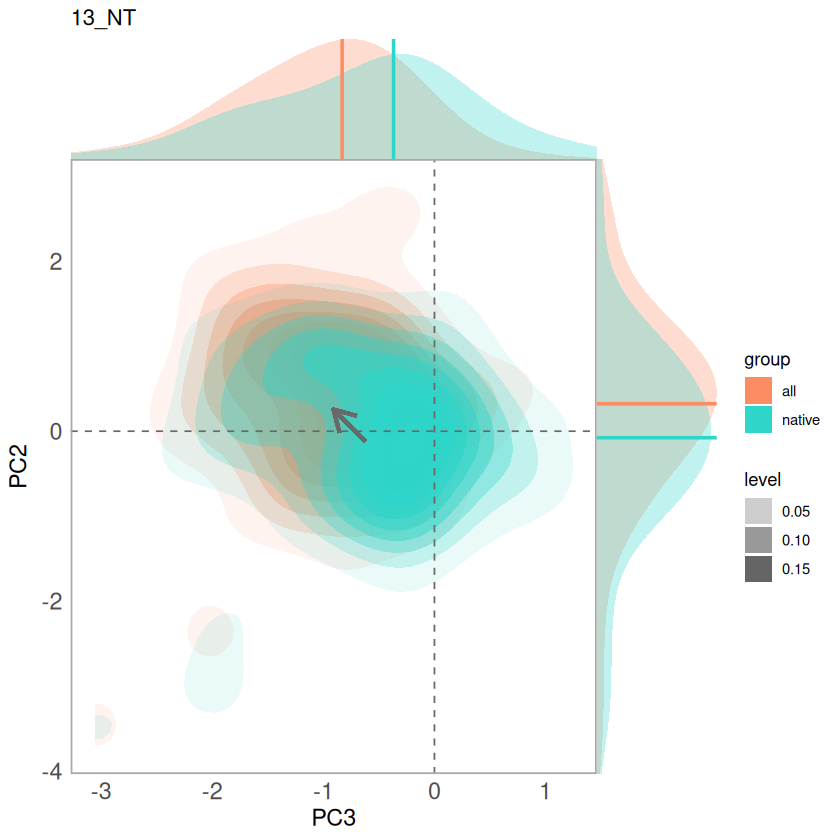

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 67 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 79 rows containing non-finite outside the scale range
(`stat_density()`).”


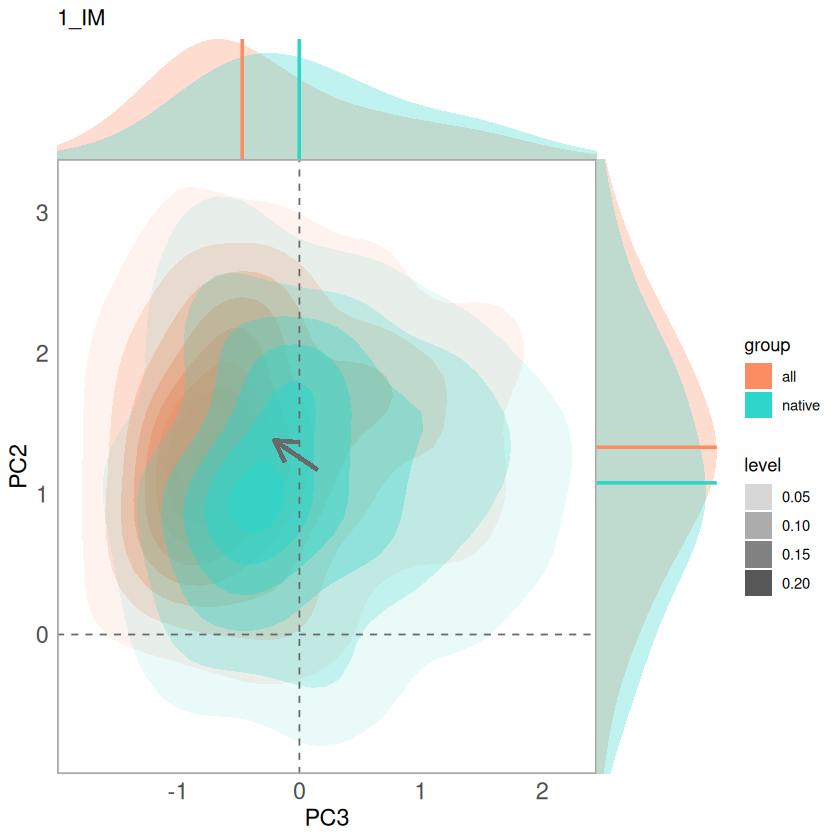

polygon has holes

Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_density()`).”


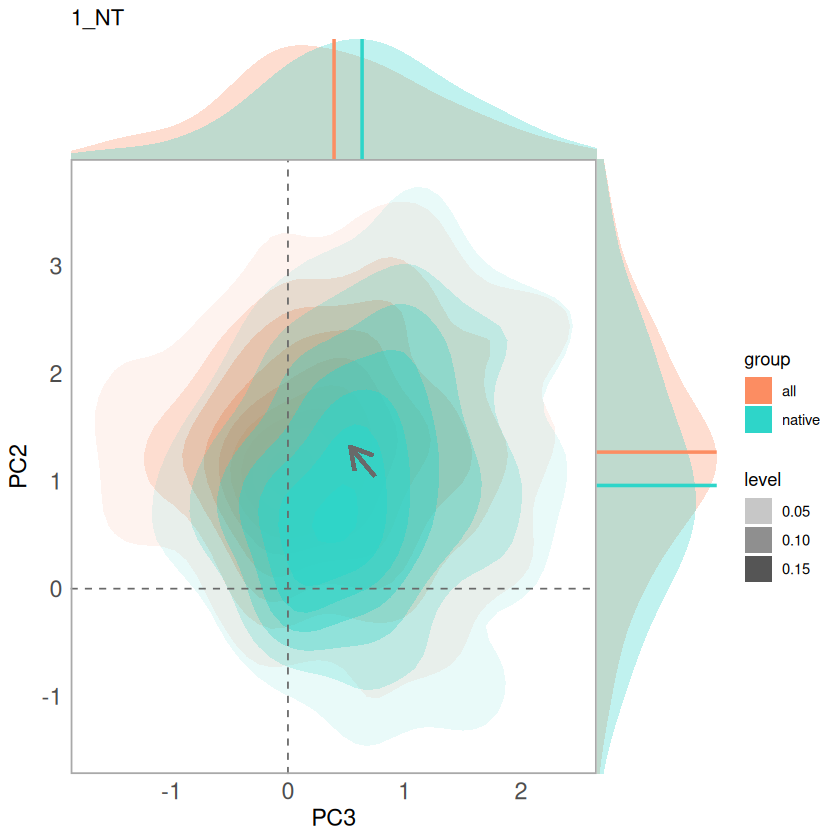

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


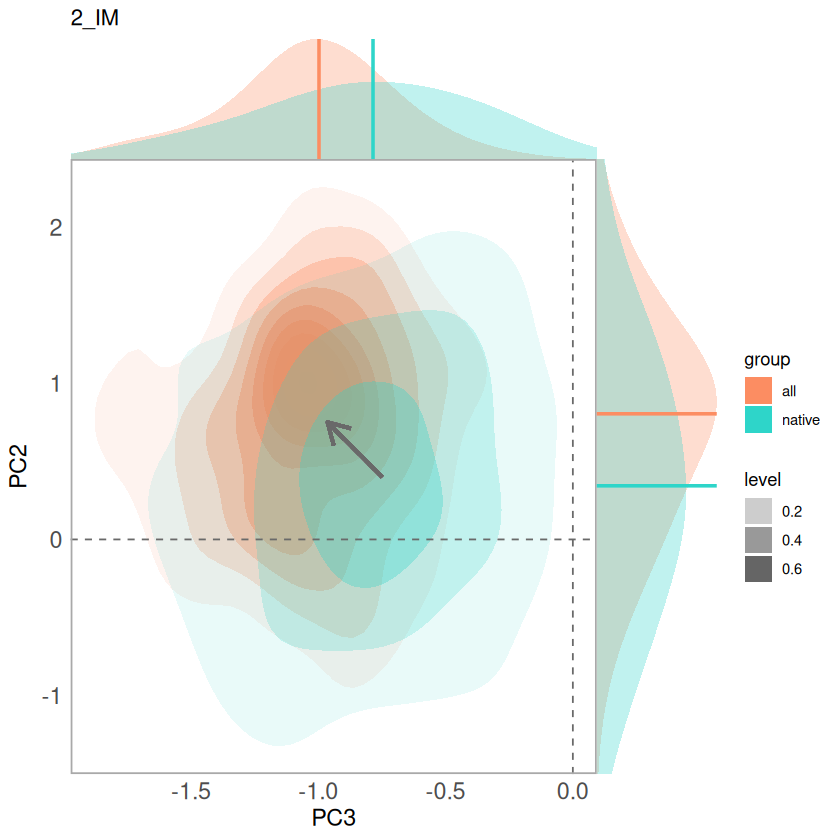

polygon has holes



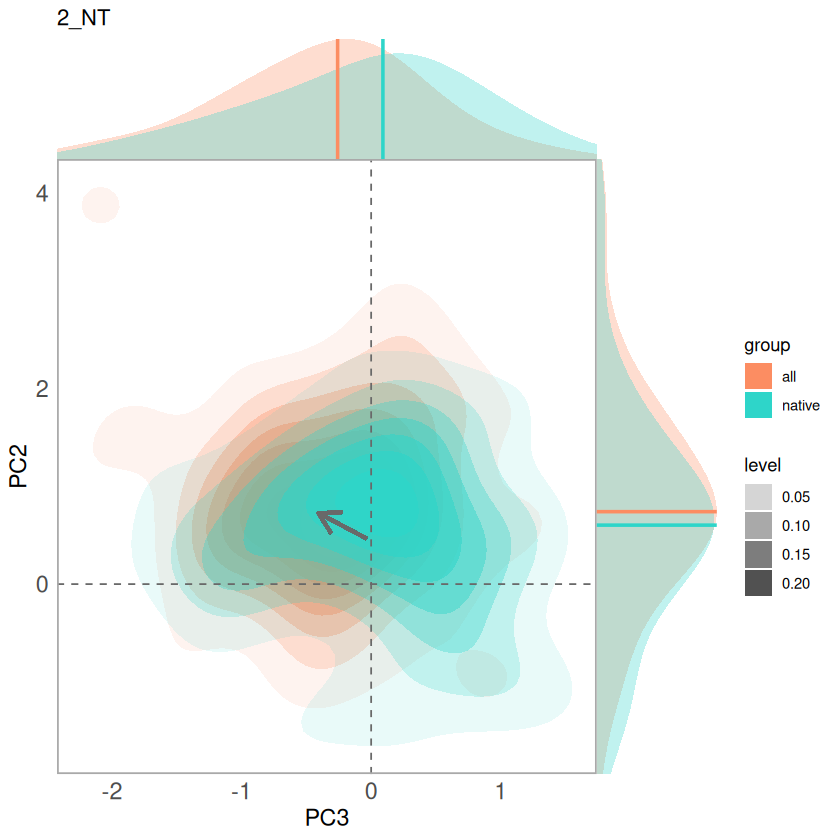

polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_density()`).”


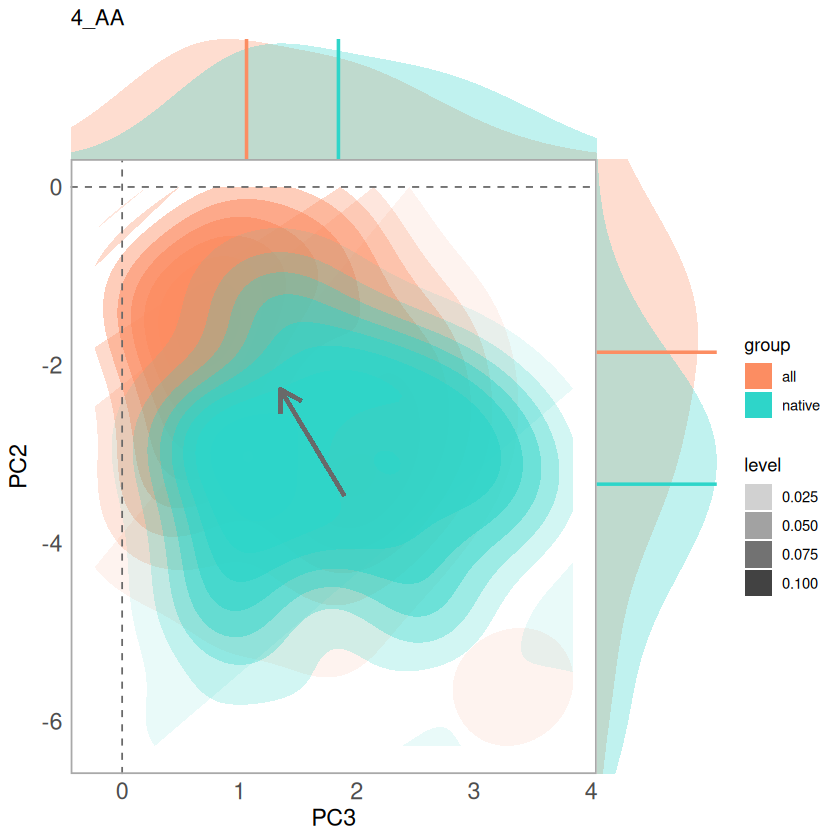

polygon has holes



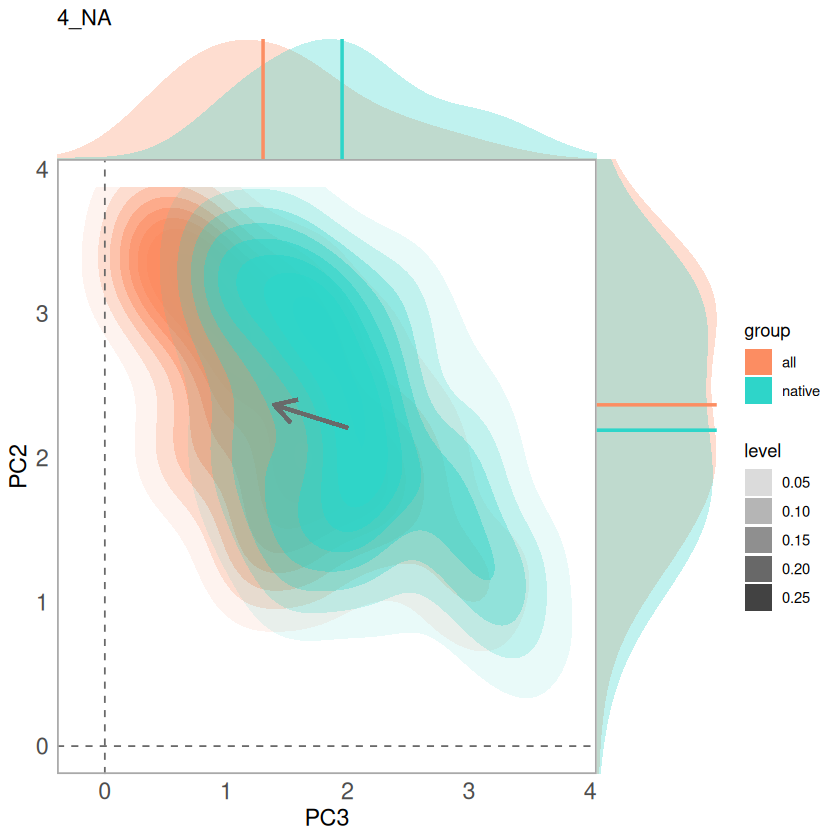

polygon has holes

polygon has holes

Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range
(`stat_density()`).”


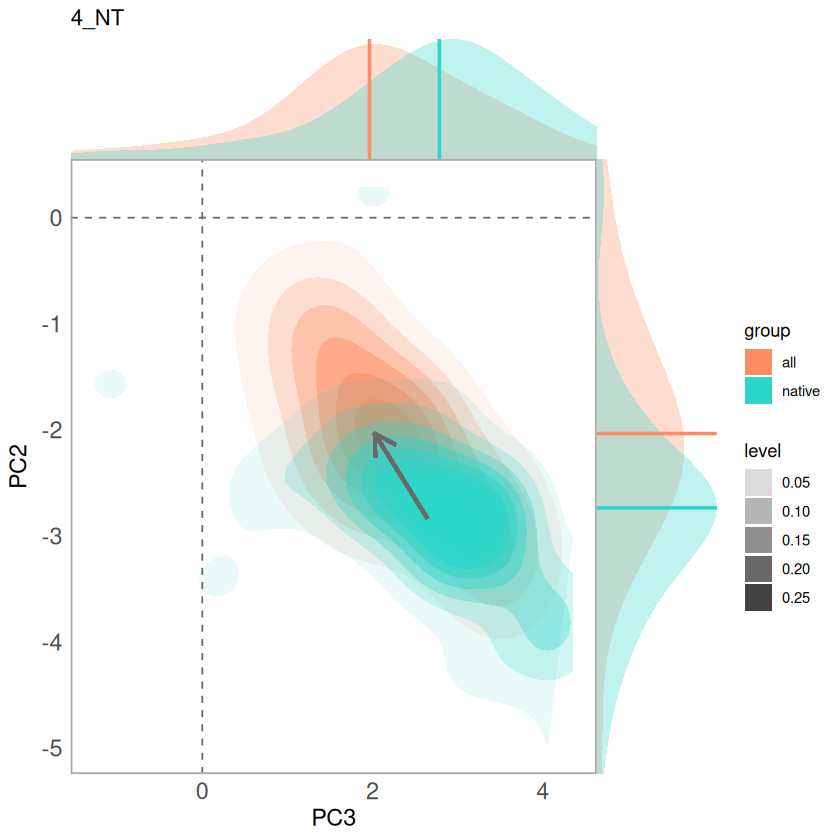

polygon has holes

Warning message:
“Removed 24 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 23 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


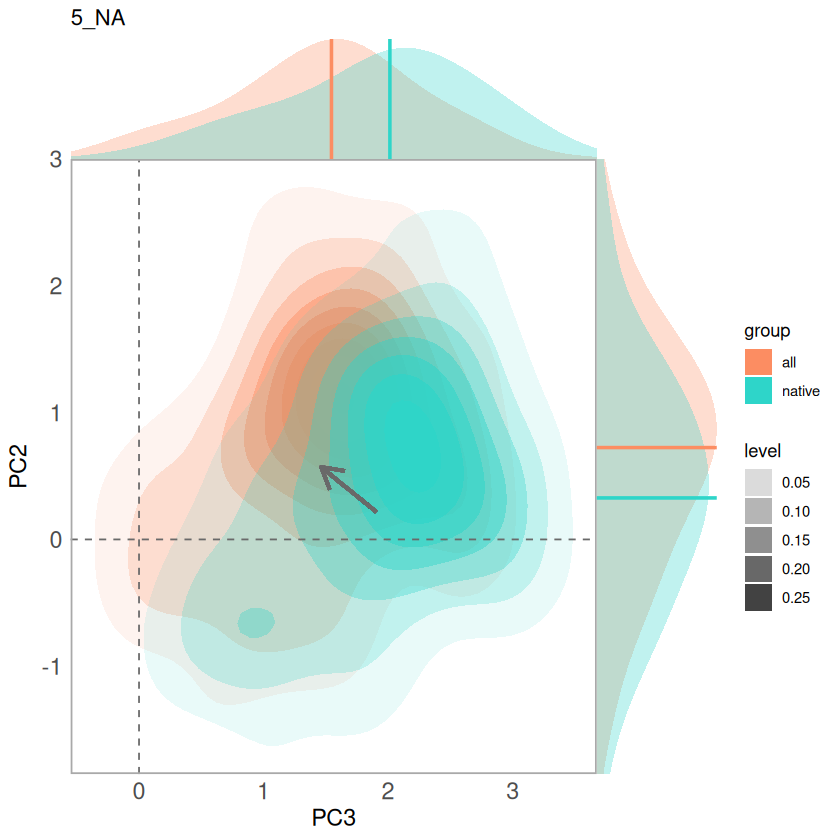

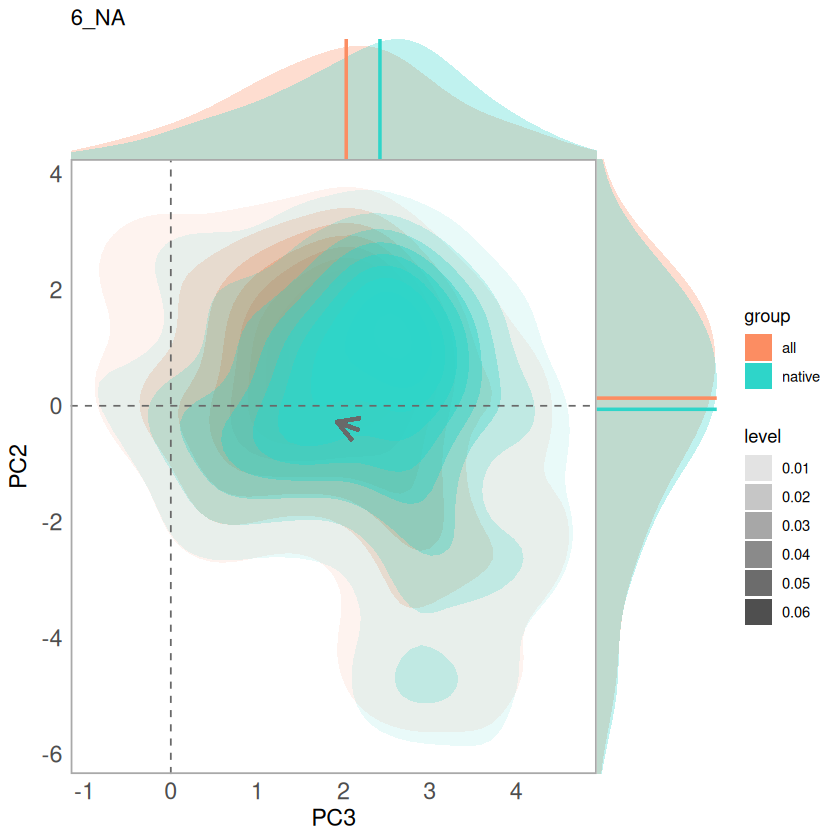

polygon has holes

polygon has holes

Warning message:
“Removed 50 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 70 rows containing non-finite outside the scale range
(`stat_density()`).”


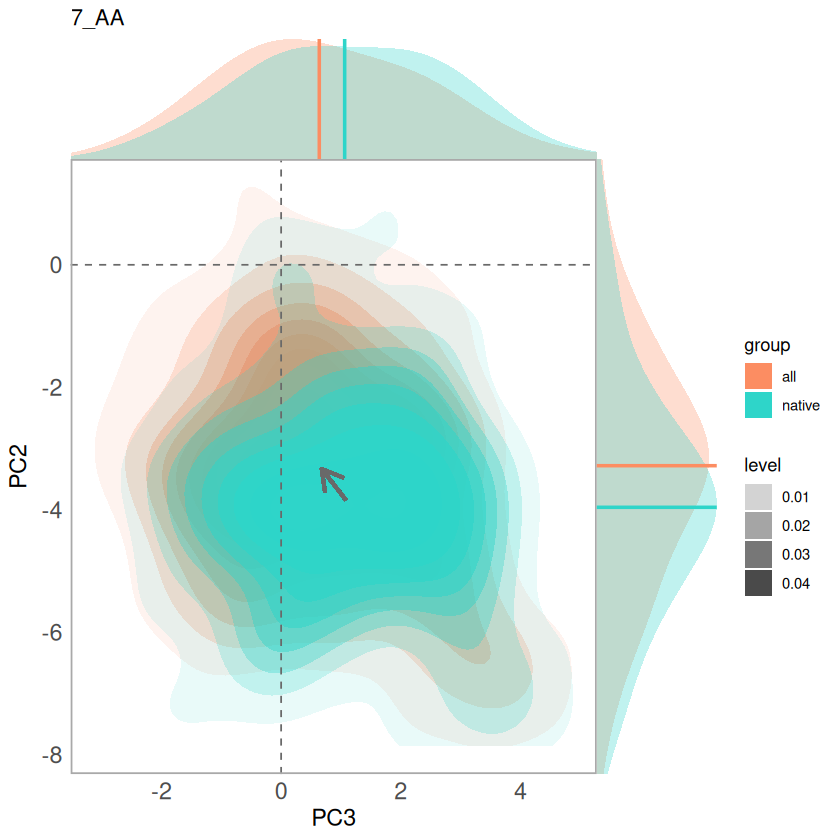

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 24 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 11 rows containing non-finite outside the scale range
(`stat_density()`).”


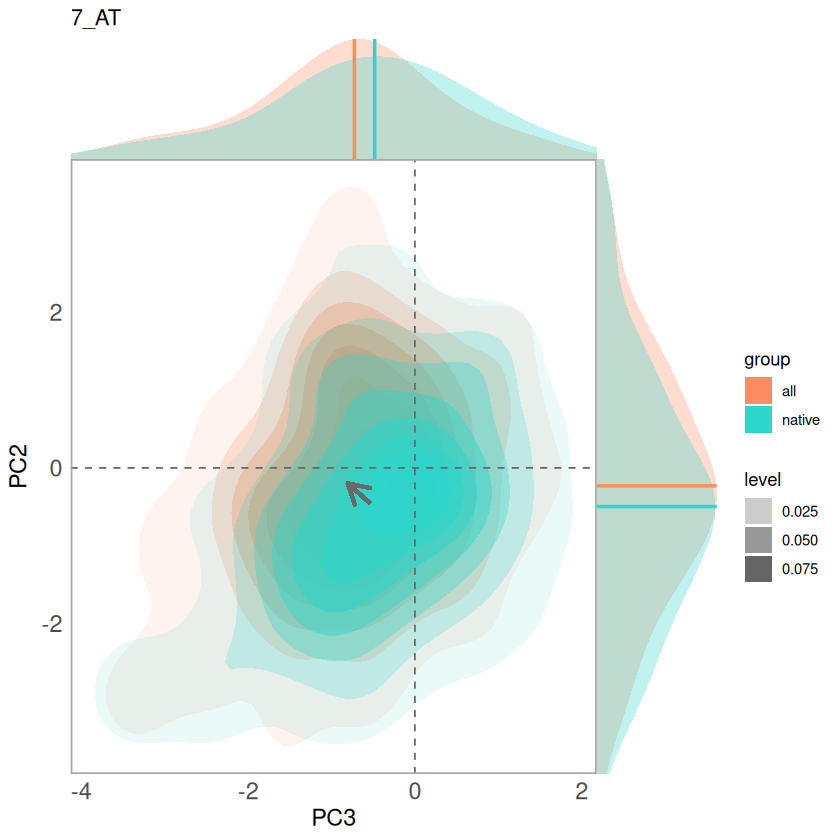

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


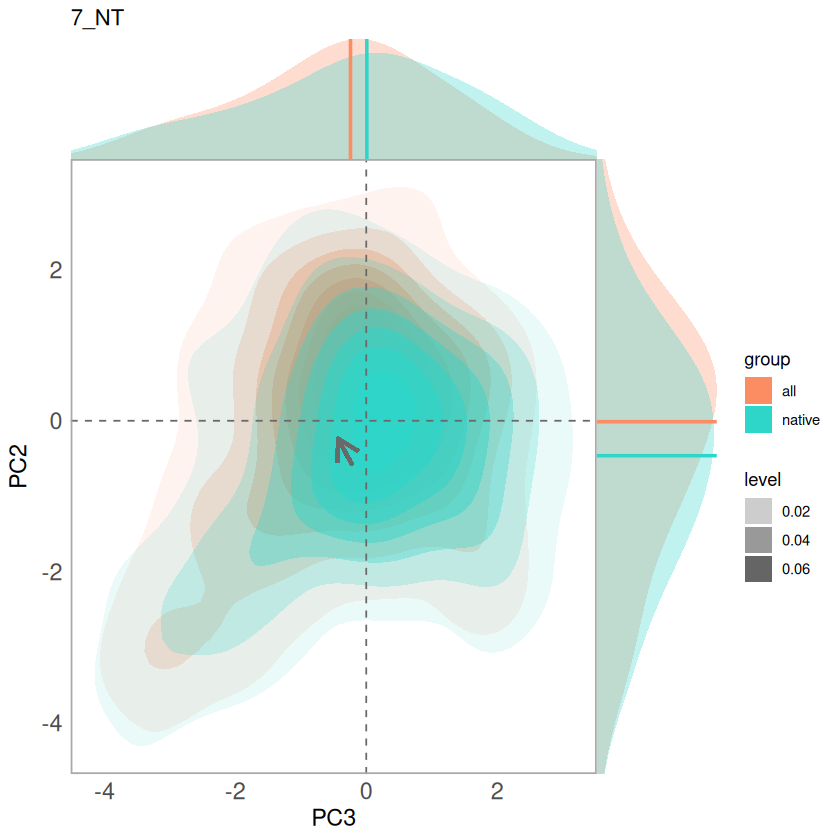

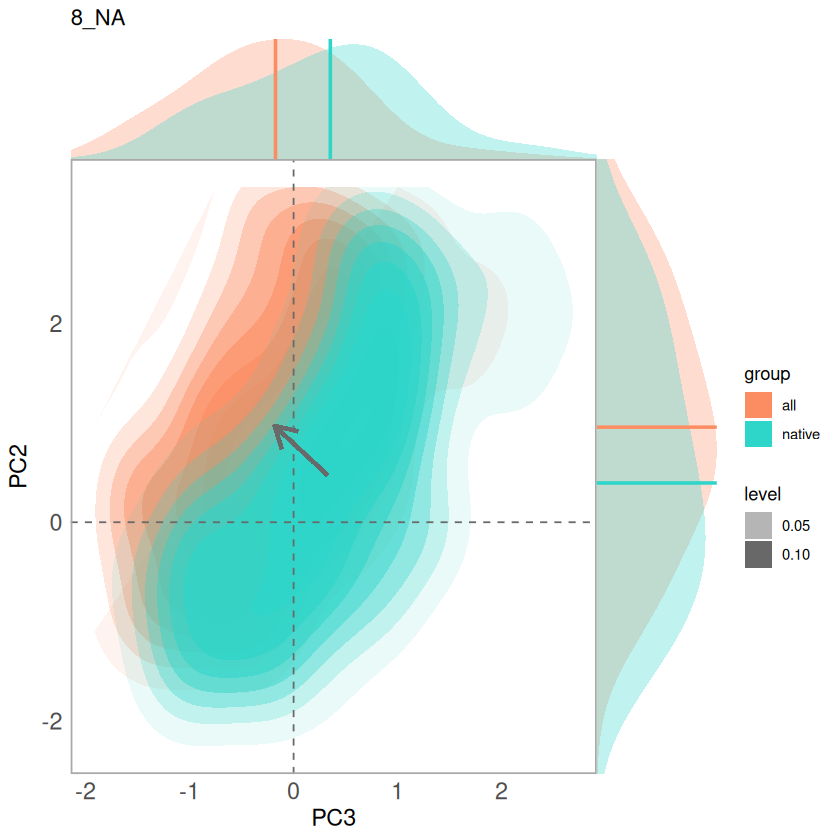

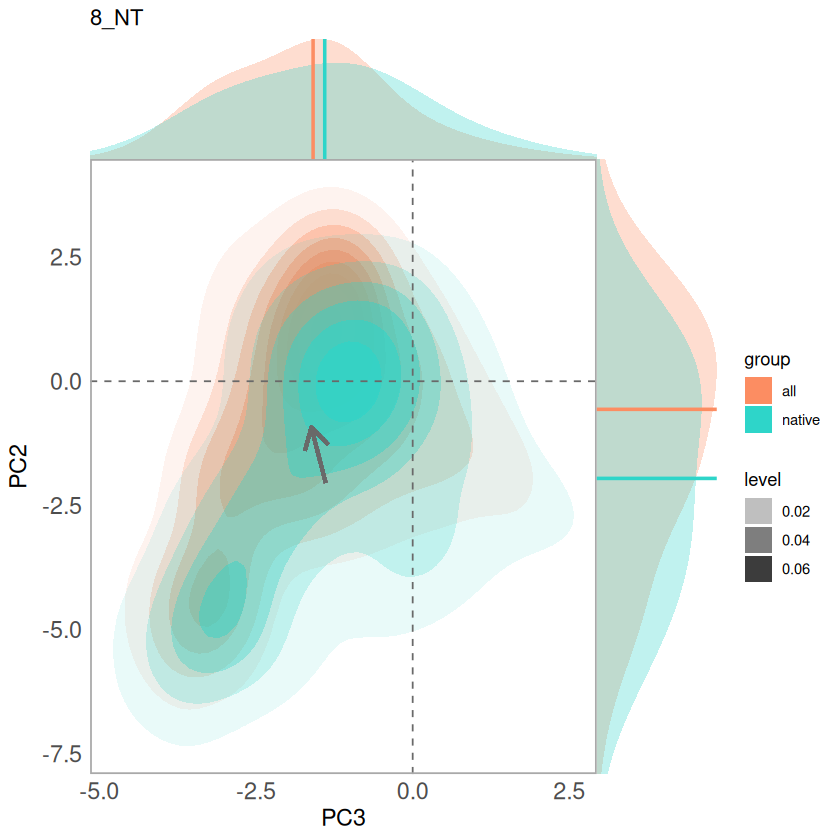

In [16]:
library(dplyr)
library(ggplot2)
library(MASS)  # for kde2d

plot_pca_points <- function(filtered_data, region_code) {
  # Centroids
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")

  centroid_native <- centroids %>% filter(group == "native")
  centroid_all <- centroids %>% filter(group == "all")

  # Function to get KDE and contour cutoff for any percentile
get_kde_cutoff <- function(df_group, percentile = 0.75) {
  kde <- with(df_group, MASS::kde2d(PC1, PC2, n = 100))
  dx <- diff(kde$x[1:2])
  dy <- diff(kde$y[1:2])
  dz <- sort(as.vector(kde$z), decreasing = TRUE)
  cumsum_dz <- cumsum(dz) * dx * dy
  cutoff <- dz[which.min(abs(cumsum_dz - percentile))]
  list(kde = kde, cutoff = cutoff)
}

# Compute KDEs for different percentiles
kdes <- list(
  all = lapply(c(0.5, 0.75, 0.9), function(p) get_kde_cutoff(filtered_data %>% filter(group == "all"), p)),
  native = lapply(c(0.5, 0.75, 0.9), function(p) get_kde_cutoff(filtered_data %>% filter(group == "native"), p))
)

# Convert to dataframes for ggplot
kde_to_df <- function(kde_obj) {
  df <- expand.grid(PC1 = kde_obj$kde$x, PC2 = kde_obj$kde$y)
  df$z <- as.vector(kde_obj$kde$z)
  df
}

df_kdes_all <- lapply(kdes$all, kde_to_df)
df_kdes_native <- lapply(kdes$native, kde_to_df)

# Line widths for 50%, 75%, 90%
line_widths <- c(1.5, 1, 0.5)  # thicker for 50%, normal for 75%, thinner for 90%

# Base plot with points
p <- ggplot(filtered_data, aes(x = PC1, y = PC2, color = group)) +
  geom_point(alpha = 0.5, size = 1.5, shape = 16) +
  geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
  geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3)

# Add contours for "all"
for (i in seq_along(df_kdes_all)) {
  p <- p + geom_contour(
    data = df_kdes_all[[i]],
    aes(x = PC1, y = PC2, z = z),
    breaks = kdes$all[[i]]$cutoff,
    color = "#fc8d62",
    linewidth = line_widths[i]
  )
}

# Add contours for "native"
for (i in seq_along(df_kdes_native)) {
  p <- p + geom_contour(
    data = df_kdes_native[[i]],
    aes(x = PC1, y = PC2, z = z),
    breaks = kdes$native[[i]]$cutoff,
    color = "#2ed5c9",
    linewidth = line_widths[i]
  )
}

# Finish plot
p <- p +
  scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
  coord_equal() +
  theme_minimal() +
  theme(panel.grid = element_blank(), legend.position = "right") +
  labs(x = "PC1", y = "PC2", color = "Group") +
  ggtitle(paste("Communities in PCA space —", region_code))

p


  # Add density curves to the sides (x and y axes)
  xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = filtered_data, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
               aes(xintercept = median_PC1, color = group),
               linetype = "solid", size = 0.5) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = filtered_data, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 0.5) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()
  
  # Combine the density plot with the density curves
  final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()
  
  # Show the final combined plot

  return(final_plot)

  #return(p)
}

regions <- merged_regions

for (i in regions) {
    f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
    region_cells <- h3::polyfill(f, res = 3)
    filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
    filtered_data <- filtered_data %>%
        mutate(PC3 = -PC3)
    sub_plot <- perform_analysis(filtered_data, f)

    
    png(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot__PC2_3_CS_log10.png"),
            width = 10, height = 7, units = "in", res = 300)
    print(sub_plot)
    dev.off()
    
    print(sub_plot)
    
}

In [ ]:
# stop jupyter kernel here
#quit(save = "no")


### Plot with gradient links 

In [ ]:
# fread "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean.csv"
gbif_summary = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean.csv")

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — CAU' in 'mbcsToSbcs': - substituted for — (U+2014)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — CNA' in 'mbcsToSbcs': - substituted for — (U+2014)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — EAU' in 'mbcsToSbcs': - substituted for — (U+2014)”


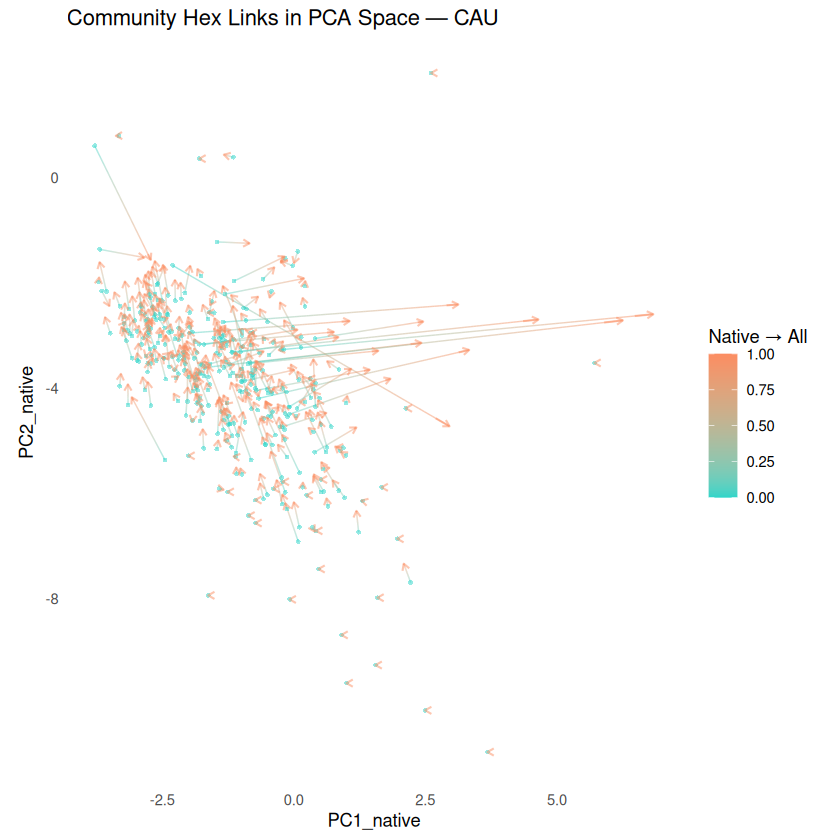

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — ENA' in 'mbcsToSbcs': - substituted for — (U+2014)”


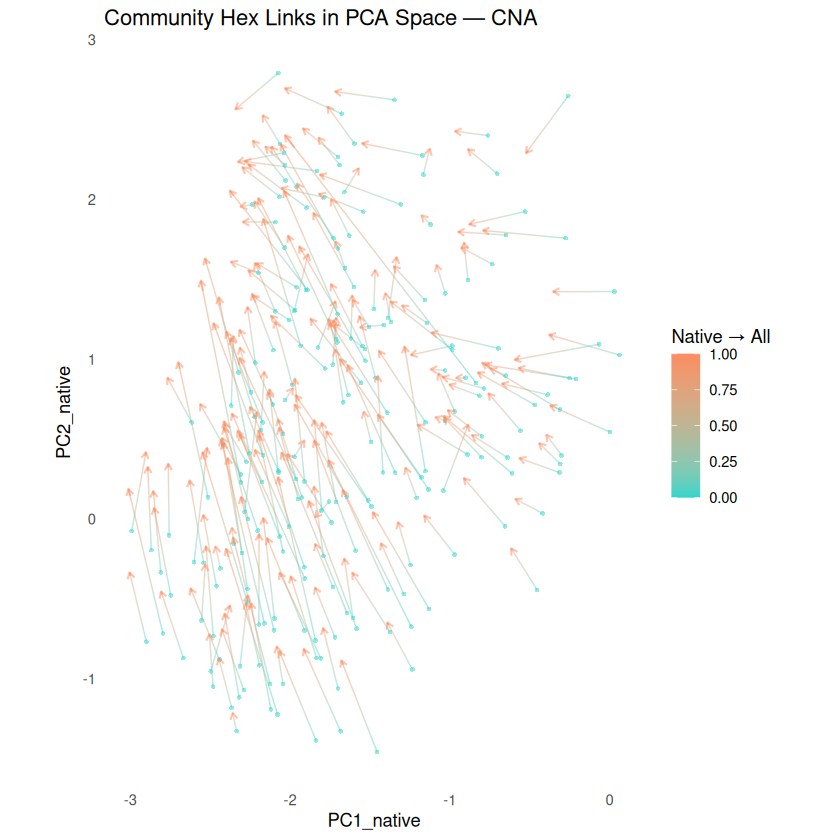

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — MED' in 'mbcsToSbcs': - substituted for — (U+2014)”


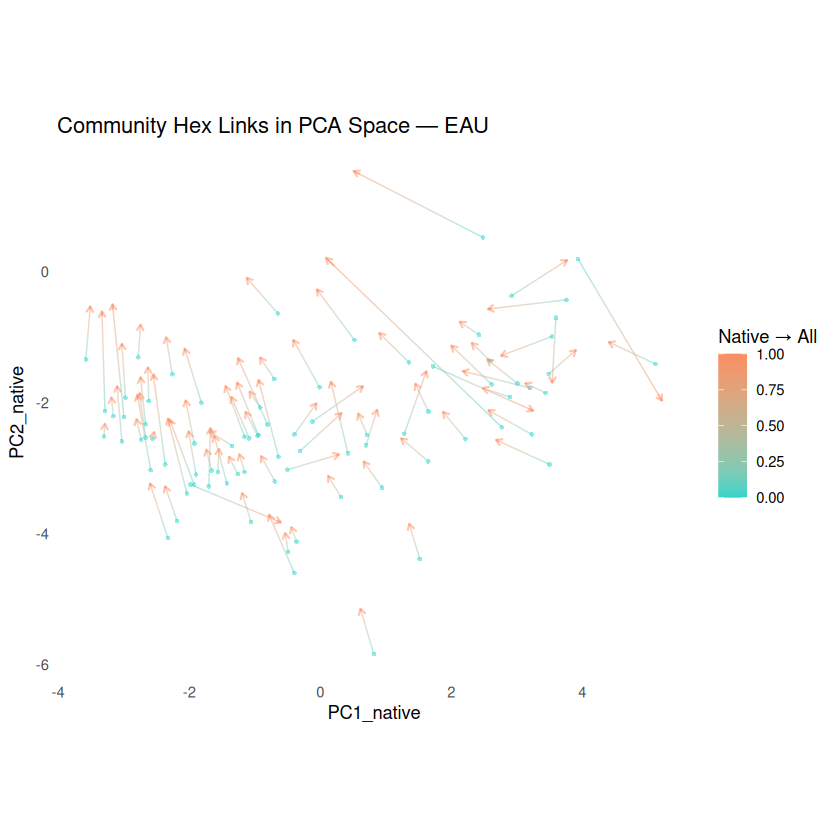

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — NAU' in 'mbcsToSbcs': - substituted for — (U+2014)”


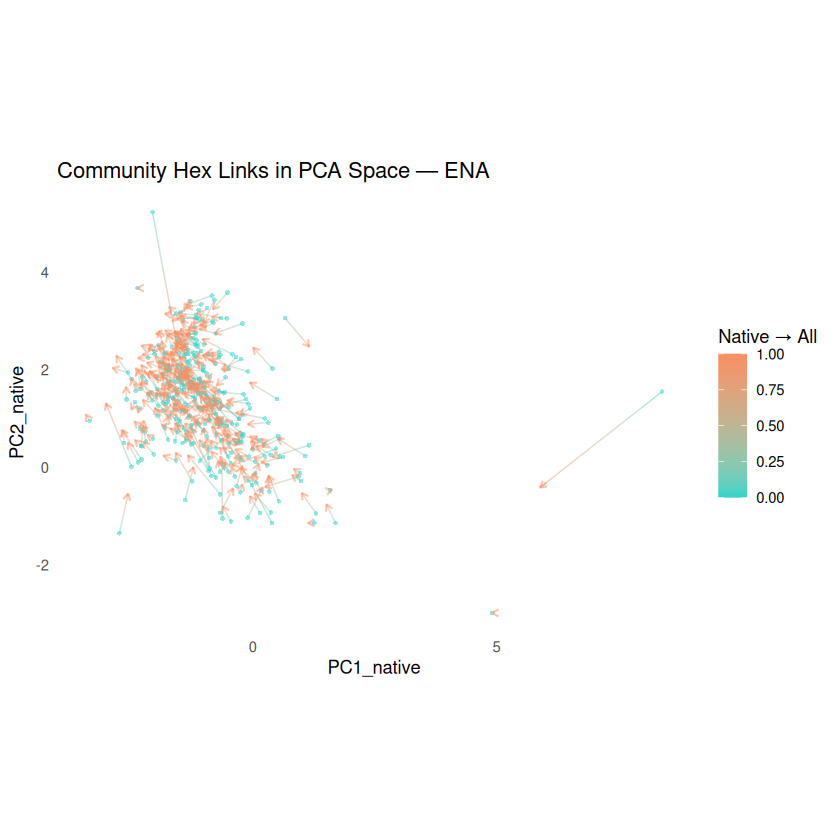

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — NCA' in 'mbcsToSbcs': - substituted for — (U+2014)”


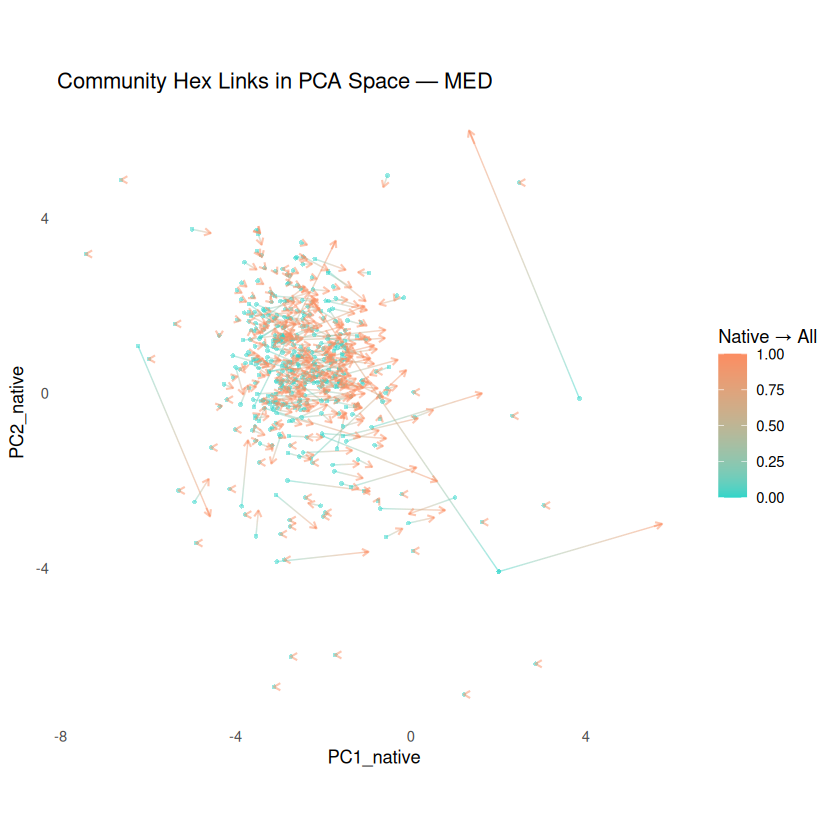

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — NEU' in 'mbcsToSbcs': - substituted for — (U+2014)”


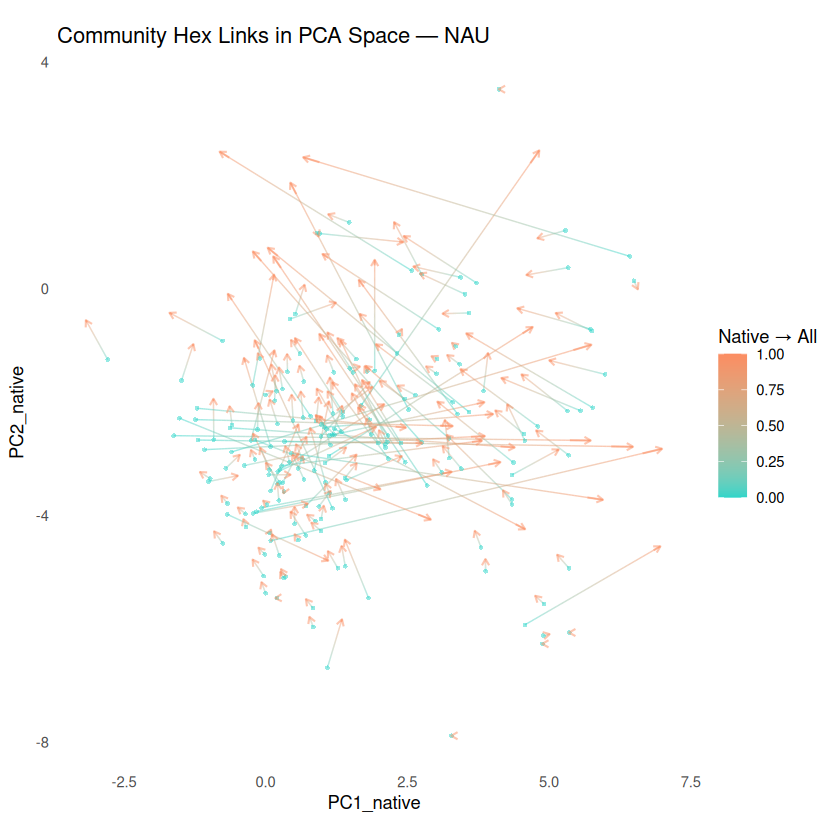

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — NZ' in 'mbcsToSbcs': - substituted for — (U+2014)”


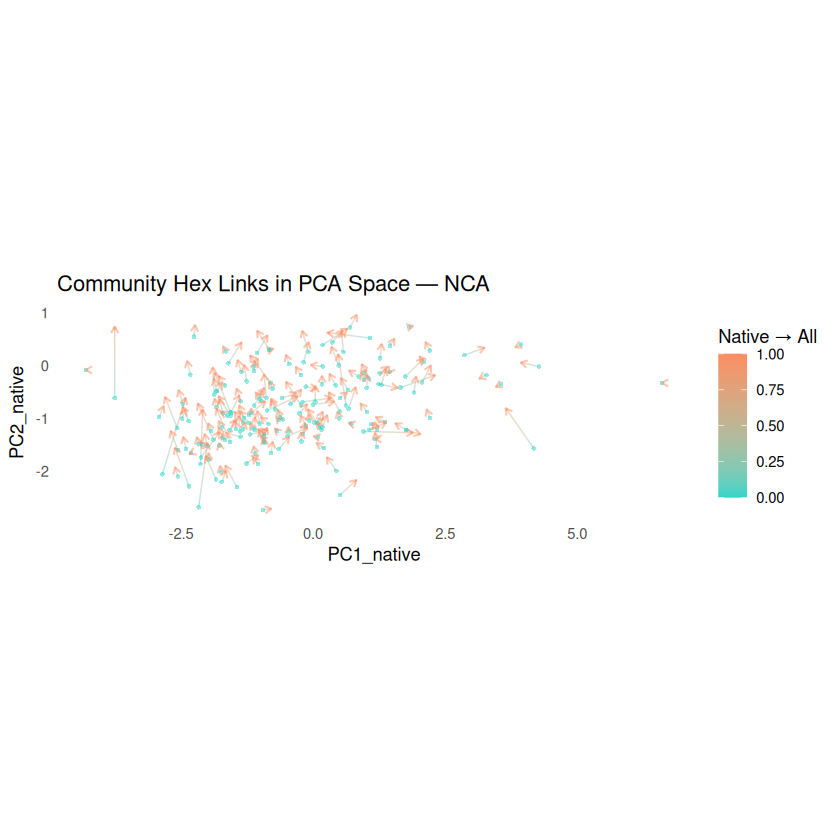

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SAS' in 'mbcsToSbcs': - substituted for — (U+2014)”


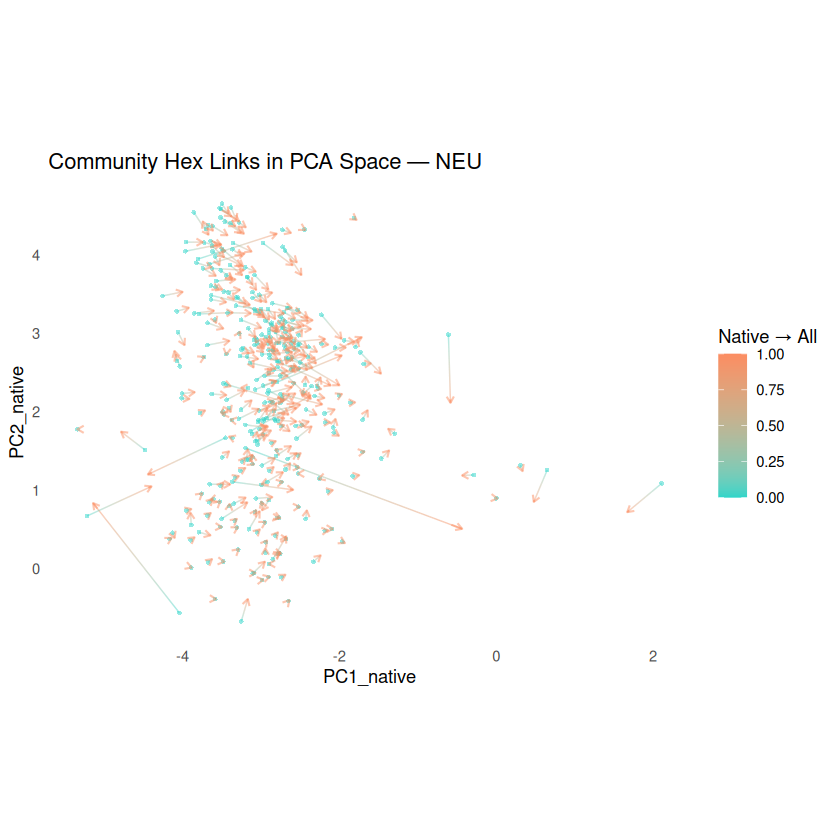

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SAU' in 'mbcsToSbcs': - substituted for — (U+2014)”


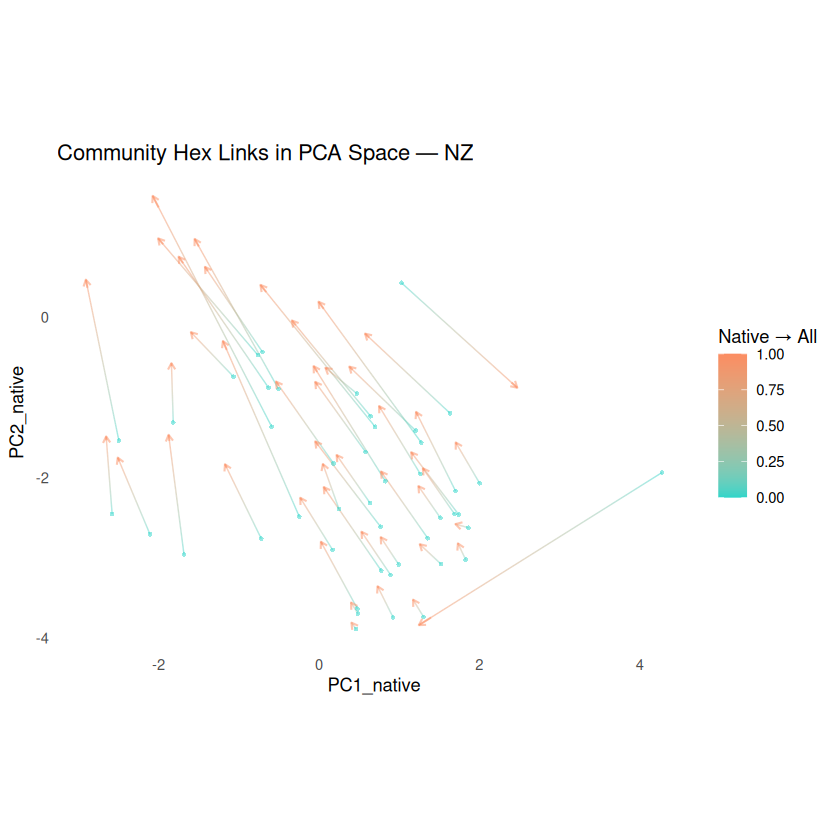

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SEA' in 'mbcsToSbcs': - substituted for — (U+2014)”


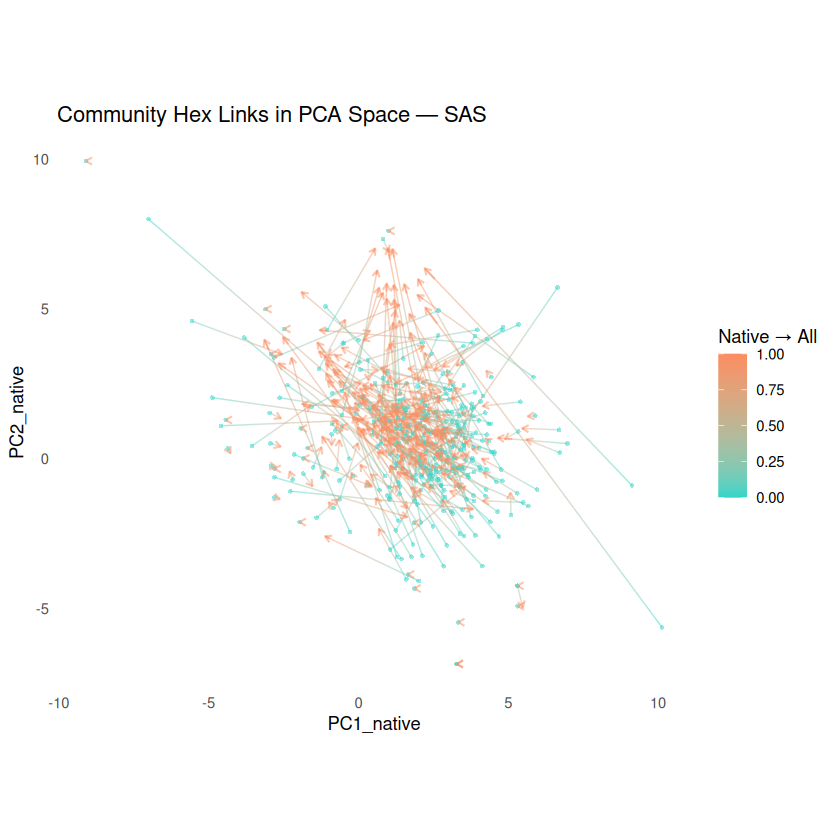

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SES' in 'mbcsToSbcs': - substituted for — (U+2014)”


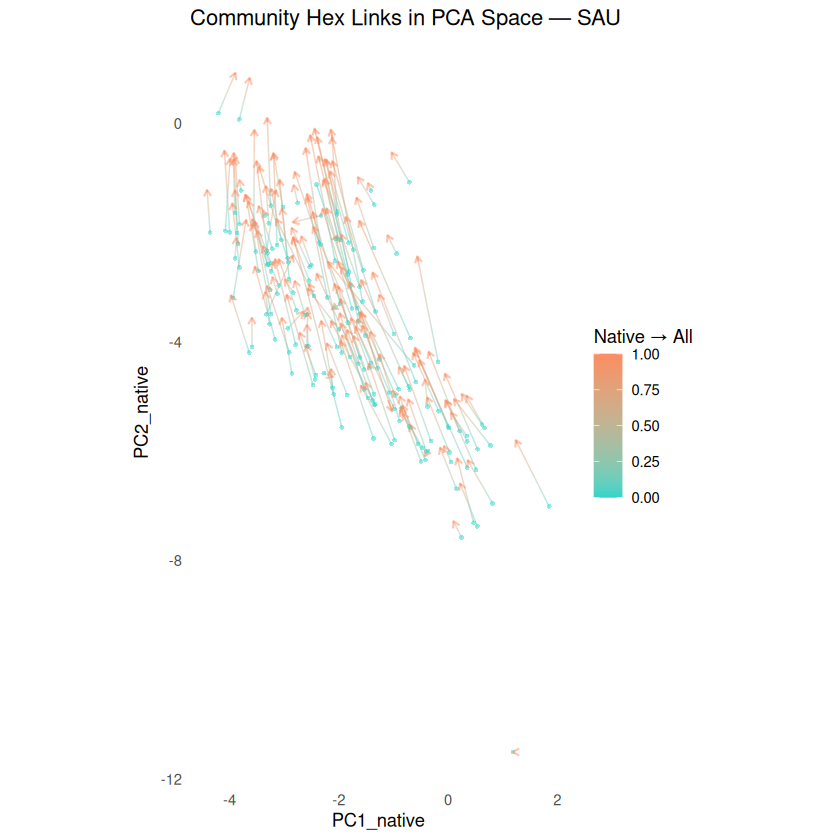

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SSA' in 'mbcsToSbcs': - substituted for — (U+2014)”


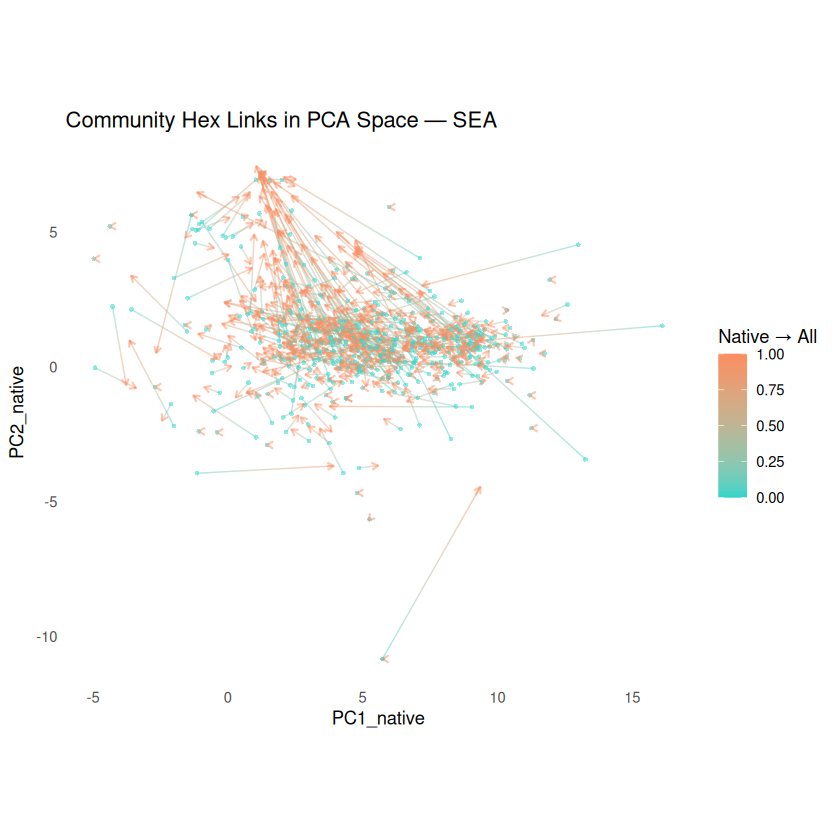

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — SWS' in 'mbcsToSbcs': - substituted for — (U+2014)”


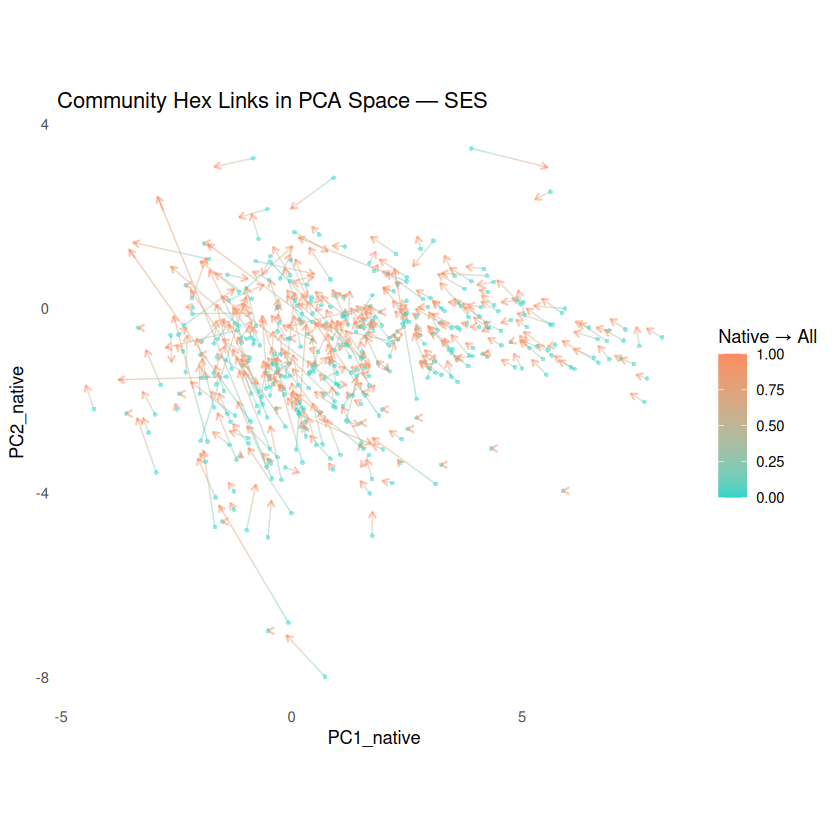

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — WCA' in 'mbcsToSbcs': - substituted for — (U+2014)”


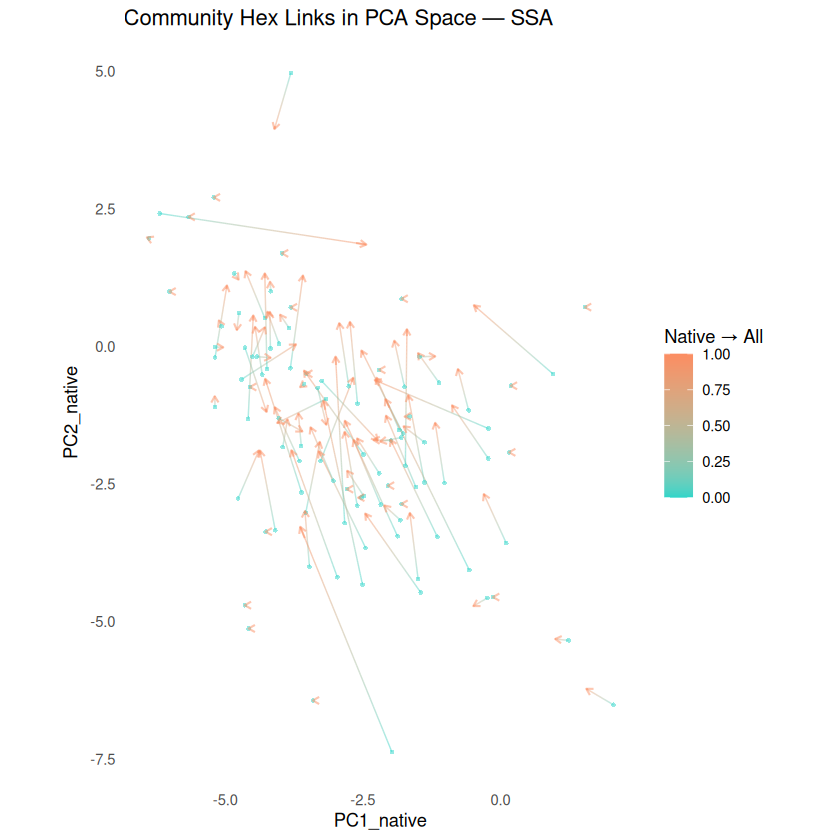

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — WCE' in 'mbcsToSbcs': - substituted for — (U+2014)”


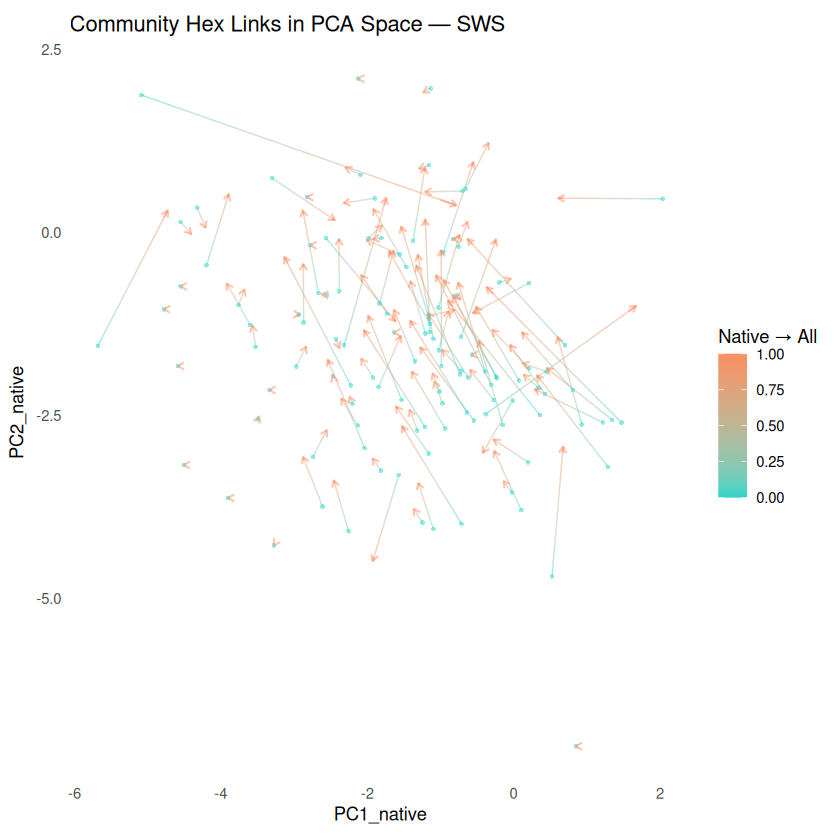

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — WNA' in 'mbcsToSbcs': - substituted for — (U+2014)”


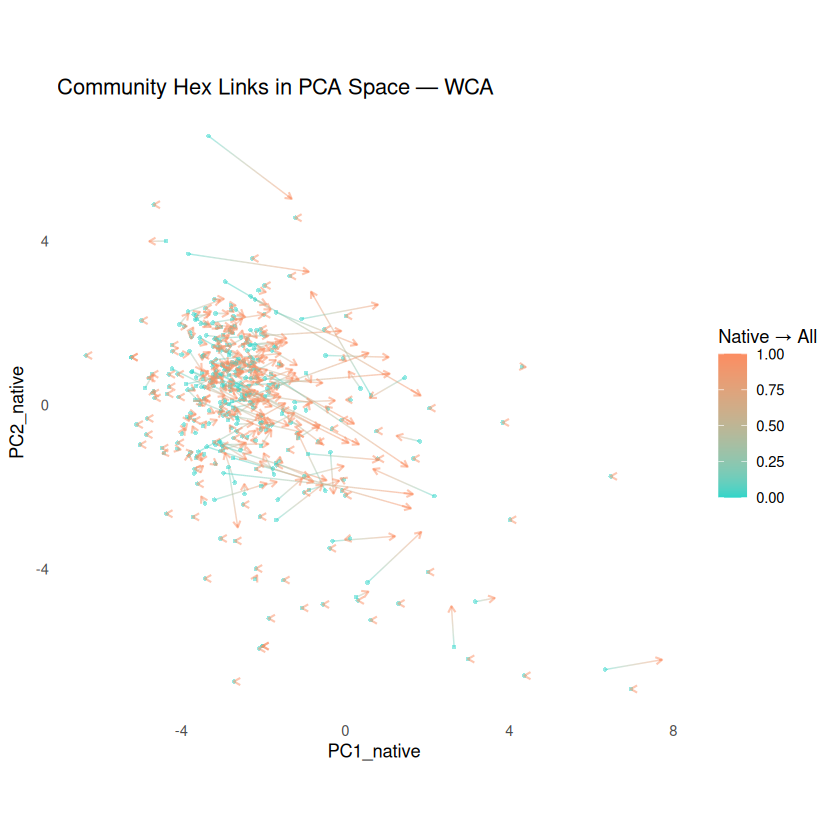

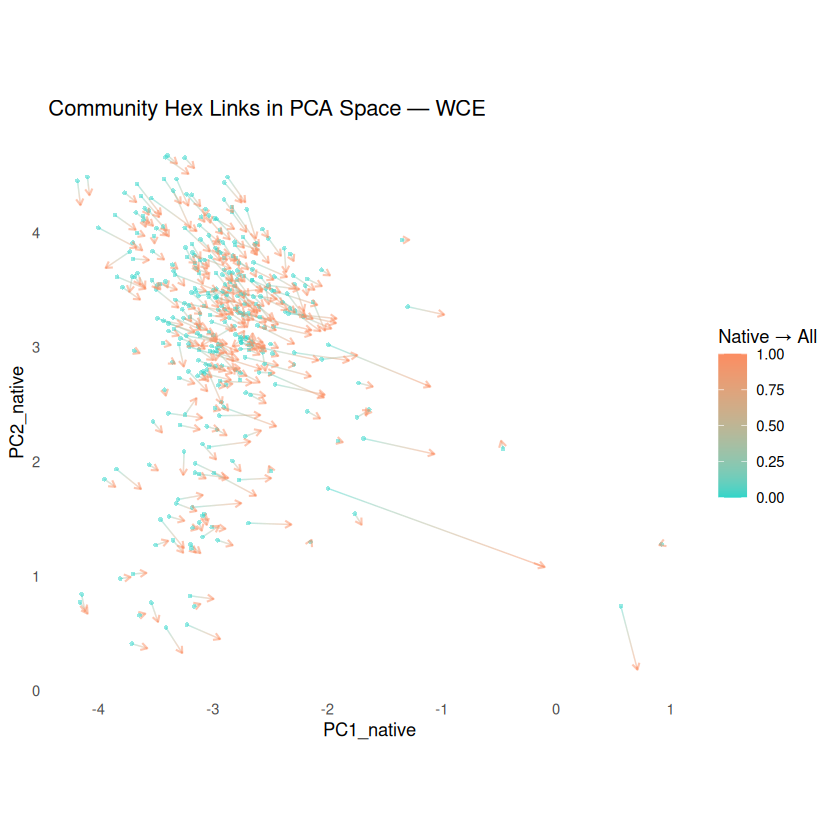

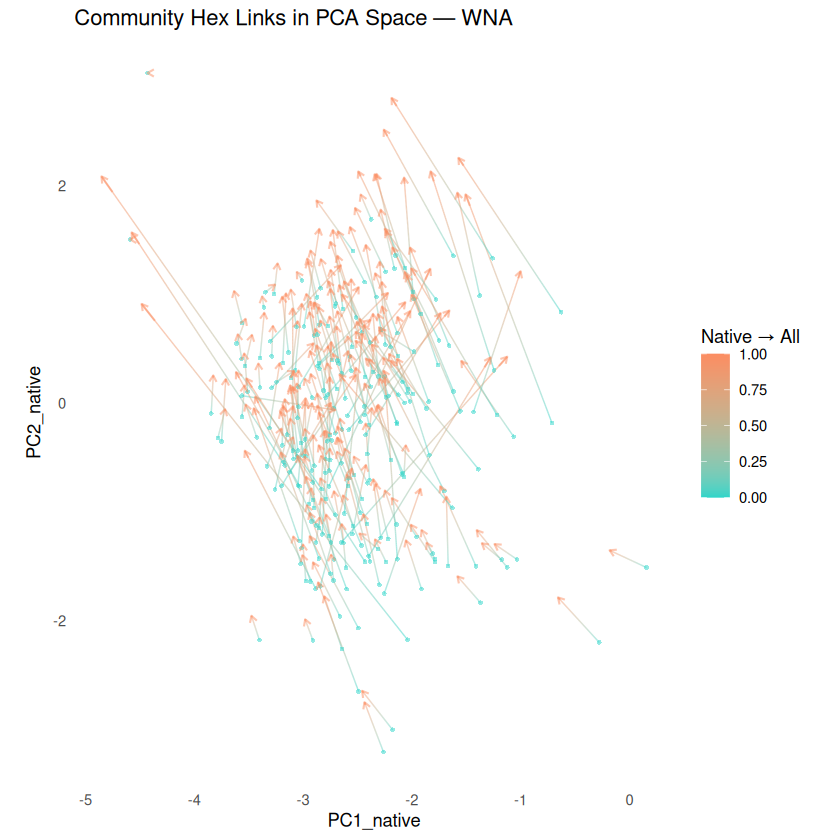

In [ ]:
library(ggplot2)
library(ggforce)
library(dplyr)
library(grid)  # for arrow()

plot_gradient_links <- function(data, region_code) {
  color_native <- "#2ed5c9"
  color_all <- "#fc8d62"

  arrow_df <- data %>%
    rowwise() %>%
    mutate(
      dx = PC1_all - PC1_native,
      dy = PC2_all - PC2_native,
      arrow_xstart = PC1_all - 0.05 * dx,
      arrow_ystart = PC2_all - 0.05 * dy,
      arrow_xend = PC1_all,
      arrow_yend = PC2_all
    ) %>%
    ungroup()

  p <- ggplot(data) +
    geom_link(
      aes(x = PC1_native, y = PC2_native,
          xend = PC1_all, yend = PC2_all,
          color = ..index..),
      linewidth = 0.4,
      alpha = 0.5
    ) +
    geom_point(
      aes(x = PC1_native, y = PC2_native),
      color = color_native,
      size = 1,
      shape = 16,
      alpha = 0.5
    ) +
    geom_segment(
      data = arrow_df,
      aes(x = arrow_xstart, y = arrow_ystart,
          xend = arrow_xend, yend = arrow_yend),
      color = color_all,
      linewidth = 0.6,
      alpha = 0.5,
      arrow = arrow(length = unit(0.06, "inches"), type = "open")
    ) +
    scale_color_gradient(low = color_native, high = color_all) +
    coord_equal() +
     theme_minimal() +
    theme(
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    labs(color = "Native → All") +
    ggtitle(paste("Community Hex Links in PCA Space —", region_code))

  return(p)
}



for (i in regions) {
  # Filter polygon for region
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]

  # Get H3 cells covering that polygon (resolution 3)
  region_cells <- h3::polyfill(f, res = 3)

  # Subset gbif_summary for these cells
  filtered_data <- gbif_summary %>%
    filter(h3_res3 %in% region_cells)

  # If you want to ensure there is data to plot:
  if (nrow(filtered_data) == 0) {
    message("No data for region ", i, ", skipping...")
    next
  }

  # Create the plot with gradient links
  sub_plot <- plot_gradient_links(filtered_data, i)

  # Save to PDF
  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/gradient_links_GBIF_wcvp", i, ".pdf"),
      width = 10, height = 7)
  print(sub_plot)
  dev.off()

  # Optionally print on screen too
  print(sub_plot)
}

In [ ]:

#### Gradient links with contours 

library(tidyr)

plot_gradient_links_with_contours <- function(gbif_data_wide, combined_data_long, region_code) {
  color_native <- "#2ed5c9"
  color_all <- "#fc8d62"

  # Prepare arrow data from wide gbif_summary
  arrow_df <- gbif_data_wide %>%
    rowwise() %>%
    mutate(
      dx = PC1_all - PC1_native,
      dy = PC2_all - PC2_native,
      arrow_xstart = PC1_all - 0.05 * dx,
      arrow_ystart = PC2_all - 0.05 * dy,
      arrow_xend = PC1_all,
      arrow_yend = PC2_all
    ) %>%
    ungroup()

  # KDE contours computed from combined_data_long (tidy with group, PC1, PC2)
  get_75pct_cutoff <- function(df_group) {
    kde <- with(df_group, MASS::kde2d(PC1, PC2, n = 100))
    dx <- diff(kde$x[1:2])
    dy <- diff(kde$y[1:2])
    dz <- sort(as.vector(kde$z), decreasing = TRUE)
    cumsum_dz <- cumsum(dz) * dx * dy
    cutoff <- dz[which.min(abs(cumsum_dz - 0.75))]
    list(kde = kde, cutoff = cutoff)
  }

  kde_all <- get_75pct_cutoff(filter(combined_data_long, group == "all"))
  kde_native <- get_75pct_cutoff(filter(combined_data_long, group == "native"))

  df_kde_all <- expand.grid(PC1 = kde_all$kde$x, PC2 = kde_all$kde$y)
  df_kde_all$z <- as.vector(kde_all$kde$z)

  df_kde_native <- expand.grid(PC1 = kde_native$kde$x, PC2 = kde_native$kde$y)
  df_kde_native$z <- as.vector(kde_native$kde$z)

  p <- ggplot(gbif_data_wide) +
    geom_link(
      aes(x = PC1_native, y = PC2_native,
          xend = PC1_all, yend = PC2_all,
          color = ..index..),
      linewidth = 0.4,
      alpha = 0.5
    ) +
    geom_point(
      aes(x = PC1_native, y = PC2_native),
      color = color_native,
      size = 1,
      shape = 16,
      alpha = 0.5
    ) +
    geom_segment(
      data = arrow_df,
      aes(x = arrow_xstart, y = arrow_ystart,
          xend = arrow_xend, yend = arrow_yend),
      color = color_all,
      linewidth = 0.6,
      alpha = 0.5,
      arrow = arrow(length = unit(0.06, "inches"), type = "open")
    ) +
    geom_contour(data = df_kde_all, aes(x = PC1, y = PC2, z = z),
                 breaks = kde_all$cutoff,
                 color = color_all,
                 linewidth = 1,
                 alpha = 0.75) +
    geom_contour(data = df_kde_native, aes(x = PC1, y = PC2, z = z),
                 breaks = kde_native$cutoff,
                 color = color_native,
                 linewidth = 1,
                 alpha = 0.75) +
    scale_color_gradient(low = color_native, high = color_all) +
    coord_equal() +
    theme_minimal() +
    theme(
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    labs(color = "Native → All") +
    ggtitle(paste("Community Hex Links + 75% Contours —", region_code))

  return(p)
}

for (i in regions) {
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]
  region_cells <- h3::polyfill(f, res = 3)

  filtered_gbif <- gbif_summary %>%
    filter(h3_res3 %in% region_cells)

  filtered_combined <- combined_data %>%
    filter(h3_res3 %in% region_cells)

  if (nrow(filtered_gbif) == 0 | nrow(filtered_combined) == 0) {
    message("No data for region ", i, ", skipping...")
    next
  }

  p <- plot_gradient_links_with_contours(filtered_gbif, filtered_combined, i)

  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/gradient_links_contours_", i, ".pdf"),
      width = 10, height = 7)
  print(p)
  dev.off()

  print(p)
}


In [ ]:


```


#### Gradient lines only

```{r}

library(ggplot2)
library(ggforce)
library(dplyr)


plot_gradient_links_lines_only <- function(data, region_code) {
  color_native <- "#2ed5c9"
  color_all <- "#fc8d62"

  ggplot(data) +
    geom_link(
      aes(x = PC1_native, y = PC2_native,
          xend = PC1_all, yend = PC2_all,
          color = ..index..),
      linewidth = 0.6,
      alpha = 0.5
    ) +
    scale_color_gradient(low = color_native, high = color_all) +
    theme_minimal() +
    theme(
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    coord_equal() +
    theme_minimal() +
    labs(color = "Native → All") +
    ggtitle(paste("Community Hex Links in PCA Space —", region_code))
}


regions <- c("ENA" , "CNA", "WNA", "SAU", "SAS", "EAS", "SEA", "WCE",
             "MED", "NEU", "WSAF", "ESAF", "SWS", "SES")

for (i in regions) {
  # Filter polygon for region
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]

  # Get H3 cells covering that polygon (resolution 3)
  region_cells <- h3::polyfill(f, res = 3)

  # Subset gbif_summary for these cells
  filtered_data <- gbif_summary %>%
    filter(h3_res3 %in% region_cells)

  # If you want to ensure there is data to plot:
  if (nrow(filtered_data) == 0) {
    message("No data for region ", i, ", skipping...")
    next
  }

  # Create the plot with gradient links
  sub_plot <- plot_gradient_links_lines_only(filtered_data, i)

  # Save to PDF
  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/gradient_links_linesonly", i, ".pdf"),
      width = 10, height = 7)
  print(sub_plot)
  dev.off()

  # Optionally print on screen too
  print(sub_plot)
}


```




#### Scatter plot with centroid vector

```{r}
library(dplyr)
library(ggplot2)

plot_pca_points <- function(filtered_data, region_code) {
  # Centroids
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")

  centroid_native <- centroids %>% filter(group == "native")
  centroid_all <- centroids %>% filter(group == "all")

  # Base plot
  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, color = group)) +
    geom_point(alpha = 0.5, size = 1.5, shape = 16) +  # solid dots

    # Density contours per group (only outermost ~75% level)
    stat_density_2d(
      data = filtered_data %>% filter(group == "all"),
      aes(x = PC1, y = PC2, fill = NULL),
      color = "#fc8d62",
      linewidth = 1,
      contour = TRUE,
      bins = 2
    ) +
    stat_density_2d(
      data = filtered_data %>% filter(group == "native"),
      aes(x = PC1, y = PC2, fill = NULL),
      color = "#2ed5c9",
      linewidth = 1,
      contour = TRUE,
      bins = 2
    ) +

    # Arrow from native to all
    geom_segment(
      data = NULL,
      aes(x = centroid_native$PC1, y = centroid_native$PC2,
          xend = centroid_all$PC1, yend = centroid_all$PC2),
      color = "#2F86AC", linewidth = 1, arrow = arrow(length = unit(0.2, "inches"))
    ) +

    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_equal() +
    theme_minimal() +
    theme(
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    labs(x = "PC1", y = "PC2", color = "Group") +
    ggtitle(paste("Communities in PCA space —", region_code))

  return(p)
}


# Example usage:
regions <- c("ENA", "WNA")
regions <- c("ENA" , "CNA", "WNA", "SAU", "SAS", "EAS", "SEA", "WCE", "MED", "NEU", "WSAF", "ESAF", "SWS", "SES")

for (i in regions) {
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]
  region_cells <- h3::polyfill(f, res = 3)

  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)

  sub_plot <- plot_pca_points(filtered_data, i)  # ✅ only 1 argument

  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_scatter_plot_CS.pdf"),
      width = 10, height = 7)
  print(sub_plot)
  dev.off()

  print(sub_plot)
}

```

#### Level plots with loadings

```{r}
perform_analysis <- function(filtered_data, polygon, loadings, h3_res = 3) {
  
  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, group = group)) +
    stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right") +
    ggtitle(i) +
    
    # ➡️ ADD arrows
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC1, yend = PC2),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#2F86AC", size = 0.4, inherit.aes = FALSE) +
    
    # ➡️ ADD trait labels
    geom_text(data = loadings,
              aes(x = label_x, y = label_y, label = trait),
              color = "#2F86AC", size = 3, hjust = 0.5, vjust = 0.5, inherit.aes = FALSE)

  # Add marginal densities
  xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = filtered_data, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))
  
  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = filtered_data, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Match custom colors
    coord_flip()
  
  # Combine everything
  final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()
  
  return(final_plot)
}

selected_traits <- c("X.X6.", "X.X3112.", "X.X50.", "X.X3117.", "X.X3106.", "X.X95.") # <-- trait ids

# Add rownames as a column
loadings$trait <- rownames(loadings)

# filter only selected traits
loadings_subset <- loadings %>%
  filter(trait %in% selected_traits)


for (i in regions) {
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
  sub_plot <- perform_analysis(filtered_data, f, loadings = loadings_subset)  # Pass loadings here
  #pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_loadings_biplot.pdf"),
  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_loadings_biplot_CS.pdf"),
      width = 10, height = 7)
  print(sub_plot)
  dev.off()
  print(sub_plot)
}

```

